# Uncertainty-Aware Predictive Compensation of Respiratory Motion for Delayed Robotic Intervention
### Notebook — BIDMC · target: IEEE JAC-ECC 2026

> **All target displacements and robot results in this notebook are SIMULATED.** The datasets provide physiological respiratory *surrogate* waveforms, not measured organ displacement (unless displacement ground truth is explicitly verified, which it is not here). Nothing below is physical-robot or clinical validation.

## Abstract
We study whether *predictive uncertainty* helps compensate latency in a simulated respiratory-tracking robot. A causal pipeline forecasts the respiratory surrogate 100–500 ms ahead (persistence, ridge-AR, Kalman, probabilistic LSTM/TCN, deep ensemble, split-conformal intervals), assesses calibration, drives a 1-DOF simulated actuator with five controllers under 0–500 ms observation delay, and tests whether σ warns of future tracking failure. The contribution investigated is **uncertainty-aware compensation under latency and distribution shift** — not the novelty of respiratory forecasting itself. No positive result is assumed; negative results are reported.

## Motivation: why latency and uncertainty
Sensing, communication and actuation delay mean a controller acts on stale measurements; with a ~0.2–0.5 Hz breathing cycle, a 300 ms delay is a sizeable phase error. Forecasting can compensate, but point forecasts hide *how wrong* they may be: when the forecast is unreliable (irregular breathing, artifacts, population shift) trusting it can be worse than the delayed measurement. Predictive uncertainty offers a principled way to blend forecast and measurement and to flag likely failures.

## Dataset and role
**BIDMC PPG and Respiration Database** (PhysioNet, v1.0.0): 53 recordings of ~8 minutes from ICU patients with ECG, PPG and impedance respiration; the primary respiratory waveform is the impedance-pneumography channel (its exact name is **verified from the headers at runtime**, not assumed). Manual breath annotations exist and are used descriptively. **Role:** main development dataset (subject-level split ≈ 37/8/8).

## Research questions and hypotheses
* **RQ1** forecasting accuracy at 100–500 ms · **RQ2** calibration of uncertainty and whether it grows with error · **RQ3** can σ predict future tracking failure under delay · **RQ4** does uncertainty-aware control beat reactive / predictive / fixed-blend / Kalman · **RQ5** robustness across populations.
* Hypotheses (tested, not assumed): H1: ensemble forecasts beat persistence at 300–500 ms. H2: predictive σ correlates positively with |error|. H3: σ discriminates future tracking failure better than |velocity|. H4: uncertainty-aware blending lowers tracking RMSE vs. fixed blending. H5 (subgroup): calibration degrades in the older half of subjects (exploratory).

## Pipeline
```mermaid
flowchart LR
  A[PhysioNet records + header verification] --> B[Causal band-pass + 20 Hz ZOH]
  B --> C[Subject-level split -> causal windows]
  C --> D[Forecasters: persistence / ridge / Kalman / LSTM / TCN / ensemble]
  D --> E[Uncertainty: aleatoric + epistemic + conformal]
  D --> F[Simulated target A*z -> 1-DOF robot]
  E --> G[Controllers: reactive / predictive / blend / Kalman / UA-blend]
  F --> G --> H[Tracking metrics + failure warning AUC]
  H --> I[Subject-level statistics, ablations, report]
```
Text version: `records -> preprocess(causal) -> split(subjects) -> windows -> models -> uncertainty -> simulated robot -> controllers -> failure prediction -> statistics -> report`.

## Limitations and intended contribution
Surrogate-driven simulation only; small cohorts; segments chosen for compute; conformal guarantees do not strictly hold under temporal dependence/shift. Intended contribution: a transparent, leakage-controlled, reproducible benchmark of whether uncertainty improves latency compensation and failure warning. See the generated `limitations_and_assumptions.md`.

## How to use
Set `MODE = "smoke"` for a quick debug run or `"full"` for the final experiment in the configuration cell below, then *Run all*. Every run writes to a new timestamped folder.

## Run configuration (v2)
Smoke vs. full mode, dataset limits, epochs, batch size and output directory are set here.

**Kaggle setup:** *Add Input* -> BIDMC dataset, *Accelerator* -> **GPU**, *Internet* -> ON only for the one-time `wfdb` install. The dataset is read directly from `/kaggle/input`; outputs go to `/kaggle/working/results/bidmc/<run>/` (a **new** run folder per execution; earlier runs are never overwritten). Run `MODE = "smoke"` first, then `MODE = "full"`.

**What v2 changes relative to v1 (see `AUDIT_AND_CHANGES_v2.md`):**
1. Patient identity is taken from the **documented MIMIC-II subject ID** in the dataset's own `Fix` files (not inferred from demographics); the audit table is exported.
2. **Model selection uses validation data only**; the held-out test comparison of all models is kept but labelled descriptive.
3. Two **new, clearly named uncertainty-aware controllers** (UCPC: uncertainty-scaled command-rate limit; Trigger: uncertainty-triggered constrained mode) are added next to the original blend, which is kept unchanged. All parameters are tuned on validation subjects only, and "no constraint" (== predictive) is always an available choice.
4. Command variation, saturation and mode-activation metrics; plant sensitivities (actuator time constant, command delay, actuator rate limit) and a measurement-noise sensitivity (all exploratory).
5. A real oracle-alignment test (v1's was tautological), persistence / prediction-export reproducibility tests, and a report that separates validation-selected choices from held-out test results.

The robot is **simulated**; the respiratory waveform is a surrogate target, not measured anatomical displacement.

In [1]:
# ======================= RUN CONFIGURATION (edit here) =======================
import numpy as np
MODE = "full"                    # "smoke" (quick debug) or "full" (final experiment)
SEED = 42
RESULTS_BASE = "/kaggle/working/results/bidmc"   # Kaggle: only /kaggle/working is saved as Output
DATA_DIR = "/kaggle/input/datasets/ieeeai/bidmc-ppg/bidmc-ppg-and-respiration-dataset-1.0.0"   # attached Kaggle dataset, read DIRECTLY (read-only; no copy, no download)
RESUME_RUN = None                 # e.g. "full_20260101_120000" to continue writing into an existing run
ALLOW_OVERWRITE = True           # files from earlier sessions are never overwritten unless True
RUN_RECURSIVE_WGET = False       # unused on Kaggle (dataset is attached under /kaggle/input; no download happens)

DATASET = "BIDMC"
DB_URL = "https://physionet.org/files/bidmc/1.0.0/"        # reference only (provenance); not contacted on Kaggle
DB_PAGE = "https://physionet.org/content/bidmc/1.0.0/"   # reference only (provenance); not contacted on Kaggle
EXPECTED_N_RECORDS = 53       # from documentation; only used for a warning
RESP_REGEX = r"resp"              # candidate respiratory channel names (verified against headers at runtime)
RESP_PREFERRED = r"resp"

# preprocessing
FS_MODEL = 20; FILTER_ORDER = 4; BAND = (0.1, 2.0); ALT_BANDS = [(0.05, 1.0), (0.1, 1.0), (0.1, 3.0)]
MAX_GAP_S = 0.25; FLAT_S = 2.0; WARMUP_S = 10.0; CHUNK_S = 300; MIN_SEG_S = 60; MIN_VALID_FRAC = 0.7
# windows
HIST = 100; HORIZONS_STEPS = [2, 4, 6, 8, 10]          # 5 s history; 100-500 ms at 20 Hz
# models
SIGMA_MIN = 1e-3; LR = 2e-3; WD = 1e-5; LAYERS = 1; BATCH = 256
RIDGE_ALPHAS = [1e-3, 1e-2, 1e-1, 1, 10, 100, 1000]; KF_Q = [1e-2, 1e-1, 1, 10, 100]; KF_R = [1e-3, 1e-2, 1e-1, 1]
# robot / controllers
AMPLITUDE_MM = 5.0; AMPLITUDES_MM = [2.0, 5.0, 10.0]; TAU_ACT = 0.2; D_CMD = 0; UMAX_FACTOR = 6.0; TRANSIENT_S = 1.0; MIN_RUN = 100
DELAYS_STEPS = [0, 2, 4, 6, 8, 10]                      # 0..500 ms observation delay
W_GRID = np.linspace(0, 1, 11); C_GRID = [0.25, 0.5, 1, 2, 4, 8, 16, 32, 64]   # extended: c -> infinity means 'no uncertainty gating' (== predictive)
N_CV_FOLDS = 5                    # patient-grouped K-fold over ALL analysed subjects (each subject is a test subject exactly once)
BOOT_STRIDE = 10; BOOT_SCORES = ("sigma_total", "abs_velocity", "velocity+sigma")   # failure-AUC bootstrap CIs: every 10th window (0.5 s), these scores only (point estimates use ALL windows)
ALLOW_CPU_FULL = False           # safety: MODE="full" on CPU would take many hours -> refuse unless explicitly allowed
PATIENT_GROUPING = "documented_id"   # "documented_id": MIMIC-II subject ID parsed from the dataset's Fix files (falls back to demographic_conservative if no ID is parseable) | "record": 1 record = 1 subject | "demographic_conservative"
# --- revised uncertainty-aware controllers: ALL parameters are chosen on VALIDATION subjects only; inf / q=1.0 mean "no constraint" (== predictive) and win ties ---
UCPC_RHI_MM = [float("inf"), 1.0, 2.0, 4.0]   # UCPC: command-change limit when uncertainty is low [mm per 50 ms step]
UCPC_RLO_MM = [0.1, 0.2, 0.4]                 # UCPC: command-change limit when uncertainty is high [mm per 50 ms step]
UCPC_C = [0.5, 1, 2, 4]                       # UCPC: sigma0 = c x median validation predictive sigma (same units as sigma)
TRIG_Q = [1.0, 0.95, 0.9, 0.8, 0.7, 0.5]      # Trigger: threshold = this quantile of validation sigma (1.0 = never triggers)
TRIG_RC_MM = [0.1, 0.2, 0.4, 0.8]             # Trigger: constrained-mode command-change limit [mm per 50 ms step]
# --- exploratory plant / measurement sensitivities (parameters tuned on the NOMINAL plant are kept: a robustness test) ---
TAU_SENS = [0.1, 0.4]; DCMD_SENS = [1, 2]; PLANT_RATE_SENS_MM = [0.3, 0.6]; NOISE_SENS = [0.05, 0.1, 0.2]   # tau [s]; command delay [steps]; actuator rate limit [mm/step]; noise SD as a fraction of the normalised signal SD
EPS_FRAC = 0.2; EPS_SENS = [0.1, 0.2, 0.3]; FAIL_CTRLS = ["predictive", "reactive", "uncertainty_aware"]

MODE_SETTINGS = {
    "smoke": dict(EPOCHS=3, ENS_SIZE=2, HIDDEN=32, TCN_CH=16, TRAIN_STRIDE=5, N_BOOT=100, N_BOOT_FAIL=30, PATIENCE=2, VAL_SUB=4, MAX_RECORDS=14),
    "full":  dict(EPOCHS=40, ENS_SIZE=5, HIDDEN=64, TCN_CH=32, TRAIN_STRIDE=2, N_BOOT=1000, N_BOOT_FAIL=300, PATIENCE=6, VAL_SUB=2, MAX_RECORDS=None),
}
globals().update(MODE_SETTINGS[MODE])
CFG_ALL = {k: (v.tolist() if hasattr(v, "tolist") else v) for k, v in dict(globals()).items() if k.isupper() and not k.startswith("_")}
print("MODE =", MODE, {k: MODE_SETTINGS[MODE][k] for k in ("EPOCHS", "ENS_SIZE", "TRAIN_STRIDE")})

MODE = full {'EPOCHS': 40, 'ENS_SIZE': 5, 'TRAIN_STRIDE': 2}


# Section B — Environment setup
Installs/imports packages, checks CUDA/RAM, fixes random seeds, creates a **new timestamped results directory** (nothing is overwritten silently) and defines logging/saving helpers.

In [2]:
# Kaggle: wfdb is not preinstalled. Internet must be ON (Notebook settings -> Internet) ONLY for this one-time install;
# every other package used below (torch, scipy, sklearn, statsmodels, seaborn, tqdm, psutil) is already on Kaggle.
import importlib.util
if importlib.util.find_spec("wfdb") is None:
    get_ipython().run_line_magic("pip", "install -q wfdb")
else:
    print("wfdb already installed")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 3.9 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, sys, json, time, math, re, random, platform, warnings, datetime, shutil
from pathlib import Path
import numpy as np, pandas as pd
import scipy, scipy.signal as sps
from scipy import stats as sstats
from scipy.linalg import solve_discrete_are
import matplotlib, matplotlib.pyplot as plt, seaborn as sns
import sklearn
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             brier_score_loss, confusion_matrix)
import statsmodels
from statsmodels.stats.multitest import multipletests
import wfdb, requests, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm
from IPython.display import display, Markdown
try:
    import psutil
except ImportError:
    psutil = None

warnings.filterwarnings("default")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed: int) -> None:
    """Seed python, numpy and torch (deterministic as far as practical)."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
set_seed(SEED)

ENV = dict(python=sys.version.split()[0], platform=platform.platform(), numpy=np.__version__, pandas=pd.__version__,
           scipy=scipy.__version__, sklearn=sklearn.__version__, statsmodels=statsmodels.__version__, wfdb=wfdb.__version__,
           torch=torch.__version__, matplotlib=matplotlib.__version__, device=str(DEVICE),
           cuda_available=torch.cuda.is_available(),
           ram_total_gb=round(psutil.virtual_memory().total/2**30, 2) if psutil else None,
           ram_available_gb=round(psutil.virtual_memory().available/2**30, 2) if psutil else None, seed=SEED, mode=MODE)
print(json.dumps(ENV, indent=2))
if not torch.cuda.is_available():
    print("WARNING: no GPU detected -> training will be very slow. Kaggle: Settings -> Accelerator -> GPU (T4 x2 / P100), then restart.")
    if MODE == "full" and not ALLOW_CPU_FULL:
        raise RuntimeError("MODE='full' needs a GPU (CPU would take ~15 h for 5-fold CV). Enable Accelerator -> GPU and restart, "
                           "or set ALLOW_CPU_FULL=True / MODE='smoke' in the config cell.")


{
  "python": "3.13.15",
  "platform": "Linux-6.18.48+-x86_64-with-glibc2.39",
  "numpy": "2.1.3",
  "pandas": "2.3.3",
  "scipy": "1.16.3",
  "sklearn": "1.6.1",
  "statsmodels": "0.15.0",
  "wfdb": "4.3.1",
  "torch": "2.11.0+cu128",
  "matplotlib": "3.10.0",
  "device": "cuda",
  "cuda_available": true,
  "ram_total_gb": 31.35,
  "ram_available_gb": 29.75,
  "seed": 42,
  "mode": "full"
}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [4]:
# ---- results directory (never overwrites a previous run silently) ----
RUN_NAME = RESUME_RUN or f"{MODE}_{datetime.datetime.now():%Y%m%d_%H%M%S}"
OUT = Path(RESULTS_BASE) / RUN_NAME
if RESUME_RUN is None and OUT.exists():
    raise FileExistsError(f"{OUT} already exists; choose another RUN_NAME or set RESUME_RUN.")
for sub in ["figures", "tables", "models", "logs"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)
_WRITTEN = set()          # files written in THIS session (these may be refreshed on cell re-run)
STATUS = {}               # experiment name -> "RUN" or "NOT RUN: reason"
CAPTIONS = {}

def log(msg: str) -> None:
    line = f"[{datetime.datetime.now():%H:%M:%S}] {msg}"
    print(line)
    with open(OUT / "logs" / "run_log.txt", "a") as fh:
        fh.write(line + "\n")

def mark(name: str, status: str = "RUN") -> None:
    STATUS[name] = status
    log(f"STATUS {name}: {status}")

def _guard(path: Path) -> None:
    if path.exists() and str(path) not in _WRITTEN and not ALLOW_OVERWRITE:
        raise FileExistsError(f"{path} exists from an earlier session; set ALLOW_OVERWRITE=True to replace it.")
    _WRITTEN.add(str(path))

def df_to_md(df: pd.DataFrame, floatfmt: str = "{:.4g}") -> str:
    cols = list(df.columns)
    rows = ["| " + " | ".join(map(str, cols)) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows():
        rows.append("| " + " | ".join(floatfmt.format(v) if isinstance(v, (float, np.floating)) else str(v) for v in r.values) + " |")
    return "\n".join(rows)

def save_table(df: pd.DataFrame, name: str, top_level: bool = True) -> None:
    """Save CSV (results root if top_level) and a Markdown copy in tables/."""
    p = (OUT if top_level else OUT / "tables") / f"{name}.csv"; _guard(p); df.to_csv(p, index=False)
    m = OUT / "tables" / f"{name}.md"; _guard(m); m.write_text(df_to_md(df))

def save_json(obj, name: str) -> None:
    p = OUT / name; _guard(p); p.write_text(json.dumps(obj, indent=2, default=str))

def savefig(fig, name: str, caption: str) -> None:
    """Save a figure as 300-DPI PNG and PDF, record its caption."""
    for ext in ["png", "pdf"]:
        p = OUT / "figures" / f"{name}.{ext}"; _guard(p); fig.savefig(p, dpi=300, bbox_inches="tight")
    CAPTIONS[name] = caption; plt.show()

plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 8, "figure.dpi": 110})
sns.set_style("whitegrid")
save_json(dict(CFG_ALL=CFG_ALL, ENV=ENV), "config.json")
log(f"Output directory: {OUT}")

[18:16:30] Output directory: /kaggle/working/results/bidmc/full_20261010_181630


## Dataset-specific hooks
Record naming, cohort labels, subset selection for smoke/full mode and fold construction for **BIDMC**.

In [5]:
# ---------------- dataset-specific hooks (record naming, cohorts, subset selection, folds) ----------------
def _rng(offset=0): return np.random.RandomState(SEED + offset)
def _split_counts(n, f_test, f_val):
    nt = max(1, int(round(n * f_test))); nv = max(1, int(round(n * f_val))); assert n - nt - nv >= 1, "too few subjects for train/val/test"; return nt, nv

def subject_of(rec: str) -> str: return Path(rec).name                      # one record == one patient (verify against the official documentation)
def group_of(rec: str, row: dict) -> str: return "all"
def select_subset(df):
    recs = sorted(df["record"]);
    if MAX_RECORDS is not None and len(recs) > MAX_RECORDS: recs = sorted(_rng().choice(recs, MAX_RECORDS, replace=False).tolist())
    return recs
def segment_for(row): return (0.0, float(row["duration_s"]))               # whole (short, ~8 min) recording
def build_folds(subjects, info):
    """Patient-grouped K-fold CV. Test = bucket k, validation = bucket k+1 (rotating), train = the rest; each subject is a test subject exactly once.
    Patient identity: PATIENT_GROUPING='documented_id' uses the MIMIC-II subject ID parsed from the dataset's own Fix files (PATIENT_ID); records are grouped ONLY if the
    documentation says they share a subject. If no ID can be parsed, the conservative demographic key (age|sex|location) is used and flagged as an ASSUMPTION."""
    rng = _rng(1); subjects = list(subjects); meta = INV.drop_duplicates("subject").set_index("subject")
    def demo_key(s):
        try: a_, x_, l_ = meta.at[s, "age"], meta.at[s, "sex"], meta.at[s, "location"]
        except Exception: return None
        return None if (pd.isna(a_) or pd.isna(x_) or pd.isna(l_)) else f"DEMO:{a_}|{x_}|{l_}"
    n_doc = sum(1 for s_ in subjects if PATIENT_ID.get(s_)); mode = PATIENT_GROUPING
    if mode == "documented_id" and n_doc == 0:
        log("WARNING: no documented patient IDs could be parsed -> using 'demographic_conservative' grouping (an ASSUMPTION; recorded in patient_grouping_used.json and the report)"); mode = "demographic_conservative"
    def pkey(s):
        if mode == "record": return s
        if mode == "documented_id":
            if PATIENT_ID.get(s): return "ID:" + PATIENT_ID[s]
            return demo_key(s) or s            # partially documented cohort: undocumented records fall back to the conservative key
        return demo_key(s) or s
    gid = {s_: pkey(s_) for s_ in subjects}; groups = {}
    for s_ in subjects: groups.setdefault(gid[s_], []).append(s_)
    multi = {k: v for k, v in groups.items() if len(v) > 1}
    log(f"Subject identity (mode requested={PATIENT_GROUPING}, used={mode}): {len(subjects)} records/subjects analysed, {n_doc} with a documented subject ID, {len(groups)} patient groups; groups with >1 record kept together: {multi if multi else 'none'}")
    save_json(dict(mode_requested=PATIENT_GROUPING, mode_used=mode, n_records_analysed=len(subjects), n_with_documented_id=n_doc, n_patient_groups=len(groups), grouped_records=multi), "patient_grouping_used.json")
    gk = [list(groups)[i] for i in rng.permutation(len(groups))]; gk.sort(key=lambda g: -len(groups[g]))       # largest first -> balanced greedy fill
    K = min(N_CV_FOLDS, len(gk)); assert K >= 3, "need >= 3 folds for train/val/test"
    buckets = [[] for _ in range(K)]
    for g in gk: min(buckets, key=len).extend(groups[g])
    age = info.set_index("subject")["age"]; all_age = bool(age.reindex(subjects).notna().all()); folds = []
    if not all_age: log(f"NOTE: age missing for {int(age.reindex(subjects).isna().sum())} subject(s) -> the age-subgroup shift analysis is NOT RUN (no imputation)")
    for k in range(K):
        test, val = sorted(buckets[k]), sorted(buckets[(k + 1) % K])
        train = sorted(s_ for j in range(K) if j not in (k, (k + 1) % K) for s_ in buckets[j]); lab = {s_: "test" for s_ in test}
        if all_age:
            med = age.reindex(train).median(); lab = {s_: ("age_ge_median" if age[s_] >= med else "age_lt_median") for s_ in test}   # median from TRAIN subjects only
        folds.append(dict(fold=k, train=train, val=val, test=test, test_group=lab))
    assert sorted(s_ for f in folds for s_ in f["test"]) == sorted(subjects), "every subject must be a test subject exactly once"
    for f in folds:
        for a_, b_ in [("train", "val"), ("train", "test"), ("val", "test")]:
            assert not (set(f[a_]) & set(f[b_])), f"fold {f['fold']}: {a_}/{b_} subjects overlap"
            assert not ({gid[s_] for s_ in f[a_]} & {gid[s_] for s_ in f[b_]}), f"fold {f['fold']}: a patient group spans {a_} and {b_} (identity leakage)"
    return folds

def DATASET_EDA_EXTRA():
    print("Verified channel(s):", INV["resp_name"].dropna().unique(), "| units:", INV["resp_units"].dropna().unique() if "resp_units" in INV else "n/a")
    print("Parsed header metadata (verify against header comments!):"); display(INV[["record", "age", "sex", "location", "comments"]].head(10))
    rows = []
    for r in list(REC)[:6]:                                                   # manual breath annotations, if present (descriptive only)
        try:
            ann = wfdb.rdann(str(DB_ROOT / r), "breath"); dur = INV.loc[INV.record == r, "duration_s"].iloc[0]
            rows.append(dict(record=r, annotated_breaths_per_min=len(ann.sample) / dur * 60, spectral_rr_bpm=QUAL.loc[QUAL.record == r, "resp_rate_bpm"].iloc[0]))
        except Exception as e:
            log(f"breath annotations unavailable for {r}: {type(e).__name__}: {e}"); break
    if rows: display(pd.DataFrame(rows))

# Section C — Dataset (Kaggle input, read directly)
The official PhysioNet **BIDMC** WFDB files (`.hea` headers, `.dat` signals, `.breath` annotations) are attached to the notebook as a Kaggle dataset and are read **directly** from the read-only `/kaggle/input` folder: nothing is copied and nothing is downloaded. The database root is *discovered* (the folder holding the `.hea` files, with or without a `RECORDS` file), every header is inventoried, and the presence of the signal (`.dat`) files of the records selected for this run is verified. No synthetic substitute is ever used.

In [6]:
# ---- Kaggle: locate the attached dataset and read it DIRECTLY from /kaggle/input (read-only: no copy, no download) ----
KAGGLE_INPUT = Path("/kaggle/input")
print("Attached inputs (top level):", sorted(p.name for p in KAGGLE_INPUT.iterdir()) if KAGGLE_INPUT.exists() else "NONE (not on Kaggle?)")

def _wfdb_dirs(base: Path):
    """Folders under base (inclusive) that contain WFDB header files, with their .hea counts."""
    if not base.exists(): return {}
    out = {}
    for h in base.rglob("*.hea"):
        if re.fullmatch(r"bidmc\d+", h.stem):          # waveform records only (bidmc01 ...); numerics records (bidmc01n ...) are not used
            out[h.parent] = out.get(h.parent, 0) + 1
    return out

DATA_DIR = Path(DATA_DIR)
cands = _wfdb_dirs(DATA_DIR)
if not cands:                                      # configured path wrong / different mount layout -> search every attached input
    log(f"No .hea files under configured DATA_DIR={DATA_DIR}; searching all of {KAGGLE_INPUT} ...")
    cands = _wfdb_dirs(KAGGLE_INPUT)
assert cands, (f"No WFDB .hea files found under {DATA_DIR} or {KAGGLE_INPUT}. Attach the BIDMC dataset to this notebook "
               f"(right panel -> Add Input -> ieeeai/bidmc-ppg) and make sure it contains the original PhysioNet WFDB files "
               f"(bidmc01.hea / bidmc01.dat ...), not only the CSV exports.")
DATA_ROOT = max(cands, key=lambda d: (cands[d], -len(d.parts)))     # folder with the most headers
print(f"Dataset root: {DATA_ROOT}")
print("Folder content:", sorted(p.name for p in DATA_ROOT.iterdir())[:12], "...")
_prim = [p for p in DATA_ROOT.glob("*.hea") if re.fullmatch(r"bidmc\d+", p.stem)]
print(f"waveform records (bidmcNN.hea): {len(_prim)} | numerics headers (bidmcNNn.hea, ignored): {len(list(DATA_ROOT.glob('bidmc*n.hea')))} | .breath: {len(list(DATA_ROOT.glob('*.breath')))}")


Attached inputs (top level): ['datasets']
[18:16:30] No .hea files under configured DATA_DIR=/kaggle/input/datasets/ieeeai/bidmc-ppg/bidmc-ppg-and-respiration-dataset-1.0.0; searching all of /kaggle/input ...
Dataset root: /kaggle/input/datasets/anhtua/bidmc-ppg-dataset/bidmc-ppg-and-respiration-dataset-1.0.0
Folder content: ['ANNOTATORS', 'DBS', 'LICENSE', 'README', 'RECORDS', 'SHA256SUMS.txt', 'bidmc01.breath', 'bidmc01.dat', 'bidmc01.hea', 'bidmc01n.dat', 'bidmc01n.hea', 'bidmc02.breath'] ...
waveform records (bidmcNN.hea): 53 | numerics headers (bidmcNNn.hea, ignored): 53 | .breath: 53


In [7]:
DB_ROOT = DATA_ROOT                                   # read-only Kaggle input; nothing below writes into it
_WAVE = re.compile(r"bidmc\d+")                        # waveform records bidmc01..bidmc53; the 1 Hz numerics records (bidmc01n ...) are NOT used
if (DB_ROOT / "RECORDS").exists():
    _raw = [l.strip() for l in (DB_ROOT / "RECORDS").read_text().split() if l.strip()]
    RECORDS = [r for r in _raw if _WAVE.fullmatch(Path(r).name)]
    log(f"Record list taken from the official RECORDS file ({len(_raw)} entries, {len(_raw) - len(RECORDS)} non-waveform/numerics entries ignored).")
else:                                                  # RECORDS missing from the Kaggle upload -> rebuild it in memory from the headers
    RECORDS = sorted(p.stem for p in DB_ROOT.glob("bidmc*.hea") if _WAVE.fullmatch(p.stem))
    log("RECORDS file not present in the Kaggle dataset; record list rebuilt from the waveform .hea files.")
assert RECORDS, f"No records found in {DB_ROOT}"
_missing_hea = [r for r in RECORDS if not (DB_ROOT / (r + ".hea")).exists()]
assert not _missing_hea, f"{len(_missing_hea)} headers listed in RECORDS are missing from the Kaggle dataset, e.g. {_missing_hea[:5]}"
log(f"Database root: {DB_ROOT}; records discovered: {len(RECORDS)}; headers present: {len(RECORDS)}")
if EXPECTED_N_RECORDS is not None and len(RECORDS) != EXPECTED_N_RECORDS:
    log(f"WARNING: expected {EXPECTED_N_RECORDS} records from documentation, found {len(RECORDS)}.")

# Official documentation shipped with the dataset (if included in the upload); no network access is used
for doc in ["README", "README.md", "README.txt", "SHA256SUMS.txt", "LICENSE.txt"]:
    log(f"Documentation file {doc}: " + ("present" if (DB_ROOT / doc).exists() else "not in this Kaggle upload"))
for doc in ["README", "README.md", "README.txt"]:
    if (DB_ROOT / doc).exists():
        print("".join((DB_ROOT / doc).read_text(errors="ignore").splitlines(True)[:60])); break

# ---- documented patient identity: README says each recording's 'Fix' structure holds the MIMIC-II subject ID + recording identifier ----
FIX_FILES = {p.name.lower(): p for p in DB_ROOT.rglob("*_Fix.txt")}
def _fix_text(rec):
    m = re.search(r"(\d+)$", Path(rec).name)
    if not m: return None
    n = int(m.group(1))
    for nm in (f"bidmc_{n:02d}_fix.txt", f"bidmc_{n}_fix.txt"):
        if nm in FIX_FILES: return FIX_FILES[nm].read_text(errors="ignore")
    return None
def _parse_subject_id(txt):
    """MIMIC-II matched-waveform subject codes look like s00020 (record names s00020-2567-03-30-17-47). Returns the most frequent such code or None."""
    toks = re.findall(r"(?<![A-Za-z0-9])[sS](\d{4,6})(?![A-Za-z0-9])", txt or "")
    return ("s" + max(set(toks), key=toks.count)) if toks else None
PATIENT_ID, _aud = {}, []
for rec in RECORDS:
    txt = _fix_text(rec); pid = _parse_subject_id(txt); PATIENT_ID[subject_of(rec)] = pid
    _aud.append(dict(record=rec, fix_file_found=txt is not None, documented_patient_id=pid, fix_excerpt=" ".join((txt or "").split())[:200]))
PATIENT_AUDIT = pd.DataFrame(_aud); save_table(PATIENT_AUDIT, "patient_identity_audit", top_level=False)
_n_fix = int(PATIENT_AUDIT.fix_file_found.sum()); _n_pid = int(PATIENT_AUDIT.documented_patient_id.notna().sum())
_shared = PATIENT_AUDIT[PATIENT_AUDIT.documented_patient_id.notna()].groupby("documented_patient_id")["record"].apply(list); _shared = _shared[_shared.map(len) > 1]
log(f"Patient identity audit: Fix files found {_n_fix}/{len(RECORDS)}; documented subject IDs parsed {_n_pid}; distinct IDs {PATIENT_AUDIT.documented_patient_id.nunique()}; IDs shared by >1 record: {dict(_shared) if len(_shared) else 'none'}")
for _r in PATIENT_AUDIT.head(3).itertuples(): print("  Fix excerpt:", _r.record, "|", _r.fix_excerpt)
mark("patient_identity", "RUN" if _n_pid else "NOT RUN: no documented subject IDs could be parsed (demographic-conservative fallback will be used and flagged)")


[18:16:32] Record list taken from the official RECORDS file (53 entries, 0 non-waveform/numerics entries ignored).
[18:16:32] Database root: /kaggle/input/datasets/anhtua/bidmc-ppg-dataset/bidmc-ppg-and-respiration-dataset-1.0.0; records discovered: 53; headers present: 53
[18:16:32] Documentation file README: present
[18:16:32] Documentation file README.md: not in this Kaggle upload
[18:16:32] Documentation file README.txt: not in this Kaggle upload
[18:16:32] Documentation file SHA256SUMS.txt: present
[18:16:32] Documentation file LICENSE.txt: not in this Kaggle upload
BIDMC Dataset

Table of Contents

  * [The Dataset](#the-dataset)
  * [Revisions](#revisions)
  * [Description](#description)

# The Dataset

The BIDMC Dataset was first report in the following publication:

Pimentel, M.A.F. et al. Towards a Robust Estimation of Respiratory Rate from Pulse Oximeters, IEEE Transactions on Biomedical Engineering, 64(8), pp.1914-1923, 2016. [DOI: 10.1109/TBME.2016.2613124](http://doi.org/

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [8]:
# ---- header inventory (verifies channels from ACTUAL headers; nothing assumed) ----
def parse_meta(comments) -> dict:
    """Best-effort parse of age/sex/location from header comment lines (verify printed values by eye)."""
    txt = " ".join(comments or [])
    out = dict(age=np.nan, sex=None, location=None)
    m = re.search(r"<age>:?\s*(\d+)", txt, re.I) or re.search(r"\bage\b\D{0,12}(\d{1,3})", txt, re.I) or re.match(r"\s*#?\s*(\d{1,3})\s+[MF]\b", txt)
    if m: out["age"] = float(m.group(1))
    m = re.search(r"<sex>:?\s*([MF])", txt, re.I) or re.search(r"\bsex\b\D{0,6}([MF])\b", txt, re.I) or re.search(r"\b\d{1,3}\s+([MF])\b", txt)
    if m: out["sex"] = m.group(1).upper()
    m = re.search(r"<location>:?\s*(\w+)", txt, re.I)
    if m: out["location"] = m.group(1)
    return out

def resolve_resp_channel(names):
    """Return (index, name) of the respiratory channel by regex; raise on none/ambiguous."""
    clean = [re.sub(r"[\s,]+$", "", str(n)) for n in names]
    hits = [i for i, n in enumerate(clean) if re.search(RESP_REGEX, n, re.I)]
    if len(hits) == 0: raise ValueError(f"No respiratory channel matches /{RESP_REGEX}/ in {clean}")
    if len(hits) > 1:
        pref = [i for i in hits if re.fullmatch(RESP_PREFERRED, clean[i], re.I)]
        if len(pref) == 1: return pref[0], clean[pref[0]]
        raise ValueError(f"Ambiguous respiratory channels {[clean[i] for i in hits]}; set RESP_PREFERRED.")
    return hits[0], clean[hits[0]]

rows = []
for rec in RECORDS:
    row = dict(record=rec, subject=subject_of(rec), path=str(DB_ROOT / rec), resp_idx=None, resp_name=None, reason="")
    try:
        h = wfdb.rdheader(str(DB_ROOT / rec))
        row.update(fs=float(h.fs), sig_len=int(h.sig_len), duration_s=h.sig_len / h.fs, n_sig=h.n_sig,
                   sig_names="|".join(map(str, h.sig_name)), units="|".join(map(str, h.units)), comments=" ".join(h.comments or [])[:200])
        row.update({k: v for k, v in parse_meta(h.comments).items()})
        try:
            i, n = resolve_resp_channel(h.sig_name); row.update(resp_idx=i, resp_name=n, resp_units=h.units[i])
        except ValueError as e:
            row["reason"] = f"channel: {e}"
    except Exception as e:      # header unreadable -> record is excluded, reason logged
        row["reason"] = f"header: {type(e).__name__}: {e}"
    row["group"] = group_of(rec, row)
    rows.append(row)
INV = pd.DataFrame(rows)
display(INV.drop(columns=["path", "comments"]).head(15))
print("distinct channel-name sets:", INV["sig_names"].value_counts().to_dict())
print("distinct sampling rates:", INV["fs"].value_counts().to_dict())
if INV["resp_idx"].isna().all():
    raise RuntimeError("No respiratory channel could be identified in ANY header. Inspect INV['sig_names'] and update RESP_REGEX.")
log(f"Records with verified respiratory channel: {int(INV['resp_idx'].notna().sum())}/{len(INV)}")

,record,subject,resp_idx,resp_name,reason,fs,sig_len,duration_s,n_sig,sig_names,units,age,sex,location,resp_units,group
0,bidmc01,bidmc01,0,RESP,,125.0,60001,480.008,5,"RESP,|PLETH,|V,|AVR,|II,",pm|NU|mV|mV|mV,88.0,M,micu,pm,all
1,bidmc02,bidmc02,2,RESP,,125.0,60001,480.008,5,"II,|PLETH,|RESP,|V,|AVR,",mV|NU|pm|mV|mV,65.0,M,micu,pm,all
2,bidmc03,bidmc03,0,RESP,,125.0,60001,480.008,6,"RESP,|PLETH,|II,|V,|AVR,|CVP,",pm|NU|mV|mV|mV|mmHg,46.0,F,micu,pm,all
3,bidmc04,bidmc04,0,RESP,,125.0,60001,480.008,6,"RESP,|PLETH,|II,|V,|AVR,|ABP,",pm|NU|mV|mV|mV|mmHg,78.0,M,micu,pm,all
4,bidmc05,bidmc05,0,RESP,,125.0,60001,480.008,5,"RESP,|PLETH,|II,|V,|AVR,",pm|NU|mV|mV|mV,73.0,F,micu,pm,all
5,bidmc06,bidmc06,0,RESP,,125.0,60001,480.008,7,"RESP,|ABP,|CVP,|PLETH,|II,|V,|AVR,",pm|mmHg|mmHg|NU|mV|mV|mV,64.0,F,micu,pm,all
6,bidmc07,bidmc07,0,RESP,,125.0,60001,480.008,7,"RESP,|PLETH,|II,|V,|AVR,|CVP,|ART,",pm|NU|mV|mV|mV|mmHg|mmHg,64.0,F,micu,pm,all
7,bidmc08,bidmc08,0,RESP,,125.0,60001,480.008,7,"RESP,|PLETH,|II,|V,|AVR,|ART,|CVP,",pm|NU|mV|mV|mV|mmHg|mmHg,64.0,F,micu,pm,all
8,bidmc09,bidmc09,0,RESP,,125.0,60001,480.008,6,"RESP,|PLETH,|I,|V,|II,|ABP,",pm|NU|mV|mV|mV|mmHg,64.0,F,micu,pm,all
9,bidmc10,bidmc10,0,RESP,,125.0,60001,480.008,6,"RESP,|PLETH,|II,|V,|AVR,|CVP,",pm|NU|mV|mV|mV|mmHg,74.0,M,micu,pm,all


distinct channel-name sets: {'RESP,|PLETH,|II,|V,|AVR,': 15, 'RESP,|II,|V,|AVR,|PLETH,': 10, 'PLETH,|RESP,|II,|V,|AVR,': 5, 'RESP,|PLETH,|II,|V,|AVR,|CVP,': 3, 'RESP,|PLETH,|II,|MCL,|AVR,': 2, 'RESP,|PLETH,|I,|MCL,|II,': 2, 'RESP,|ABP,|CVP,|PLETH,|II,|V,|AVR,': 1, 'RESP,|PLETH,|II,|V,|AVR,|ABP,': 1, 'RESP,|PLETH,|V,|AVR,|II,': 1, 'II,|PLETH,|RESP,|V,|AVR,': 1, 'RESP,|PLETH,|I,|V,|II,|ABP,': 1, 'RESP,|PLETH,|II,|V,|AVR,|ART,|CVP,': 1, 'RESP,|ABP,|PLETH,|II,|V,|AVR,|CVP,': 1, 'RESP,|PLETH,|II,|V,|AVR,|CVP,|ART,': 1, 'PLETH,|ABP,|RESP,|II,|V,|AVR,': 1, 'ABP,|RESP,|PLETH,|V,|II,|AVR,|CVP,': 1, 'RESP,|PLETH,|CVP,|II,|V,|AVR,': 1, 'I,|RESP,|II,|V,|PLETH,': 1, 'RESP,|PLETH,|I,|II,|V,|ABP,': 1, 'V,|RESP,|II,|AVR,|PLETH,': 1, 'PLETH,|RESP,|II,|V,|AVR,|CVP,': 1, 'RESP,|ABP,|PLETH,|II,|III,|V,': 1}
distinct sampling rates: {125.0: 53}
[18:16:33] Records with verified respiratory channel: 53/53


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [9]:
# ---- select records for this run and verify that their signal files exist in the Kaggle input ----
SELECTED = select_subset(INV[INV["resp_idx"].notna()].copy())
log(f"Selected {len(SELECTED)} records for this run (MODE={MODE}); excluded-by-configuration: {len(INV)-len(SELECTED)}")
def ensure_signal_files(rec: str) -> None:
    """Kaggle: nothing is downloaded; just verify that every signal file named in the header is present in the input."""
    h = wfdb.rdheader(str(DB_ROOT / rec)); rdir = Path(rec).parent
    missing = [fn for fn in sorted(set(h.file_name)) if not (DB_ROOT / rdir / fn).exists()]
    if missing: raise FileNotFoundError(f"{rec}: signal file(s) {missing} named in the header are missing from {DB_ROOT / rdir}")
for rec in tqdm(SELECTED, desc="verify signal files"):
    ensure_signal_files(rec)
log(f"All signal files present for {len(SELECTED)} selected records (read directly from {DB_ROOT}).")
INV["selected"] = INV["record"].isin(SELECTED)
INV["start_s"], INV["dur_s"] = zip(*[segment_for(r) if r["selected"] else (np.nan, np.nan) for _, r in INV.iterrows()])
save_table(INV.drop(columns=["path"]), "dataset_inventory")
mark("dataset_inventory")

[18:16:33] Selected 53 records for this run (MODE=full); excluded-by-configuration: 0


verify signal files:   0%|          | 0/53 [00:00<?, ?it/s]

[18:16:33] All signal files present for 53 selected records (read directly from /kaggle/input/datasets/anhtua/bidmc-ppg-dataset/bidmc-ppg-and-respiration-dataset-1.0.0).
[18:16:33] STATUS dataset_inventory: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# Section D — Exploratory data analysis (descriptive only)
EDA is computed on the records **selected for this run** and is descriptive: nothing here tunes models, thresholds or exclusion rules of the test set. Quality statistics come from a streaming pass (Section E functions) so large PICSDB files are never fully loaded. Zero-phase `filtfilt` appears **only** in the offline-only visual comparison and is labelled as such.

In [10]:
# ---- preprocessing core (causal; also used by EDA) ----
def runs(mask: np.ndarray):
    """Start (inclusive) and end (exclusive) indices of True runs."""
    m = np.r_[False, mask, False].astype(np.int8); d = np.diff(m)
    return np.flatnonzero(d == 1), np.flatnonzero(d == -1)

def flatline_mask(x: np.ndarray, fs: float, min_s: float) -> np.ndarray:
    """True where >= min_s seconds of exactly repeated values occur (NaN breaks a run)."""
    m = np.zeros(len(x), bool)
    if len(x) < 2: return m
    same = np.r_[False, x[1:] == x[:-1]]
    s, e = runs(same)
    for a, b in zip(s, e):
        if (b - a + 1) >= min_s * fs: m[a - 1:b] = True
    return m

def design_bandpass(band, fs: float, order: int = FILTER_ORDER):
    lo, hi = band
    if not (0 < lo < hi < fs / 2): raise ValueError(f"band {band} invalid for fs={fs}")
    return sps.butter(order, [lo, hi], btype="bandpass", fs=fs, output="sos")

def preprocess_record(row, band, start_s, dur_s) -> dict:
    """Streaming, strictly causal preprocessing of ONE record segment.
    gaps<=MAX_GAP_S are forward-filled (past values only); longer gaps / flatlines are marked invalid (never interpolated);
    causal SOS Butterworth with state carried across chunks; zero-order-hold resampling to FS_MODEL (uses only the latest native sample)."""
    fs, ch, path = float(row["fs"]), int(row["resp_idx"]), row["path"]
    n_start = int(round(start_s * fs)); n_end = min(int(row["sig_len"]), n_start + int(round(dur_s * fs)))
    if (n_end - n_start) < MIN_SEG_S * fs: raise ValueError(f"{row['record']}: segment too short ({(n_end-n_start)/fs:.1f}s)")
    sos = design_bandpass(band, fs); zi = None; last_val = None; gap_n = int(MAX_GAP_S * fs)
    raw_m, flt_m, bad_m = [], [], []
    st = dict(n=0, nonfinite=0, flat=0, dup=0, s1=0.0, s2=0.0, mn=np.inf, mx=-np.inf)
    for c0 in range(n_start, n_end, int(CHUNK_S * fs)):
        c1 = min(c0 + int(CHUNK_S * fs), n_end); n0, n1 = c0 - n_start, c1 - n_start
        x = wfdb.rdrecord(path, sampfrom=c0, sampto=c1, channels=[ch], physical=True).p_signal[:, 0].astype(np.float64)
        nf = ~np.isfinite(x); fl = flatline_mask(x, fs, FLAT_S); bad = fl.copy()
        st["n"] += len(x); st["nonfinite"] += int(nf.sum()); st["flat"] += int(fl.sum()); st["dup"] += int((np.diff(x) == 0).sum())
        good = x[~nf]
        if len(good): st["s1"] += good.sum(); st["s2"] += (good ** 2).sum(); st["mn"] = min(st["mn"], good.min()); st["mx"] = max(st["mx"], good.max())
        if nf.any():
            s, e = runs(nf)
            for a, b in zip(s, e):
                if (b - a) > gap_n or (a == 0 and last_val is None): bad[a:b] = True
            xs = pd.Series(np.where(nf, np.nan, x))
            if last_val is not None and np.isnan(xs.iloc[0]): xs.iloc[0] = last_val
            x = np.nan_to_num(xs.ffill().to_numpy(), nan=0.0)          # forward fill = past values only
        last_val = float(x[-1])
        if zi is None: zi = sps.sosfilt_zi(sos) * x[0]
        y, zi = sps.sosfilt(sos, x, zi=zi)                              # CAUSAL filter, state carried
        k0 = int(math.ceil(n0 * FS_MODEL / fs - 1e-9)); k1 = int(math.ceil(n1 * FS_MODEL / fs - 1e-9))
        nat = np.clip(np.floor(np.arange(k0, k1) * fs / FS_MODEL + 1e-9).astype(int) - n0, 0, len(x) - 1)
        raw_m.append(x[nat]); flt_m.append(y[nat]); bad_m.append(bad[nat])
    raw_m, flt_m, bad_m = np.concatenate(raw_m), np.concatenate(flt_m), np.concatenate(bad_m)
    w = int(WARMUP_S * FS_MODEL); bad_m[:w] = True
    bad_m = np.convolve(bad_m.astype(np.float32), np.ones(w + 1, np.float32))[:len(bad_m)] > 0   # causal dilation after any invalid sample
    mean = st["s1"] / max(st["n"] - st["nonfinite"], 1)
    st["std"] = float(np.sqrt(max(st["s2"] / max(st["n"] - st["nonfinite"], 1) - mean ** 2, 0)))
    return dict(raw=raw_m, filt=flt_m, bad=bad_m, stats=st, fs=fs, band=band, record=row["record"], subject=row["subject"],
                group=row["group"], start_s=start_s, dur_s=(n_end - n_start) / fs)

def build_records(band):
    out, fails = {}, []
    for _, r in tqdm(INV[INV["selected"]].iterrows(), total=int(INV["selected"].sum()), desc=f"preprocess band={band}"):
        try: out[r["record"]] = preprocess_record(r, band, r["start_s"], r["dur_s"])
        except Exception as e: fails.append((r["record"], f"{type(e).__name__}: {e}")); log(f"EXCLUDED {r['record']}: {e}")
    return out, fails

In [11]:
# ---- run the streaming pass for the primary band; quality table + documented exclusion criteria ----
REC, PREP_FAILS = build_records(BAND)
qrows = []
for rid, d in REC.items():
    st = d["stats"]; n_m = len(d["filt"])
    valid_frac = 1 - d["bad"].mean(); amp = d["raw"][~d["bad"]]
    row = dict(record=rid, subject=d["subject"], group=d["group"], fs_native=d["fs"], duration_s=d["dur_s"], n_native=st["n"],
               nonfinite_frac=st["nonfinite"] / st["n"], flatline_frac=st["flat"] / st["n"], duplicate_frac=st["dup"] / max(st["n"] - 1, 1),
               valid_frac_model=valid_frac, raw_mean=st["s1"] / max(st["n"] - st["nonfinite"], 1), raw_std=st["std"], raw_min=st["mn"], raw_max=st["mx"],
               raw_skew=float(sstats.skew(amp)) if len(amp) > 10 else np.nan, raw_kurt=float(sstats.kurtosis(amp)) if len(amp) > 10 else np.nan)
    f_valid = d["filt"][~d["bad"]]
    if len(f_valid) > 4 * FS_MODEL * 10:                                  # respiratory rate from Welch peak of the CAUSALLY filtered signal
        fr, pw = sps.welch(f_valid, fs=FS_MODEL, nperseg=min(len(f_valid), int(60 * FS_MODEL)))
        sel = (fr >= BAND[0]) & (fr <= BAND[1]); pk = fr[sel][np.argmax(pw[sel])]
        row.update(resp_peak_hz=pk, resp_rate_bpm=60 * pk, band_power_frac=float(pw[sel].sum() / max(pw[(fr > 0) & (fr <= FS_MODEL / 2)].sum(), 1e-30)))
    row["exclude_reason"] = ("valid_frac<%.2f" % MIN_VALID_FRAC if valid_frac < MIN_VALID_FRAC else
                             "near-zero variance" if st["std"] < 1e-9 else "")
    qrows.append(row)
for rec, why in PREP_FAILS: qrows.append(dict(record=rec, exclude_reason=why))
QUAL = pd.DataFrame(qrows)
EXCLUDED = QUAL[QUAL["exclude_reason"] != ""]
print(f"Exclusion criteria: valid fraction < {MIN_VALID_FRAC}, zero variance, unreadable/short segment. Excluded: {len(EXCLUDED)}")
display(QUAL.round(4).head(20)); display(EXCLUDED)
for rid in EXCLUDED["record"]: REC.pop(rid, None)
save_table(QUAL, "record_quality")
SUBJECTS = sorted({d["subject"] for d in REC.values()})
log(f"Records analysed: {len(REC)}; subjects: {len(SUBJECTS)}")

preprocess band=(0.1, 2.0):   0%|          | 0/53 [00:00<?, ?it/s]

Exclusion criteria: valid fraction < 0.7, zero variance, unreadable/short segment. Excluded: 3


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,record,subject,group,fs_native,duration_s,n_native,nonfinite_frac,flatline_frac,duplicate_frac,valid_frac_model,raw_mean,raw_std,raw_min,raw_max,raw_skew,raw_kurt,resp_peak_hz,resp_rate_bpm,band_power_frac,exclude_reason
0,bidmc01,bidmc01,all,125.0,480.008,60001,0.0,0.0000,0.1761,0.9583,0.4639,0.3208,0.0000,1.0000,0.5708,-1.1835,0.3500,21.0,0.9992,
1,bidmc02,bidmc02,all,125.0,480.008,60001,0.0,0.0000,0.1897,0.9583,0.4561,0.4162,-0.1291,1.1292,0.5404,-1.3068,0.2500,15.0,0.9992,
2,bidmc03,bidmc03,all,125.0,480.008,60001,0.0,0.0000,0.1218,0.9583,0.3925,0.1934,0.0000,1.0000,0.4735,-0.7694,0.3000,18.0,0.9980,
3,bidmc04,bidmc04,all,125.0,480.008,60001,0.0,0.0000,0.4446,0.9583,-0.2077,0.1376,-0.4247,0.3855,1.8165,2.7086,0.2833,17.0,0.9978,
4,bidmc05,bidmc05,all,125.0,480.008,60001,0.0,0.2141,0.5356,0.0387,0.3060,0.3410,0.0000,1.0000,0.7364,-1.1870,NaN,NaN,NaN,valid_frac<0.70
5,bidmc06,bidmc06,all,125.0,480.008,60001,0.0,0.0000,0.1918,0.9583,0.4324,0.3165,0.0000,1.0000,0.6916,-0.9447,0.3333,20.0,0.9979,
6,bidmc07,bidmc07,all,125.0,480.008,60001,0.0,0.0000,0.2930,0.9583,0.3804,0.3824,0.0000,1.0000,0.6962,-1.2036,0.3333,20.0,0.9994,
7,bidmc08,bidmc08,all,125.0,480.008,60001,0.0,0.0000,0.1128,0.9583,0.3310,0.1377,0.1789,0.7742,1.1175,-0.1954,0.3500,21.0,0.9995,
8,bidmc09,bidmc09,all,125.0,480.008,60001,0.0,0.0000,0.2260,0.9583,0.2977,0.0806,0.2102,0.5200,1.0567,-0.2581,0.3333,20.0,0.9992,
9,bidmc10,bidmc10,all,125.0,480.008,60001,0.0,0.0000,0.1464,0.9583,0.1976,0.2819,-0.4932,1.4932,0.7545,0.4917,0.3167,19.0,0.9979,


,record,subject,group,fs_native,duration_s,n_native,nonfinite_frac,flatline_frac,duplicate_frac,valid_frac_model,raw_mean,raw_std,raw_min,raw_max,raw_skew,raw_kurt,resp_peak_hz,resp_rate_bpm,band_power_frac,exclude_reason
4,bidmc05,bidmc05,all,125.0,480.008,60001,0.0,0.214130,0.535550,0.038746,0.305972,0.341018,0.0,1.0,0.736353,-1.186962,NaN,NaN,NaN,valid_frac<0.70
34,bidmc35,bidmc35,all,125.0,480.008,60001,0.0,0.154481,0.883333,0.364754,0.412399,0.474451,0.0,1.0,0.138348,-1.918115,0.283333,17.0,0.976035,valid_frac<0.70
38,bidmc39,bidmc39,all,125.0,480.008,60001,0.0,0.415676,0.830350,0.020727,0.401461,0.464814,0.0,1.0,0.020396,-1.913440,NaN,NaN,NaN,valid_frac<0.70


[18:16:36] Records analysed: 50; subjects: 50


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,0
dataset,BIDMC
n_records_official,53
n_records_selected,53
n_records_analysed,50
n_subjects,50
fs_native,[125.0]
total_hours,6.666778
median_duration_s,480.008
channel_names,[RESP]
units,[pm]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCa

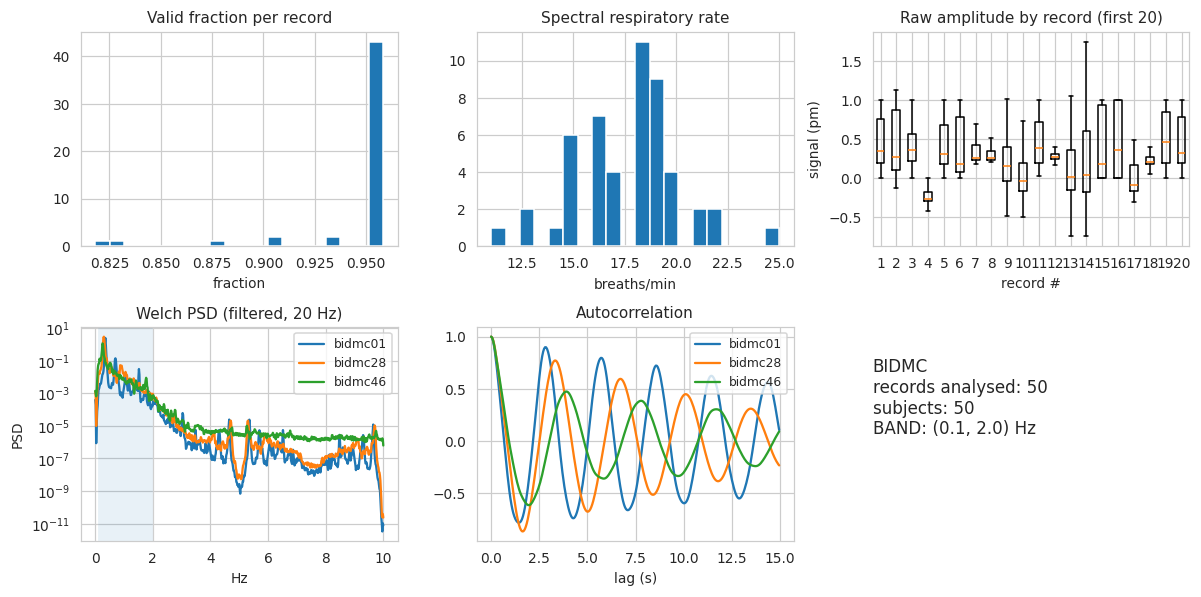

In [12]:
# ---- dataset summary, distributions, spectra, autocorrelation ----
good = QUAL[QUAL["exclude_reason"] == ""]
SUMMARY = pd.DataFrame([dict(dataset=DATASET, n_records_official=len(RECORDS), n_records_selected=int(INV["selected"].sum()), n_records_analysed=len(good),
                             n_subjects=good["subject"].nunique(), fs_native=sorted(good["fs_native"].unique().tolist()),
                             total_hours=good["duration_s"].sum() / 3600, median_duration_s=good["duration_s"].median(),
                             channel_names=sorted(INV["resp_name"].dropna().unique().tolist()), units=sorted(INV.get("resp_units", pd.Series(dtype=str)).dropna().unique().tolist()),
                             median_rr_bpm=good.get("resp_rate_bpm", pd.Series(dtype=float)).median())])
display(SUMMARY.T); save_table(SUMMARY, "dataset_characteristics", top_level=False)

reps = list(good.sort_values("valid_frac_model", ascending=False)["record"].iloc[[0, len(good) // 2, -1]]) if len(good) >= 3 else list(good["record"])
fig, ax = plt.subplots(2, 3, figsize=(11, 5.5))
ax[0, 0].hist(good["valid_frac_model"], bins=20); ax[0, 0].set(title="Valid fraction per record", xlabel="fraction")
if "resp_rate_bpm" in good: ax[0, 1].hist(good["resp_rate_bpm"].dropna(), bins=20); ax[0, 1].set(title="Spectral respiratory rate", xlabel="breaths/min")
ax[0, 2].boxplot([REC[r]["raw"][~REC[r]["bad"]] for r in good["record"].iloc[:min(len(good), 20)]], showfliers=False)
ax[0, 2].set(title="Raw amplitude by record (first 20)", xlabel="record #", ylabel=f"signal ({'/'.join(SUMMARY['units'][0])})")
for r in reps:   # representative PSD and ACF on the causally filtered, valid signal
    d = REC[r]; v = d["filt"][~d["bad"]]
    if len(v) < 200: continue
    fr, pw = sps.welch(v, fs=FS_MODEL, nperseg=min(len(v), 60 * FS_MODEL)); ax[1, 0].semilogy(fr, pw + 1e-20, label=r)
    ac = pd.Series(v).autocorr; lags = np.arange(0, min(len(v) // 2, 15 * FS_MODEL)); ax[1, 1].plot(lags / FS_MODEL, [ac(l) for l in lags[::2]] if False else [np.corrcoef(v[:-l or None][:len(v)-l], v[l:])[0, 1] if l else 1.0 for l in lags], label=r)
ax[1, 0].set(title="Welch PSD (filtered, 20 Hz)", xlabel="Hz", ylabel="PSD"); ax[1, 0].axvspan(*BAND, alpha=.1); ax[1, 0].legend()
ax[1, 1].set(title="Autocorrelation", xlabel="lag (s)"); ax[1, 1].legend()
ax[1, 2].axis("off"); ax[1, 2].text(0, .5, f"{DATASET}\nrecords analysed: {len(good)}\nsubjects: {good['subject'].nunique()}\nBAND: {BAND} Hz", fontsize=11)
fig.tight_layout(); savefig(fig, "fig02_dataset_statistics", f"{DATASET}: record-level statistics, example spectra and autocorrelation (descriptive EDA, from analysed records).")
EDA_REPS = reps

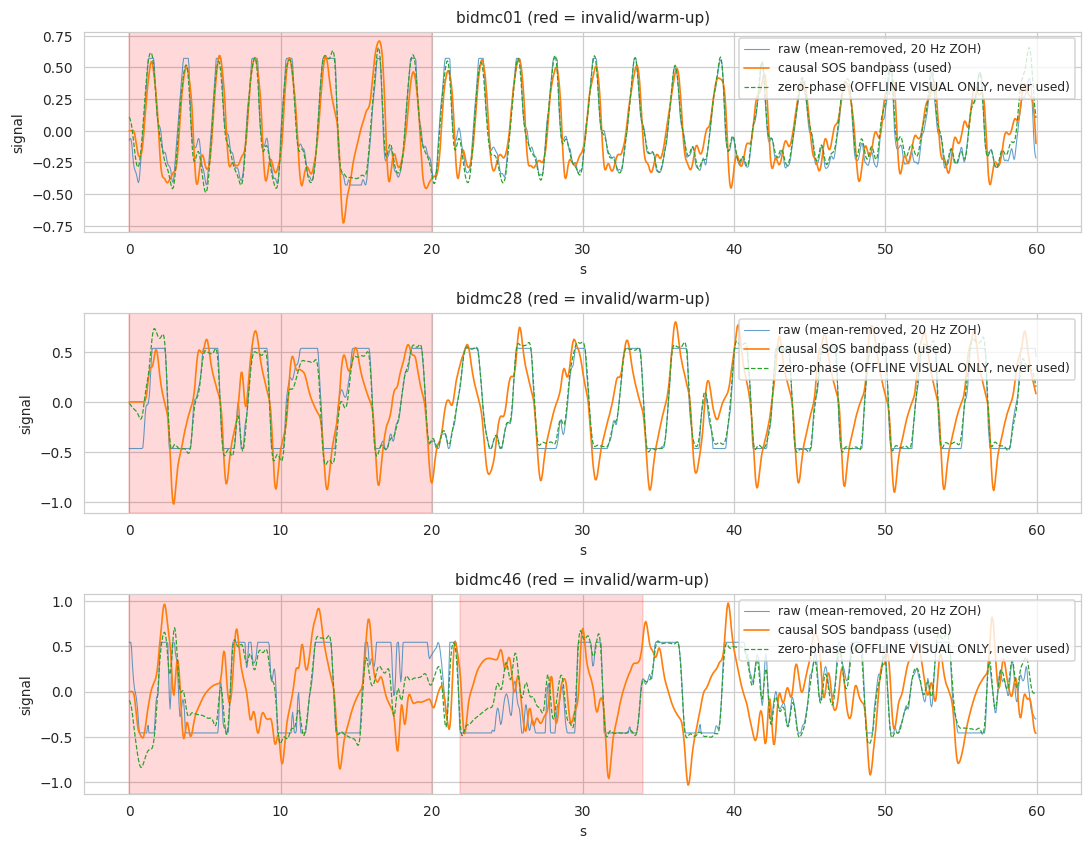

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,count,mean,std,min,25%,50%,75%,max
peak_hz,50.0,0.293667,0.042444,0.183333,0.266667,0.300000,0.316667,0.416667
power_frac_0.1-2.0Hz,50.0,0.971259,0.033077,0.820675,0.962338,0.984355,0.991544,0.997149
power_frac_0.05-1.0Hz,50.0,0.964795,0.030630,0.803889,0.959282,0.973075,0.982030,0.993202
power_frac_0.1-1.0Hz,50.0,0.946526,0.046838,0.748031,0.930671,0.961267,0.973335,0.990215
power_frac_0.1-3.0Hz,50.0,0.974904,0.030397,0.829651,0.964433,0.986848,0.994068,0.998873


Verified channel(s): ['RESP'] | units: ['pm']
Parsed header metadata (verify against header comments!):


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,record,age,sex,location,comments
0,bidmc01,88.0,M,micu,<age>: 88 <sex>: M <location>: micu <source>: ...
1,bidmc02,65.0,M,micu,<age>: 65 <sex>: M <location>: micu <source>: ...
2,bidmc03,46.0,F,micu,<age>: 46 <sex>: F <location>: micu <source>: ...
3,bidmc04,78.0,M,micu,<age>: 78 <sex>: M <location>: micu <source>: ...
4,bidmc05,73.0,F,micu,<age>: 73 <sex>: F <location>: micu <source>: ...
5,bidmc06,64.0,F,micu,<age>: 64 <sex>: F <location>: micu <source>: ...
6,bidmc07,64.0,F,micu,<age>: 64 <sex>: F <location>: micu <source>: ...
7,bidmc08,64.0,F,micu,<age>: 64 <sex>: F <location>: micu <source>: ...
8,bidmc09,64.0,F,micu,<age>: 64 <sex>: F <location>: micu <source>: ...
9,bidmc10,74.0,M,micu,<age>: 74 <sex>: M <location>: micu <source>: ...


,record,annotated_breaths_per_min,spectral_rr_bpm
0,bidmc01,41.874302,21.0
1,bidmc02,29.999500,15.0
2,bidmc03,34.749421,18.0
3,bidmc04,32.374460,17.0
4,bidmc06,39.499342,20.0
5,bidmc07,39.499342,20.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [13]:
# ---- time-domain EDA: raw vs causal filter vs OFFLINE-ONLY zero-phase reference; artifacts; band validation ----
fig, axs = plt.subplots(len(EDA_REPS), 1, figsize=(10, 2.6 * max(len(EDA_REPS), 1)), squeeze=False)
for a, r in zip(axs[:, 0], EDA_REPS):
    d = REC[r]; n = min(len(d["filt"]), 60 * FS_MODEL); t = np.arange(n) / FS_MODEL
    a.plot(t, d["raw"][:n] - np.nanmean(d["raw"][:n]), lw=.7, label="raw (mean-removed, 20 Hz ZOH)", alpha=.7)
    a.plot(t, d["filt"][:n], lw=1.1, label="causal SOS bandpass (used)")
    sos20 = design_bandpass(BAND, FS_MODEL); a.plot(t, sps.sosfiltfilt(sos20, d["raw"][:n] - np.mean(d["raw"][:n])), lw=.8, ls="--", label="zero-phase (OFFLINE VISUAL ONLY, never used)")
    bad = d["bad"][:n]; s, e = runs(bad)
    for x0, x1 in zip(s, e): a.axvspan(x0 / FS_MODEL, x1 / FS_MODEL, color="red", alpha=.15)
    a.set(title=f"{r} (red = invalid/warm-up)", xlabel="s", ylabel="signal"); a.legend(loc="upper right")
fig.tight_layout(); savefig(fig, "fig03_raw_vs_filtered", f"{DATASET}: raw versus causally filtered respiratory signal; dashed line is an offline-only zero-phase reference.")

# band validation against the observed (training-agnostic, descriptive) spectrum
bv = []
for r, d in REC.items():
    v = d["raw"][~d["bad"]]
    if len(v) < 60 * FS_MODEL: continue
    fr, pw = sps.welch(v - v.mean(), fs=FS_MODEL, nperseg=min(len(v), 60 * FS_MODEL)); tot = pw[(fr > 0.02) & (fr < 5)].sum()
    row = dict(record=r, peak_hz=fr[(fr > 0.05) & (fr < 3)][np.argmax(pw[(fr > 0.05) & (fr < 3)])])
    for b in [BAND] + ALT_BANDS: row[f"power_frac_{b[0]}-{b[1]}Hz"] = pw[(fr >= b[0]) & (fr <= b[1])].sum() / tot
    bv.append(row)
BAND_CHECK = pd.DataFrame(bv); display(BAND_CHECK.describe().T)
if len(BAND_CHECK) and BAND_CHECK["peak_hz"].quantile(.95) > 0.6 * BAND[1]:
    log(f"WARNING: 95th-percentile spectral peak {BAND_CHECK['peak_hz'].quantile(.95):.2f} Hz is close to the upper cutoff {BAND[1]} Hz; consider a wider validated passband.")
save_table(BAND_CHECK, "band_validation", top_level=False)
DATASET_EDA_EXTRA()

# Section E — Signal preprocessing and unit tests
**Pipeline (per record):** forward-fill gaps ≤ `MAX_GAP_S`, flag longer gaps and flat-lines as invalid → causal 4th-order Butterworth band-pass (`sosfilt`, state carried across chunks) at the *native* rate → zero-order-hold resampling to 20 Hz (only the most recent native sample is used, so no future sample is touched; the band-limited signal makes aliasing negligible, checked below) → invalid mask dilated *forward* by the warm-up length → normalisation with **training-subject** mean/std only (fitted per fold in Section F).

**Time alignment.** Model sample *k* occurs at `t = k/20 s` from the segment start and holds native sample `floor(k·fs/20)`.

In [14]:
# ---- unit tests (preprocessing) ----
def test_causal_filter():
    fs = 125.0; sos = design_bandpass(BAND, fs); rng = np.random.RandomState(0); x = rng.randn(5000); x2 = x.copy(); x2[3000:] += 50
    y1 = sps.sosfilt(sos, x); y2 = sps.sosfilt(sos, x2)
    assert np.allclose(y1[:3000], y2[:3000]), "filter output depends on future samples"
    assert sos.ndim == 2 and sos.shape[1] == 6
def test_alias_attenuation():
    for fs in sorted(INV["fs"].dropna().unique()):
        sos = design_bandpass(BAND, fs); w, h = sps.sosfreqz(sos, worN=[FS_MODEL / 2], fs=fs)
        assert 20 * np.log10(abs(h[0]) + 1e-12) < -40, f"insufficient attenuation at {FS_MODEL/2} Hz for fs={fs}"
def test_resample_alignment():
    fs = float(INV["fs"].dropna().iloc[0]); ks = np.arange(0, 2000); nat = np.floor(ks * fs / FS_MODEL + 1e-9)
    lag = ks / FS_MODEL - nat / fs
    assert (lag > -1e-6).all() and (lag < 1 / fs + 1e-6).all(), "ZOH resample used a future sample or is mis-aligned"
def test_flatline_and_gaps():
    x = np.r_[np.random.randn(500), np.ones(400), np.random.randn(500)]
    assert flatline_mask(x, 100., 2.)[600] and not flatline_mask(x, 100., 6.).any()
def test_preprocessing_no_future():
    r = next(iter(REC.values())); row = INV[INV["record"] == r["record"]].iloc[0]
    short = preprocess_record(row, BAND, row["start_s"], min(r["dur_s"], 120.0))
    n = min(len(short["filt"]), len(r["filt"]))
    assert np.allclose(short["filt"][:n - 5 * FS_MODEL], r["filt"][:n - 5 * FS_MODEL], atol=1e-8), "filtered values changed when later data were removed"
for t in [test_causal_filter, test_alias_attenuation, test_resample_alignment, test_flatline_and_gaps, test_preprocessing_no_future]:
    t(); print("PASSED", t.__name__)
mark("unit_tests_preprocessing")

PASSED test_causal_filter
PASSED test_alias_attenuation
PASSED test_resample_alignment
PASSED test_flatline_and_gaps
PASSED test_preprocessing_no_future
[18:16:42] STATUS unit_tests_preprocessing: RUN


# Section F — Subject-level splits and causal windows
Splits are made on **subjects** before any window is extracted. Evaluation uses **patient-grouped K-fold cross-validation** (`N_CV_FOLDS`): in fold *k* the test subjects are bucket *k*, the validation subjects bucket *k+1*, and the training subjects the rest, so every analysed subject is a held-out test subject exactly once. Each fold has train / validation / test subjects (no overlap, asserted). Validation windows are further split *chronologically within each validation record* into `val_sel` (early stopping, hyper-parameter and controller tuning) and `val_cal` (conformal calibration), separated by a gap of `HIST+max horizon` samples.

Window at anchor *i* (last observed sample): input `z[i-99..i]` (5 s @ 20 Hz); targets `z[i+h]`, h ∈ {2,4,6,8,10} steps = {100…500} ms. A window is valid only if **every** sample from `i-99` to `i+10` is valid. Normalisation statistics (mean, std) come from the fold's training records only.

In [15]:
H_STEPS = list(HORIZONS_STEPS); H_MS = [int(round(h * 1000 / FS_MODEL)) for h in H_STEPS]; NH = len(H_STEPS); HMAX = max(H_STEPS); DT = 1.0 / FS_MODEL
HOFF = np.arange(-HIST + 1, 1); HIDX = np.array(H_STEPS)

SUBJ_DF = pd.DataFrame([dict(subject=d["subject"], group=d["group"], record=r) for r, d in REC.items()])
SUBJ_INFO = INV.groupby("subject").agg(age=("age", "first"), sex=("sex", "first"), group=("group", "first")).reset_index()
FOLDS = build_folds(sorted(SUBJ_DF["subject"].unique()), SUBJ_INFO)
manifest = []
for f in FOLDS:
    sets = [set(f["train"]), set(f["val"]), set(f["test"])]
    assert not (sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2]), "subject overlap between splits"
    for role in ["train", "val", "test"]:
        for s in f[role]: manifest.append(dict(fold=f["fold"], role=role, subject=s, test_group=f["test_group"].get(s, ""),
                                                records="|".join(SUBJ_DF[SUBJ_DF.subject == s]["record"])))
SPLIT = pd.DataFrame(manifest); save_table(SPLIT, "split_manifest"); display(SPLIT.groupby(["fold", "role"]).size().unstack(fill_value=0))

def fit_norm(rec_ids):
    v = np.concatenate([REC[r]["filt"][~REC[r]["bad"]] for r in rec_ids]); return float(v.mean()), float(v.std() + 1e-12)

class WinSet:
    """Index-based windows over one concatenated normalised signal (windows are gathered lazily)."""
    def __init__(self, Z, anc, rec, loc, subj, grp, fold, sd, spans):
        self.Z, self.anc, self.rec, self.loc, self.subj, self.grp, self.fold, self.sd, self.spans = Z, anc, rec, loc, subj, grp, fold, sd, spans
    def __len__(self): return len(self.anc)
    def X(self, sl=slice(None)): return self.Z[self.anc[sl][:, None] + HOFF].astype(np.float32)
    def last(self): return self.Z[self.anc]
    def Y(self): return self.Z[self.anc[:, None] + HIDX]
    def Yh(self, h): return self.Z[self.anc + h]
    def sub(self, mask):
        m = np.asarray(mask); return WinSet(self.Z, self.anc[m], self.rec[m], self.loc[m], self.subj[m], self.grp[m], self.fold[m], self.sd[m], self.spans)

def make_windows(rec_ids, mu, sd, stride, fold_id, test_group=None, loc_range=None):
    Zs, anc_l, rec_l, loc_l, subj_l, grp_l, spans, off = [], [], [], [], [], [], [], 0
    for r in rec_ids:
        d = REC[r]; z = np.where(d["bad"], 0.0, (d["filt"] - mu) / sd).astype(np.float32); n = len(z)
        cum = np.r_[0, np.cumsum(d["bad"])]; a = np.arange(HIST - 1, n - HMAX, stride)
        a = a[(cum[a + HMAX + 1] - cum[a - HIST + 1]) == 0]                      # every sample in [i-99, i+10] valid
        if loc_range is not None: a = a[(a >= loc_range[0] * n) & (a < loc_range[1] * n)] if False else a
        Zs.append(z); anc_l.append(a + off); rec_l += [r] * len(a); loc_l.append(a); subj_l += [d["subject"]] * len(a)
        grp_l += [(test_group or {}).get(d["subject"], d["group"])] * len(a); spans.append((r, off, n)); off += n
    anc = np.concatenate(anc_l) if anc_l else np.zeros(0, int)
    return WinSet(np.concatenate(Zs), anc, np.array(rec_l), np.concatenate(loc_l) if loc_l else np.zeros(0, int), np.array(subj_l), np.array(grp_l),
                  np.full(len(anc), fold_id), np.full(len(anc), sd, dtype=np.float64), spans)

def chrono_split_val(ws: WinSet):
    """First 50% of each validation record -> val_sel, last 50% (after a gap) -> val_cal. Chronology preserved."""
    sel = np.zeros(len(ws), bool); cal = np.zeros(len(ws), bool); gap = HIST + HMAX
    for r in np.unique(ws.rec):
        idx = np.flatnonzero(ws.rec == r); mid = np.median(ws.loc[idx]); sel[idx[ws.loc[idx] < mid - gap / 2]] = True; cal[idx[ws.loc[idx] > mid + gap / 2]] = True
    return ws.sub(sel), ws.sub(cal)

def build_fold_sets(f):
    tr_recs = SUBJ_DF[SUBJ_DF.subject.isin(f["train"])]["record"].tolist(); va_recs = SUBJ_DF[SUBJ_DF.subject.isin(f["val"])]["record"].tolist()
    te_recs = SUBJ_DF[SUBJ_DF.subject.isin(f["test"])]["record"].tolist()
    mu, sd = fit_norm(tr_recs)                                               # TRAIN statistics only
    tr = make_windows(tr_recs, mu, sd, TRAIN_STRIDE, f["fold"]); va = make_windows(va_recs, mu, sd, 1, f["fold"])
    te = make_windows(te_recs, mu, sd, 1, f["fold"], f["test_group"])        # stride 1: needed for continuous control simulation
    vsel, vcal = chrono_split_val(va)
    return dict(train=tr, val_sel=vsel, val_cal=vcal, test=te, mu=mu, sd=sd)

# ---- unit tests: shapes / leakage / overlap ----
def test_windows_no_leakage():
    d0 = next(iter(REC.values())); backup = (d0["filt"].copy(), d0["bad"].copy()); n = 600
    REC["__t"] = dict(filt=np.arange(n, dtype=float), bad=np.zeros(n, bool), subject="s", group="g")
    ws = make_windows(["__t"], 0.0, 1.0, 3, 0); REC.pop("__t")
    X, Y, a = ws.X(), ws.Y(), ws.anc
    assert X.shape == (len(ws), HIST) and Y.shape == (len(ws), NH)
    assert np.allclose(X[:, -1], a) and np.allclose(X[:, 0], a - HIST + 1), "input window not ending at anchor"
    assert np.allclose(Y, a[:, None] + HIDX), "targets misaligned with horizons"
    assert X.max(1).max() <= a.max() and (X.max(1) <= a).all(), "input contains future samples"
def test_invalid_excluded():
    n = 600; bad = np.zeros(n, bool); bad[300:305] = True
    REC["__t"] = dict(filt=np.random.randn(n), bad=bad, subject="s", group="g")
    ws = make_windows(["__t"], 0.0, 1.0, 1, 0); REC.pop("__t")
    for a in ws.loc: assert not bad[a - HIST + 1:a + HMAX + 1].any()
    assert np.isfinite(ws.X()).all() and np.isfinite(ws.Y()).all()
def test_norm_from_train_only():
    f = FOLDS[0]; tr = SUBJ_DF[SUBJ_DF.subject.isin(f["train"])]["record"].tolist(); mu, sd = fit_norm(tr)
    assert set(f["train"]).isdisjoint(f["test"]) and np.isfinite(mu) and sd > 0
for t in [test_windows_no_leakage, test_invalid_excluded, test_norm_from_train_only]: t(); print("PASSED", t.__name__)
FOLD_SETS = {f["fold"]: build_fold_sets(f) for f in FOLDS}
for k, v in FOLD_SETS.items(): print(f"fold {k}: train {len(v['train'])}  val_sel {len(v['val_sel'])}  val_cal {len(v['val_cal'])}  test {len(v['test'])} windows; mu={v['mu']:.4g}, sd={v['sd']:.4g}")
meta = pd.concat([pd.DataFrame(dict(fold=ws.fold, record=ws.rec, subject=ws.subj, anchor_idx=ws.loc, pred_time_s=ws.loc / FS_MODEL, split=name))
                  for fs_ in FOLD_SETS.values() for name, ws in fs_.items() if isinstance(ws, WinSet) and name != "train"]).iloc[::50]
meta.to_csv(OUT / "window_metadata_sample.csv", index=False); _WRITTEN.add(str(OUT / "window_metadata_sample.csv"))
log("Window metadata sample (every 50th window; horizons are the fixed list H_MS) saved.")

[18:16:42] Subject identity (mode requested=documented_id, used=documented_id): 50 records/subjects analysed, 50 with a documented subject ID, 44 patient groups; groups with >1 record kept together: {'ID:s03386': ['bidmc06', 'bidmc07', 'bidmc08', 'bidmc09'], 'ID:s11342': ['bidmc20', 'bidmc21', 'bidmc22', 'bidmc23']}
[18:16:42] NOTE: age missing for 1 subject(s) -> the age-subgroup shift analysis is NOT RUN (no imputation)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


role,test,train,val
fold,,,
0,10,30,10
1,10,30,10
2,10,30,10
3,10,30,10
4,10,30,10


PASSED test_windows_no_leakage
PASSED test_invalid_excluded
PASSED test_norm_from_train_only


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


fold 0: train 133761  val_sel 44910  val_cal 44910  test 89515 windows; mu=0.000199, sd=0.3132
fold 1: train 134250  val_sel 43717  val_cal 43717  test 90920 windows; mu=4.248e-05, sd=0.328
fold 2: train 135677  val_sel 43482  val_cal 43482  test 88535 windows; mu=-0.000119, sd=0.3358
fold 3: train 134485  val_sel 44910  val_cal 44910  test 88064 windows; mu=-5.662e-05, sd=0.3351
fold 4: train 133761  val_sel 44207  val_cal 44207  test 90920 windows; mu=0.0001603, sd=0.3245
[18:16:43] Window metadata sample (every 50th window; horizons are the fixed list H_MS) saved.


# Section G — Forecasting models
All models are multi-output (five horizons at once). Metrics applicable to **all** models: MAE, RMSE (point forecast). **Distribution-based** metrics (NLL, PICP, MPIW) apply only to models with a predictive distribution (prob. LSTM, prob. TCN, ensemble, conformal intervals).

| Model | Uncertainty |
|---|---|
| Persistence, Ridge-AR, Kalman | none (point) |
| Probabilistic LSTM / TCN | aleatoric σ (softplus + floor) |
| Deep ensemble (LSTM members) | aleatoric (mean σ²) + epistemic (variance of member means) |
| Split conformal | distribution-free intervals from validation residuals |

**Kalman baseline.** State `[position, velocity]`, constant-velocity model, process-noise `q`, measurement-noise `r` on the (normalised) signal; steady-state gain from the discrete algebraic Riccati equation. *Filtered state* at anchor *i* uses samples ≤ *i*; the *h-step predicted state* is `pos + vel·h·dt`. `(q, r)` are grid-selected on `val_sel`.

In [16]:
class LSTMNet(nn.Module):
    def __init__(s, hidden, layers, prob=True):
        super().__init__(); s.prob = prob; s.lstm = nn.LSTM(1, hidden, layers, batch_first=True); s.head = nn.Linear(hidden, NH * (2 if prob else 1))
    def forward(s, x):
        o = s.head(s.lstm(x)[0][:, -1]); mu = x[:, -1, :] + o[:, :NH]                     # predict increments from last observation
        sg = F.softplus(o[:, NH:]) + SIGMA_MIN if s.prob else None                        # positive, bounded away from 0
        return mu, sg
class CausalBlock(nn.Module):
    def __init__(s, cin, cout, k, d, p):
        super().__init__(); s.pad = (k - 1) * d; s.c1 = nn.Conv1d(cin, cout, k, dilation=d); s.c2 = nn.Conv1d(cout, cout, k, dilation=d)
        s.res = nn.Conv1d(cin, cout, 1) if cin != cout else nn.Identity(); s.dp = nn.Dropout(p)
    def forward(s, x):
        y = s.dp(F.relu(s.c1(F.pad(x, (s.pad, 0))))); y = s.dp(F.relu(s.c2(F.pad(y, (s.pad, 0))))); return F.relu(y + s.res(x))   # left-padding only: causal
class TCNNet(nn.Module):
    def __init__(s, ch, prob=True, dil=(1, 2, 4, 8, 16, 32), k=3, p=0.1):
        super().__init__(); s.prob = prob; L = []; c = 1
        for d in dil: L.append(CausalBlock(c, ch, k, d, p)); c = ch
        s.net = nn.Sequential(*L); s.head = nn.Linear(ch, NH * (2 if prob else 1))
    def forward(s, x):
        o = s.head(s.net(x.transpose(1, 2))[:, :, -1]); mu = x[:, -1, :] + o[:, :NH]
        return mu, (F.softplus(o[:, NH:]) + SIGMA_MIN if s.prob else None)
def n_params(m): return int(sum(p.numel() for p in m.parameters()))
def gauss_nll_loss(mu, sg, y): return (0.5 * torch.log(2 * math.pi * sg ** 2) + 0.5 * ((y - mu) / sg) ** 2).mean()

def train_nn(model, Xtr, Ytr, Xva, Yva, prob, name, seed):
    """Adam + ReduceLROnPlateau + early stopping + best-checkpoint on validation loss (val_sel only).
    Data live on the device and batches are indexed from a seeded permutation (no DataLoader / per-step host sync) -> same recipe, much faster on GPU."""
    set_seed(seed); model.to(DEVICE); opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WD)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    g = torch.Generator().manual_seed(seed)
    Xt, Yt = torch.from_numpy(Xtr)[:, :, None].to(DEVICE), torch.from_numpy(Ytr.astype(np.float32)).to(DEVICE); N = len(Xt)
    Xv, Yv = torch.from_numpy(Xva)[:, :, None].to(DEVICE), torch.from_numpy(Yva.astype(np.float32)).to(DEVICE)
    def vloss():
        model.eval(); tot = 0.0
        with torch.no_grad():
            for a in range(0, len(Xv), 8192):
                mu, sg = model(Xv[a:a + 8192]); y = Yv[a:a + 8192]
                tot += (gauss_nll_loss(mu, sg, y) if prob else F.mse_loss(mu, y)).item() * len(y)
        return tot / len(Xv)
    ck = OUT / "models" / f"{name}.pt"; best, bad, hist, t0 = np.inf, 0, [], time.time()
    for ep in range(EPOCHS):
        model.train(); tl = torch.zeros((), device=DEVICE); nb = 0; perm = torch.randperm(N, generator=g).to(DEVICE)
        for a in range(0, N, BATCH):
            ii = perm[a:a + BATCH]; xb, yb = Xt[ii], Yt[ii]; opt.zero_grad(set_to_none=True); mu, sg = model(xb)
            loss = gauss_nll_loss(mu, sg, yb) if prob else F.mse_loss(mu, yb)
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); tl += loss.detach(); nb += 1
        tl = float(tl) / nb
        if not np.isfinite(tl): raise FloatingPointError(f"{name}: non-finite loss at epoch {ep}")
        vl = vloss(); sched.step(vl); hist.append(dict(epoch=ep, train_loss=tl, val_loss=vl, lr=opt.param_groups[0]["lr"]))
        if vl < best - 1e-5: best, bad = vl, 0; torch.save(model.state_dict(), ck)
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(torch.load(ck, map_location=DEVICE)); model.eval()
    return pd.DataFrame(hist), time.time() - t0

def predict_nn(model, ws, bs=8192):
    model.eval(); mus, sgs = [], []
    with torch.no_grad():
        for a in range(0, len(ws), bs):
            mu, sg = model(torch.from_numpy(ws.X(slice(a, a + bs)))[:, :, None].to(DEVICE)); mus.append(mu.cpu().numpy()); sgs.append(sg.cpu().numpy() if sg is not None else None)
    return np.concatenate(mus), (np.concatenate(sgs) if sgs and sgs[0] is not None else None)

def kalman_cv(z, q, r, dt=DT):
    """Steady-state constant-velocity Kalman filter. Returns FILTERED position/velocity at every sample (uses samples <= k only)."""
    Fm = np.array([[1, dt], [0, 1.]]); Hm = np.array([[1., 0.]]); Q = q * np.array([[dt ** 3 / 3, dt ** 2 / 2], [dt ** 2 / 2, dt]])
    P = solve_discrete_are(Fm.T, Hm.T, Q, np.array([[r]])); K = (P @ Hm.T / (Hm @ P @ Hm.T + r)).ravel(); k0, k1 = float(K[0]), float(K[1])
    f01 = dt; p = v = 0.0; pos = np.empty(len(z)); vel = np.empty(len(z))
    for i, zi in enumerate(z):
        pp = p + f01 * v; innov = zi - pp; p = pp + k0 * innov; v = v + k1 * innov; pos[i] = p; vel[i] = v
    return pos, vel
def kalman_forecast(ws, q, r):
    out = np.zeros((len(ws), NH))
    for rid, off, n in ws.spans:
        sel = np.flatnonzero(ws.rec == rid)
        if len(sel) == 0: continue
        pos, vel = kalman_cv(ws.Z[off:off + n].astype(float), q, r); a = ws.anc[sel] - off
        out[sel] = pos[a][:, None] + vel[a][:, None] * HIDX[None] * DT                  # predicted state = filtered + h*dt*velocity
    return out

def point_scores(y, mu): e = y - mu; return dict(mae=np.abs(e).mean(0), rmse=np.sqrt((e ** 2).mean(0)))

[18:16:44] fold checkpoints: /kaggle/temp/ckpt/full_20261010_181630
[18:16:44] === fitting fold 0 (30 train / 10 val / 10 test subjects)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[18:24:01] fold 0 done in 7.3 min (checkpoint saved)
[18:24:01] fold 0 info: {'ridge_alpha': 10, 'kalman_q_r': (100, 0.001), 'latency_ms_per_window': {'lstm_prob': 0.32227516174316406, 'tcn_prob': 1.8504810333251953}}
[18:24:01] === fitting fold 1 (30 train / 10 val / 10 test subjects)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[18:33:13] fold 1 done in 9.2 min (checkpoint saved)
[18:33:13] fold 1 info: {'ridge_alpha': 10, 'kalman_q_r': (100, 0.001), 'latency_ms_per_window': {'lstm_prob': 0.3183436393737793, 'tcn_prob': 2.0670318603515625}}
[18:33:13] === fitting fold 2 (30 train / 10 val / 10 test subjects)


...

[18:48:37] fold 3 done in 7.6 min (checkpoint saved)
[18:48:37] fold 3 info: {'ridge_alpha': 10, 'kalman_q_r': (100, 0.001), 'latency_ms_per_window': {'lstm_prob': 0.31914234161376953, 'tcn_prob': 1.8454599380493164}}
[18:48:37] === fitting fold 4 (30 train / 10 val / 10 test subjects)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[18:57:32] fold 4 done in 8.9 min (checkpoint saved)
[18:57:32] fold 4 info: {'ridge_alpha': 10, 'kalman_q_r': (100, 0.001), 'latency_ms_per_window': {'lstm_prob': 0.32439231872558594, 'tcn_prob': 1.8991303443908691}}
[18:57:32] STATUS forecasting_models: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,model,params,train_time_s,epochs,fold
0,lstm_member0,17802,15.744785,9,0
1,lstm_member1,17802,14.547072,9,0
2,lstm_member2,17802,14.375720,9,0
3,lstm_member3,17802,14.350195,9,0
4,lstm_member4,17802,13.027426,8,0
5,tcn_prob,34666,181.281974,22,0
6,tcn_det,34501,163.181860,20,0
0,lstm_member0,17802,14.518293,9,1
1,lstm_member1,17802,14.726908,9,1
2,lstm_member2,17802,14.675247,9,1


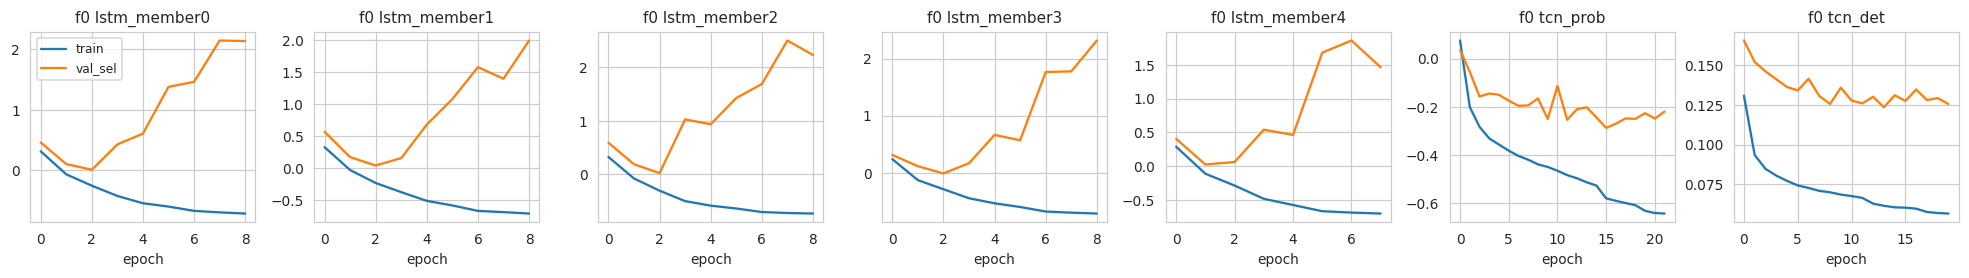

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


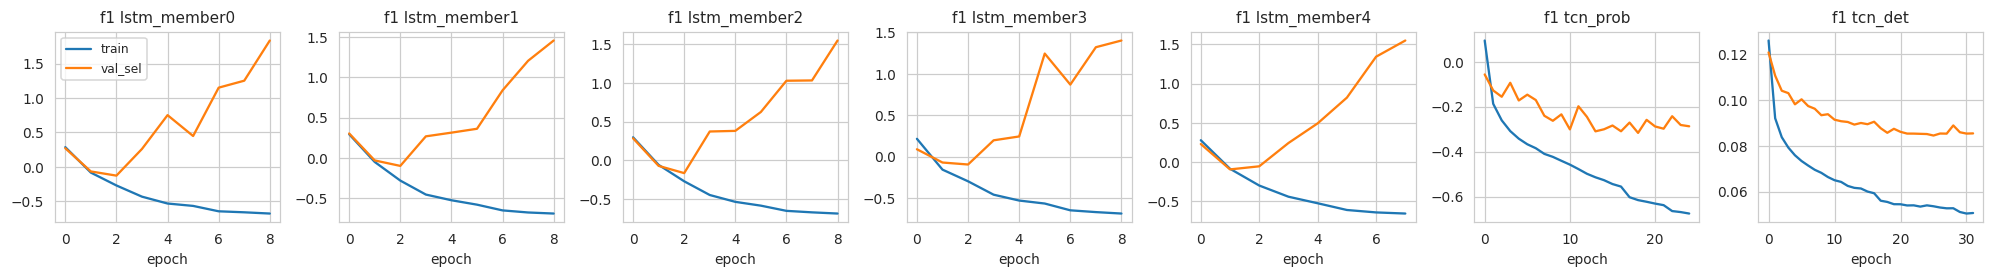

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


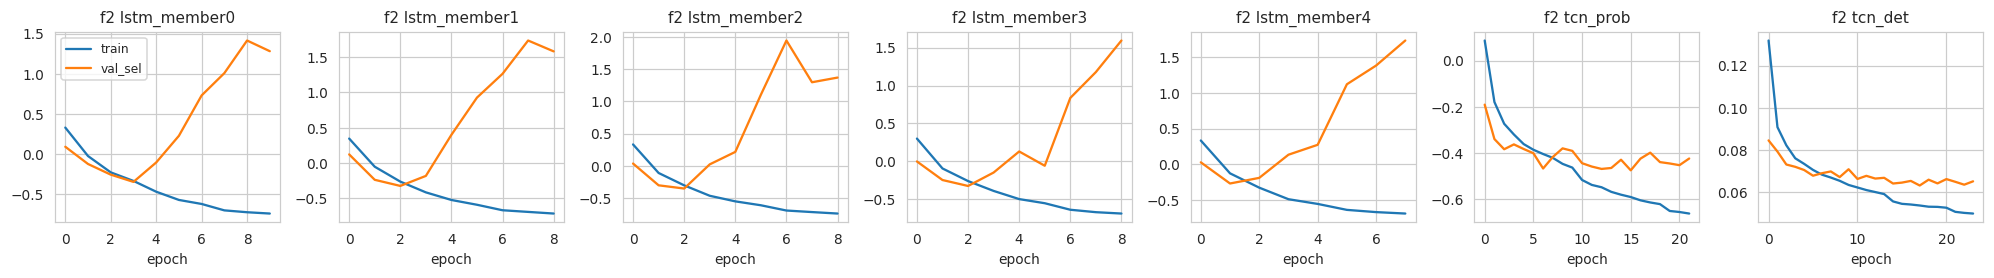

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


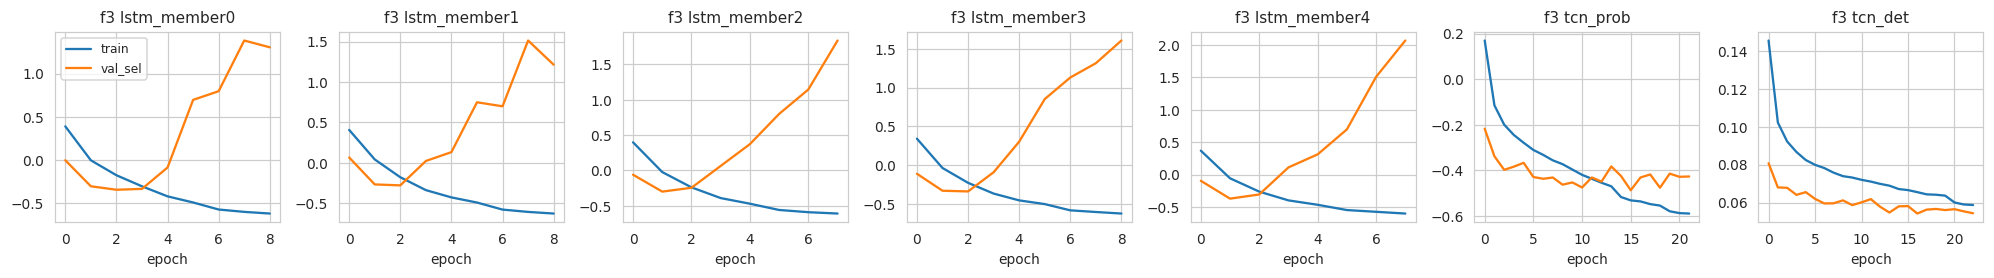

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


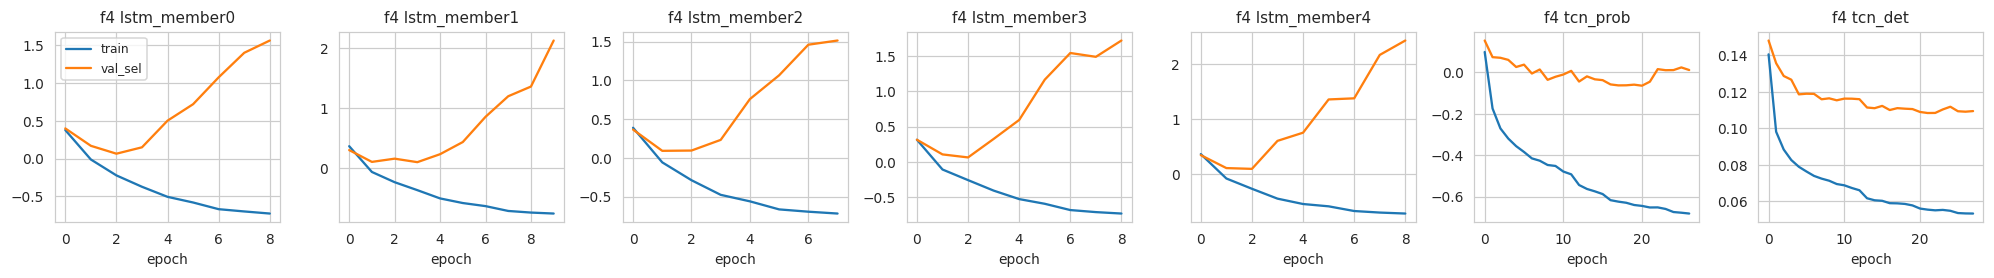

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [17]:
def conformal_q(scores, alpha):
    n = len(scores); k = int(math.ceil((n + 1) * (1 - alpha)))
    return np.inf if k > n else float(np.sort(scores)[k - 1])

def fit_fold(f):
    """Train/tune everything on TRAIN + val_sel (+val_cal for conformal) and predict val_sel / val_cal / test."""
    S = FOLD_SETS[f["fold"]]; tr, vs, vc, te = S["train"], S["val_sel"], S["val_cal"], S["test"]
    assert len(tr) > 0 and len(vs) > 0 and len(vc) > 0 and len(te) > 0, f"fold {f['fold']}: an empty split; check exclusions/limits"
    Xtr, Ytr = tr.X(), tr.Y(); sub = np.arange(0, len(vs), VAL_SUB); Xva, Yva = vs.X(slice(None))[sub], vs.Y()[sub]
    info, hist = {}, {}; P = {"val_sel": {}, "val_cal": {}, "test": {}}; ws_map = dict(val_sel=vs, val_cal=vc, test=te)
    def put(name, fn):
        for k, w in ws_map.items(): mu, sg = fn(w); P[k][name] = dict(mu=mu, sigma=sg)
    put("persistence", lambda w: (np.repeat(w.last()[:, None], NH, 1), None))
    best = (np.inf, None)                                                           # ridge-AR: alpha on val_sel only
    for a in RIDGE_ALPHAS:
        m = Ridge(alpha=a).fit(Xtr, Ytr); e = np.abs(m.predict(Xva) - Yva).mean()
        if e < best[0]: best = (e, a)
    ridge = Ridge(alpha=best[1]).fit(Xtr, Ytr); info["ridge_alpha"] = best[1]; put("ridge", lambda w: (ridge.predict(w.X()), None))
    bk = (np.inf, None)                                                             # Kalman (q, r) on val_sel only
    for q in KF_Q:
        for r in KF_R:
            e = np.abs(kalman_forecast(vs, q, r) - vs.Y()).mean()
            if e < bk[0]: bk = (e, (q, r))
    info["kalman_q_r"] = bk[1]; put("kalman", lambda w: (kalman_forecast(w, *bk[1]), None))
    # probabilistic LSTM members (member 0 == "lstm_prob"), deep ensemble
    members, pinfo = [], []
    for m_i in range(ENS_SIZE):
        net = LSTMNet(HIDDEN, LAYERS, True); h, tt = train_nn(net, Xtr, Ytr, Xva, Yva, True, f"f{f['fold']}_lstm_member{m_i}", SEED + 100 * m_i)
        members.append(net); hist[f"lstm_member{m_i}"] = h; pinfo.append(dict(model=f"lstm_member{m_i}", params=n_params(net), train_time_s=tt, epochs=len(h)))
    outs = {k: [predict_nn(m, w) for m in members] for k, w in ws_map.items()}
    for k in ws_map:
        mus = np.stack([o[0] for o in outs[k]]); sgs = np.stack([o[1] for o in outs[k]])
        P[k]["lstm_prob"] = dict(mu=mus[0], sigma=sgs[0])
        ale = (sgs ** 2).mean(0); epi = mus.var(0)                                 # law of total variance for a uniform mixture of Gaussians
        P[k]["ensemble"] = dict(mu=mus.mean(0), sigma=np.sqrt(ale + epi), ale=np.sqrt(ale), epi=np.sqrt(epi))
    tcn_p = TCNNet(TCN_CH, True); h, tt = train_nn(tcn_p, Xtr, Ytr, Xva, Yva, True, f"f{f['fold']}_tcn_prob", SEED + 7); hist["tcn_prob"] = h
    pinfo.append(dict(model="tcn_prob", params=n_params(tcn_p), train_time_s=tt, epochs=len(h)))
    tcn_d = TCNNet(TCN_CH, False); h, tt = train_nn(tcn_d, Xtr, Ytr, Xva, Yva, False, f"f{f['fold']}_tcn_det", SEED + 8); hist["tcn_det"] = h
    pinfo.append(dict(model="tcn_det", params=n_params(tcn_d), train_time_s=tt, epochs=len(h)))
    put("tcn_prob", lambda w: predict_nn(tcn_p, w)); put("tcn_det", lambda w: predict_nn(tcn_d, w))
    # latency benchmark (batch of 1, CPU/GPU as configured)
    x1 = torch.from_numpy(te.X(slice(0, 1)))[:, :, None].to(DEVICE); lat = {}
    for nm, net in [("lstm_prob", members[0]), ("tcn_prob", tcn_p)]:
        with torch.no_grad():
            for _ in range(5): net(x1)
            t0 = time.time(); [net(x1) for _ in range(100)]; lat[nm] = (time.time() - t0) / 100 * 1e3
    info["latency_ms_per_window"] = lat
    # split conformal on val_cal (separate from training and from val_sel used for early stopping)
    CONF = {}
    for nm in ["ridge", "lstm_prob", "tcn_prob", "ensemble", "persistence"]:
        yc = vc.Y(); mu_c = P["val_cal"][nm]["mu"]; res = np.abs(yc - mu_c); sg_c = P["val_cal"][nm]["sigma"]
        for alpha in [0.10, 0.05]:
            q_abs = np.array([conformal_q(res[:, j], alpha) for j in range(NH)]); CONF[(nm, "abs", alpha)] = q_abs
            if sg_c is not None: CONF[(nm, "norm", alpha)] = np.array([conformal_q(res[:, j] / sg_c[:, j], alpha) for j in range(NH)])
    for k in ws_map:
        for (nm, kind, alpha), q in CONF.items():
            mu_, sg_ = P[k][nm]["mu"], P[k][nm]["sigma"]; half = q[None] if kind == "abs" else q[None] * sg_
            P[k][nm][f"conf_{kind}_{int(alpha*100)}"] = (mu_ - half, mu_ + half)
    return dict(P=P, info=info, hist=hist, pinfo=pd.DataFrame(pinfo), sets=S)

import pickle
try:                                                                           # outside /kaggle/working -> not part of the saved Output; falls back to the run folder if not writable
    CKPT_DIR = Path("/kaggle/temp/ckpt") / OUT.name; CKPT_DIR.mkdir(parents=True, exist_ok=True)
except Exception:
    CKPT_DIR = OUT / "ckpt"; CKPT_DIR.mkdir(parents=True, exist_ok=True)
log(f"fold checkpoints: {CKPT_DIR}")
FIT = {}
for f in FOLDS:
    ck = CKPT_DIR / f"fit_fold{f['fold']}.pkl"; t_f = time.time()
    if ck.exists():                                                             # resume: set RESUME_RUN to the same run name after an interruption
        with open(ck, "rb") as fh: d = pickle.load(fh)
        d["sets"] = FOLD_SETS[f["fold"]]; FIT[f["fold"]] = d; log(f"=== fold {f['fold']}: loaded from checkpoint {ck.name}")
    else:
        log(f"=== fitting fold {f['fold']} ({len(f['train'])} train / {len(f['val'])} val / {len(f['test'])} test subjects)"); FIT[f["fold"]] = fit_fold(f)
        with open(ck, "wb") as fh: pickle.dump({k: v for k, v in FIT[f["fold"]].items() if k != "sets"}, fh, protocol=pickle.HIGHEST_PROTOCOL)
        log(f"fold {f['fold']} done in {(time.time() - t_f) / 60:.1f} min (checkpoint saved)")
    log(f"fold {f['fold']} info: {FIT[f['fold']]['info']}")
mark("forecasting_models")
display(pd.concat([v["pinfo"].assign(fold=k) for k, v in FIT.items()]))
for k, v in FIT.items():
    fig, axs = plt.subplots(1, len(v["hist"]), figsize=(2.6 * len(v["hist"]), 2.6), squeeze=False)
    for a, (nm, h) in zip(axs[0], v["hist"].items()): a.plot(h["train_loss"], label="train"); a.plot(h["val_loss"], label="val_sel"); a.set(title=f"f{k} {nm}", xlabel="epoch")
    axs[0, 0].legend(); fig.tight_layout(); savefig(fig, f"fig_training_curves_fold{k}", f"Training/validation loss curves (fold {k}).")

In [18]:
# ---- merge test windows across folds into one table; subject-level forecast + uncertainty metrics ----
TEST = dict(rec=np.concatenate([FIT[k]["sets"]["test"].rec for k in FIT]), subj=np.concatenate([FIT[k]["sets"]["test"].subj for k in FIT]),
            grp=np.concatenate([FIT[k]["sets"]["test"].grp for k in FIT]), fold=np.concatenate([FIT[k]["sets"]["test"].fold for k in FIT]),
            loc=np.concatenate([FIT[k]["sets"]["test"].loc for k in FIT]), sd=np.concatenate([FIT[k]["sets"]["test"].sd for k in FIT]),
            Y=np.concatenate([FIT[k]["sets"]["test"].Y() for k in FIT]), last=np.concatenate([FIT[k]["sets"]["test"].last() for k in FIT]))
MODELS = list(FIT[FOLDS[0]["fold"]]["P"]["test"].keys()); NTEST = len(TEST["subj"])
def merged(name, key):
    arrs = [FIT[k]["P"]["test"][name].get(key) for k in FIT]
    if arrs[0] is None: return None
    if isinstance(arrs[0], tuple): return (np.concatenate([a[0] for a in arrs]), np.concatenate([a[1] for a in arrs]))
    return np.concatenate(arrs)
PT = {m: {k: merged(m, k) for k in FIT[FOLDS[0]["fold"]]["P"]["test"][m].keys()} for m in MODELS}

def gnll(y, mu, sg): return 0.5 * np.log(2 * np.pi * sg ** 2) + 0.5 * ((y - mu) / sg) ** 2
Z90, Z95 = sstats.norm.ppf(0.95), sstats.norm.ppf(0.975)
def subject_metrics(model, key=None):
    P_ = PT[model]; mu, sg = P_["mu"], P_["sigma"]; rows = []
    for s in np.unique(TEST["subj"]):
        m = TEST["subj"] == s; y = TEST["Y"][m]; e = y - mu[m]; sd = TEST["sd"][m][:, None]; g = TEST["grp"][m][0]
        for j in range(NH):
            r = dict(model=model, subject=s, group=g, horizon_ms=H_MS[j], n_windows=int(m.sum()), mae=np.abs(e[:, j]).mean(), rmse=np.sqrt((e[:, j] ** 2).mean()),
                     mae_units=(np.abs(e[:, j]) * sd[:, 0]).mean(), rmse_units=np.sqrt(((e[:, j] * sd[:, 0]) ** 2).mean()))
            if sg is not None:
                s_ = sg[m][:, j]; r.update(nll=gnll(y[:, j], mu[m][:, j], s_).mean(), mean_sigma=s_.mean(), mean_sigma_units=(s_ * sd[:, 0]).mean(),
                                          picp90=(np.abs(e[:, j]) <= Z90 * s_).mean(), picp95=(np.abs(e[:, j]) <= Z95 * s_).mean(), mpiw95=(2 * Z95 * s_).mean(),
                                          spearman_sigma_abs_err=sstats.spearmanr(s_, np.abs(e[:, j]))[0] if m.sum() > 10 else np.nan)
                for kind in ["abs", "norm"]:
                    for a in [10, 5]:
                        ck = f"conf_{kind}_{a}"
                        if ck in P_ and P_[ck] is not None:
                            lo, hi = P_[ck][0][m][:, j], P_[ck][1][m][:, j]; r[f"{ck}_picp"] = ((y[:, j] >= lo) & (y[:, j] <= hi)).mean(); r[f"{ck}_mpiw"] = (hi - lo).mean()
            else:
                for a in [10, 5]:
                    ck = f"conf_abs_{a}"
                    if ck in P_ and P_[ck] is not None:
                        lo, hi = P_[ck][0][m][:, j], P_[ck][1][m][:, j]; r[f"{ck}_picp"] = ((y[:, j] >= lo) & (y[:, j] <= hi)).mean(); r[f"{ck}_mpiw"] = (hi - lo).mean()
            rows.append(r)
    return rows
FM = pd.DataFrame([r for m in MODELS for r in subject_metrics(m)])

def boot_ci(vals, B=None, seed=0, fn=np.mean):
    """Subject-level percentile bootstrap CI of fn over per-subject values."""
    v = np.asarray([x for x in vals if np.isfinite(x)]); B = B or N_BOOT
    if len(v) < 2: return (np.nan, np.nan)
    rng = np.random.RandomState(seed); b = [fn(v[rng.randint(0, len(v), len(v))]) for _ in range(B)]; return tuple(np.percentile(b, [2.5, 97.5]))
def summarize(df, by, cols):
    rows = []
    for k, g in df.groupby(by):
        k = k if isinstance(k, tuple) else (k,); r = dict(zip(by, k)); r["n_subjects"] = g["subject"].nunique()
        for c in cols:
            if c in g and g[c].notna().any(): ci = boot_ci(g[c].values); r[c] = g[c].mean(); r[c + "_lo"], r[c + "_hi"] = ci
        rows.append(r)
    return pd.DataFrame(rows)
FORECAST_TABLE = summarize(FM, ["model", "horizon_ms"], ["mae", "rmse", "mae_units", "rmse_units"]); save_table(FORECAST_TABLE, "forecast_metrics"); display(FORECAST_TABLE.round(4).head(30))
mark("forecast_evaluation")

,model,horizon_ms,n_subjects,mae,mae_lo,mae_hi,rmse,rmse_lo,rmse_hi,mae_units,mae_units_lo,mae_units_hi,rmse_units,rmse_units_lo,rmse_units_hi
0,ensemble,100,50,0.0412,0.0363,0.0465,0.0607,0.0524,0.0698,0.0135,0.0119,0.0152,0.0198,0.0171,0.0229
1,ensemble,200,50,0.1199,0.1058,0.1350,0.1690,0.1482,0.1912,0.0391,0.0345,0.0440,0.0552,0.0483,0.0625
2,ensemble,300,50,0.2184,0.1929,0.2454,0.2993,0.2649,0.3365,0.0714,0.0631,0.0800,0.0978,0.0865,0.1098
3,ensemble,400,50,0.2961,0.2619,0.3323,0.3984,0.3524,0.4470,0.0968,0.0857,0.1089,0.1303,0.1152,0.1463
4,ensemble,500,50,0.3441,0.3041,0.3876,0.4569,0.4027,0.5130,0.1125,0.0995,0.1267,0.1494,0.1318,0.1676
5,kalman,100,50,0.0694,0.0607,0.0792,0.0980,0.0864,0.1107,0.0227,0.0199,0.0259,0.0320,0.0283,0.0362
6,kalman,200,50,0.2060,0.1799,0.2354,0.2905,0.2561,0.3283,0.0673,0.0589,0.0766,0.0949,0.0838,0.1073
7,kalman,300,50,0.3858,0.3379,0.4400,0.5409,0.4773,0.6112,0.1260,0.1107,0.1434,0.1768,0.1563,0.1999
8,kalman,400,50,0.5793,0.5079,0.6598,0.8085,0.7146,0.9133,0.1893,0.1660,0.2156,0.2643,0.2342,0.2978
9,kalman,500,50,0.7718,0.6803,0.8755,1.0745,0.9503,1.2099,0.2523,0.2218,0.2868,0.3513,0.3101,0.3955


[18:58:01] STATUS forecast_evaluation: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# Section G2 — Validation-only model selection, saved predictions and reproducibility tests
Per fold and horizon the forecaster is **selected on the validation-selection segment only**; the frozen choice is then evaluated on that fold's held-out test subjects. The full test comparison of all models above is a *descriptive comparison*, not a selection rule. Saved predictions must reproduce the reported metrics.

In [19]:
# ---- model selection on VALIDATION only, frozen evaluation on held-out test ----
SEL_CANDS = [m for m in ["persistence", "ridge", "kalman", "lstm_prob", "tcn_prob", "tcn_det", "ensemble"] if m in MODELS]
sel_rows, sel_log = [], []
for f in FIT:
    Yv = FIT[f]["sets"]["val_sel"].Y(); mk = TEST["fold"] == f
    for j in range(NH):
        vm = {m: float(np.nanmean(np.abs(Yv[:, j] - FIT[f]["P"]["val_sel"][m]["mu"][:, j]))) for m in SEL_CANDS}; best = min(vm, key=vm.get)       # validation MAE (fold-normalised units)
        sel_log.append(dict(fold=f, horizon_ms=H_MS[j], selected=best, **{f"val_mae_{m}": v for m, v in vm.items()}))
        for s in np.unique(TEST["subj"][mk]):
            m_ = mk & (TEST["subj"] == s); e = np.abs(TEST["Y"][m_][:, j] - PT[best]["mu"][m_][:, j]); sel_rows.append(dict(fold=f, subject=s, horizon_ms=H_MS[j], selected=best, mae=e.mean(), mae_units=(e * TEST["sd"][m_]).mean()))
SEL_LOG = pd.DataFrame(sel_log); save_table(SEL_LOG, "validation_model_selection_log", top_level=False)
SEL_TABLE = summarize(pd.DataFrame(sel_rows), ["horizon_ms"], ["mae", "mae_units"])
SEL_TABLE["selected_by_folds"] = [", ".join(f"{k}:{v}" for k, v in SEL_LOG[SEL_LOG.horizon_ms == h]["selected"].value_counts().items()) for h in SEL_TABLE.horizon_ms]
save_table(SEL_TABLE, "validation_selected_forecaster_test_performance"); display(SEL_TABLE.round(4))
mark("model_selection_validation")

# ---- export predictions + reproducibility / sanity tests (stop on failure) ----
PRED_DIR = OUT / "predictions"; PRED_DIR.mkdir(exist_ok=True)
np.savez_compressed(PRED_DIR / "test_targets_and_index.npz", subj=TEST["subj"].astype(str), rec=TEST["rec"].astype(str), fold=TEST["fold"], loc=TEST["loc"], sd=TEST["sd"], Y=TEST["Y"].astype(np.float32), last=TEST["last"].astype(np.float32))
for m in MODELS: np.savez_compressed(PRED_DIR / f"test_pred_{m}.npz", mu=PT[m]["mu"].astype(np.float32), **({"sigma": PT[m]["sigma"].astype(np.float32)} if PT[m].get("sigma") is not None else {}))
def test_prediction_shapes_and_persistence():
    for m in MODELS: assert PT[m]["mu"].shape == (NTEST, NH) and np.isfinite(PT[m]["mu"]).all(), f"{m}: wrong shape or non-finite forecasts"
    assert np.allclose(PT["persistence"]["mu"], TEST["last"][:, None]), "persistence must reproduce the last observed sample at every horizon"
def test_saved_predictions_reproduce_metrics():
    T = np.load(PRED_DIR / "test_targets_and_index.npz"); mu = np.load(PRED_DIR / "test_pred_ensemble.npz")["mu"]
    for j in range(NH):
        got = pd.Series(np.abs(T["Y"][:, j] - mu[:, j])).groupby(T["subj"]).mean(); ref = FM[(FM.model == "ensemble") & (FM.horizon_ms == H_MS[j])].set_index("subject")["mae"]
        assert np.allclose(got.reindex(ref.index).values, ref.values, atol=1e-5), f"saved ensemble predictions do not reproduce the reported MAE at {H_MS[j]} ms"
def test_exactly_once_and_finite():
    cnt = pd.Series(TEST["fold"]).groupby(TEST["subj"]).nunique(); assert (cnt == 1).all(), "every subject must be evaluated in exactly one test fold"
    assert np.isfinite(FORECAST_TABLE[["mae", "rmse", "mae_lo", "mae_hi", "rmse_lo", "rmse_hi"]].to_numpy(float)).all(), "non-finite forecasting metrics"
    assert (FORECAST_TABLE.n_subjects == len(np.unique(TEST["subj"]))).all(), "subject count mismatch in the forecasting table"
for t in [test_prediction_shapes_and_persistence, test_saved_predictions_reproduce_metrics, test_exactly_once_and_finite]: t(); print("PASSED", t.__name__)
mark("prediction_export_and_tests")


,horizon_ms,n_subjects,mae,mae_lo,mae_hi,mae_units,mae_units_lo,mae_units_hi,selected_by_folds
0,100,50,0.0387,0.0343,0.0439,0.0126,0.0112,0.0143,"tcn_prob:4, ridge:1"
1,200,50,0.1090,0.0954,0.1243,0.0356,0.0312,0.0406,"tcn_prob:3, tcn_det:2"
2,300,50,0.1925,0.1682,0.2211,0.0629,0.0549,0.0721,"tcn_det:4, tcn_prob:1"
3,400,50,0.2552,0.2232,0.2922,0.0834,0.0732,0.0953,tcn_det:5
4,500,50,0.2948,0.2575,0.3355,0.0964,0.0842,0.1099,tcn_det:5


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[18:58:04] STATUS model_selection_validation: RUN
PASSED test_prediction_shapes_and_persistence


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


PASSED test_saved_predictions_reproduce_metrics
PASSED test_exactly_once_and_finite
[18:58:09] STATUS prediction_export_and_tests: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# Section H — Uncertainty estimation and calibration
* **Aleatoric**: σ of the probabilistic LSTM (data noise as learned). **Epistemic**: spread of ensemble-member means. **Total** variance = mean(σ²ₘ) + Var(μₘ) (law of total variance for the equal-weight Gaussian mixture; reported as the moment-matched Gaussian).
* Intervals: Gaussian (±1.645σ for 90 %, ±1.96σ for 95 %); split-conformal absolute-residual intervals and σ-normalised conformal intervals.
* **Conformal assumptions/limitations**: coverage ≥ 1−α holds for *exchangeable* calibration/test data. Respiratory windows are strongly autocorrelated and test subjects are from a shifted population, so only approximate marginal coverage is expected; we measure rather than assume it.
* **Units**: σ is in normalised units; multiplying by the training standard deviation (`sd`, stored per window) converts to signal units (`*_units` columns). NLL in signal units = NLL_norm + log(sd).

,model,horizon_ms,n_subjects,nll,nll_lo,nll_hi,picp90,picp90_lo,picp90_hi,picp95,...,conf_norm_10_picp_hi,conf_norm_10_mpiw,conf_norm_10_mpiw_lo,conf_norm_10_mpiw_hi,conf_norm_5_picp,conf_norm_5_picp_lo,conf_norm_5_picp_hi,conf_norm_5_mpiw,conf_norm_5_mpiw_lo,conf_norm_5_mpiw_hi
0,ensemble,100,50,-1.612,-1.734,-1.496,0.930,0.914,0.945,0.960,...,0.915,0.170,0.155,0.188,0.946,0.934,0.958,0.212,0.192,0.234
1,ensemble,200,50,-0.510,-0.643,-0.380,0.914,0.895,0.934,0.947,...,0.914,0.492,0.449,0.536,0.946,0.931,0.959,0.627,0.573,0.684
2,ensemble,300,50,0.096,-0.039,0.232,0.908,0.889,0.929,0.943,...,0.915,0.890,0.815,0.971,0.948,0.934,0.960,1.141,1.043,1.244
3,ensemble,400,50,0.393,0.254,0.533,0.908,0.888,0.927,0.943,...,0.915,1.192,1.088,1.297,0.948,0.936,0.960,1.523,1.390,1.659
4,ensemble,500,50,0.534,0.398,0.675,0.909,0.889,0.927,0.945,...,0.914,1.366,1.245,1.485,0.947,0.934,0.959,1.735,1.583,1.893
5,lstm_prob,100,50,-1.438,-1.570,-1.299,0.860,0.836,0.883,0.911,...,0.913,0.195,0.175,0.217,0.945,0.933,0.957,0.241,0.216,0.268
6,lstm_prob,200,50,-0.408,-0.562,-0.255,0.882,0.856,0.905,0.922,...,0.916,0.530,0.480,0.587,0.947,0.933,0.960,0.672,0.608,0.745
7,lstm_prob,300,50,0.161,0.004,0.314,0.890,0.867,0.913,0.928,...,0.917,0.943,0.856,1.038,0.949,0.936,0.962,1.206,1.095,1.328
8,lstm_prob,400,50,0.453,0.300,0.609,0.888,0.865,0.911,0.928,...,0.916,1.263,1.145,1.385,0.948,0.934,0.961,1.602,1.449,1.762
9,lstm_prob,500,50,0.589,0.439,0.746,0.887,0.865,0.910,0.929,...,0.914,1.441,1.306,1.583,0.947,0.933,0.959,1.820,1.649,2.005


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


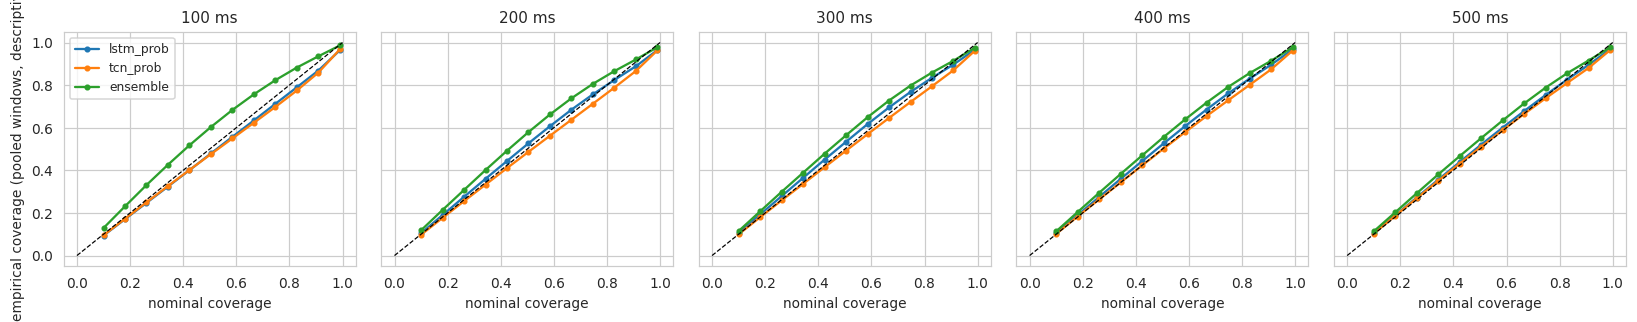

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/tmp/ipykernel_23/1588287104.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  rho = FM[FM.model == "ensemble"].pivot(index="subject", columns="horizon_ms", values="spearman_sigma_abs_err"); axs[2].boxplot([rho[c].dropna() for c in rho.columns], labels=rho.columns); axs[2].axhline(0, c="k", lw=.5)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.dateti

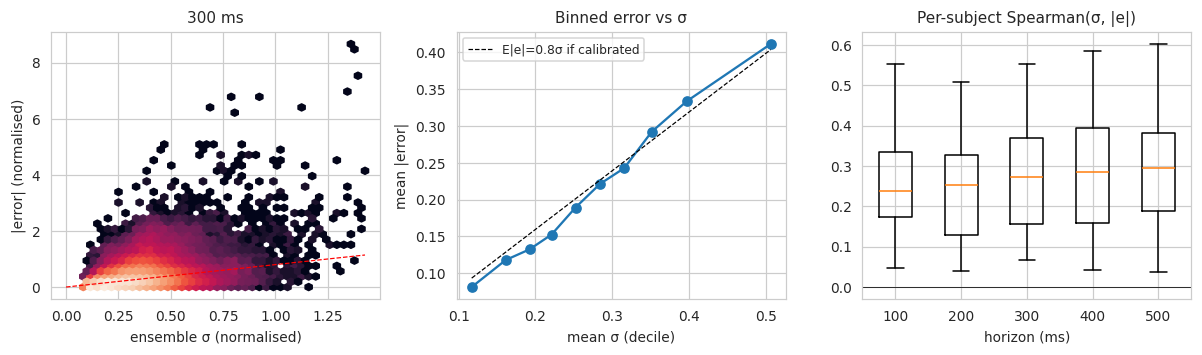

[18:58:16] STATUS uncertainty_calibration: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [20]:
UM_rows = FM[FM["model"].isin(["lstm_prob", "tcn_prob", "ensemble"])]
cols = ["nll", "picp90", "picp95", "mpiw95", "mean_sigma", "mean_sigma_units", "spearman_sigma_abs_err"] + [c for c in FM.columns if c.startswith("conf_")]
UNC_TABLE = summarize(FM[FM["model"].isin(["lstm_prob", "tcn_prob", "ensemble", "ridge", "persistence"])], ["model", "horizon_ms"], [c for c in cols if c in FM.columns])
save_table(UNC_TABLE, "uncertainty_metrics"); display(UNC_TABLE.round(3).head(30))
# coverage (reliability) curves
LEVELS = np.linspace(0.1, 0.99, 12)
def coverage_curve(model, j):
    mu, sg = PT[model]["mu"][:, j], PT[model]["sigma"][:, j]; e = np.abs(TEST["Y"][:, j] - mu); return np.array([(e <= sstats.norm.ppf(0.5 + l / 2) * sg).mean() for l in LEVELS])
fig, axs = plt.subplots(1, NH, figsize=(3 * NH, 3), sharey=True)
for j, a in enumerate(axs):
    for m in ["lstm_prob", "tcn_prob", "ensemble"]: a.plot(LEVELS, coverage_curve(m, j), marker="o", ms=3, label=m)
    a.plot([0, 1], [0, 1], "k--", lw=.8); a.set(title=f"{H_MS[j]} ms", xlabel="nominal coverage")
axs[0].set_ylabel("empirical coverage (pooled windows, descriptive)"); axs[0].legend(); fig.tight_layout()
savefig(fig, "fig07_calibration_coverage", "Empirical versus nominal central-interval coverage per forecast horizon (pooled test windows; subject-level CIs are in the tables).")
# error vs uncertainty
fig, axs = plt.subplots(1, 3, figsize=(11, 3.3)); j = NH // 2
sg = PT["ensemble"]["sigma"][:, j]; er = np.abs(TEST["Y"][:, j] - PT["ensemble"]["mu"][:, j]); hb = axs[0].hexbin(sg, er, gridsize=40, bins="log", mincnt=1)
axs[0].set(xlabel="ensemble σ (normalised)", ylabel="|error| (normalised)", title=f"{H_MS[j]} ms"); axs[0].plot([0, sg.max()], [0, 0.8 * sg.max()], "r--", lw=.8)
q = pd.qcut(sg, 10, duplicates="drop"); g = pd.DataFrame(dict(s=sg, e=er)).groupby(q, observed=True).mean(); axs[1].plot(g["s"], g["e"], "o-"); axs[1].plot(g["s"], 0.798 * g["s"], "k--", lw=.8, label="E|e|=0.8σ if calibrated")
axs[1].set(xlabel="mean σ (decile)", ylabel="mean |error|", title="Binned error vs σ"); axs[1].legend()
rho = FM[FM.model == "ensemble"].pivot(index="subject", columns="horizon_ms", values="spearman_sigma_abs_err"); axs[2].boxplot([rho[c].dropna() for c in rho.columns], labels=rho.columns); axs[2].axhline(0, c="k", lw=.5)
axs[2].set(title="Per-subject Spearman(σ, |e|)", xlabel="horizon (ms)"); fig.tight_layout()
savefig(fig, "fig08_uncertainty_vs_error", "Predicted uncertainty versus absolute forecast error (ensemble). Subject-level Spearman correlations test whether σ tracks error.")
mark("uncertainty_calibration")

# Section I — Distribution-shift experiment
For BIDMC the experiment is **within-dataset**: held-out-subject test performance plus, *only if* age could be parsed from the verified header comments for all subjects, an age-subgroup comparison (split at the training-subject median). Otherwise the subgroup analysis is reported as `NOT RUN`.

Reported per evaluation group: subject-level error, mean σ, interval coverage and calibration deterioration (PICP − nominal). Whether σ *tracks* deterioration is tested by comparing group-level changes in MAE and σ and by within-group σ–|error| correlation; no direction is assumed. Normalised amplitudes are used throughout; raw amplitudes are never compared across datasets.

,model,group,horizon_ms,n_subjects,mae,mae_lo,mae_hi,rmse,rmse_lo,rmse_hi,...,spearman_sigma_abs_err,spearman_sigma_abs_err_lo,spearman_sigma_abs_err_hi,conf_norm_10_picp,conf_norm_10_picp_lo,conf_norm_10_picp_hi,conf_abs_10_picp,conf_abs_10_picp_lo,conf_abs_10_picp_hi,picp95_minus_nominal
0,ensemble,test,100,50,0.041,0.036,0.046,0.061,0.052,0.070,...,0.253,0.222,0.285,0.898,0.879,0.915,0.898,0.871,0.922,0.010
1,ensemble,test,200,50,0.120,0.106,0.135,0.169,0.148,0.191,...,0.242,0.209,0.280,0.895,0.873,0.914,0.899,0.872,0.924,-0.003
2,ensemble,test,300,50,0.218,0.193,0.245,0.299,0.265,0.337,...,0.273,0.236,0.312,0.896,0.875,0.915,0.898,0.872,0.923,-0.007
3,ensemble,test,400,50,0.296,0.262,0.332,0.398,0.352,0.447,...,0.294,0.255,0.336,0.896,0.877,0.915,0.898,0.869,0.923,-0.007
4,ensemble,test,500,50,0.344,0.304,0.388,0.457,0.403,0.513,...,0.311,0.271,0.354,0.896,0.877,0.914,0.897,0.868,0.924,-0.005


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[18:58:19] STATUS distribution_shift: NOT RUN: only one evaluation group present ([np.str_('test')]); see held-out-subject results above


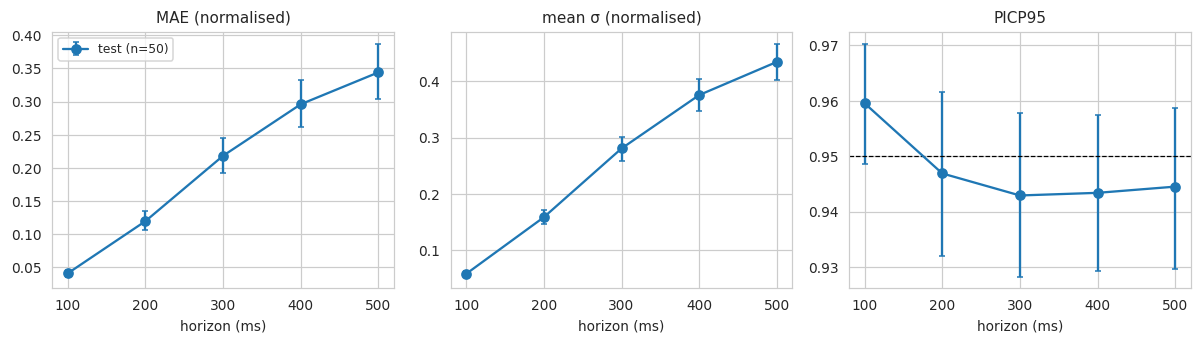

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [21]:
SHIFT = FM[FM["model"].isin(["ensemble", "lstm_prob", "persistence", "ridge"])].copy()
SHIFT_TABLE = summarize(SHIFT, ["model", "group", "horizon_ms"], ["mae", "rmse", "nll", "mean_sigma", "picp90", "picp95", "spearman_sigma_abs_err", "conf_norm_10_picp", "conf_abs_10_picp"])
SHIFT_TABLE["picp95_minus_nominal"] = SHIFT_TABLE.get("picp95", np.nan) - 0.95
save_table(SHIFT_TABLE, "distribution_shift_performance", top_level=False); display(SHIFT_TABLE[SHIFT_TABLE.model == "ensemble"].round(3))
groups = sorted(FM["group"].unique()); SHIFT_TESTS = []
if len(groups) >= 2:
    ref = groups[0]
    for g2 in groups[1:]:
        for j, hm in enumerate(H_MS):
            a = FM[(FM.model == "ensemble") & (FM.group == ref) & (FM.horizon_ms == hm)]; b = FM[(FM.model == "ensemble") & (FM.group == g2) & (FM.horizon_ms == hm)]
            for metric in ["mae", "mean_sigma", "picp95"]:
                if len(a) >= 2 and len(b) >= 2:
                    u = sstats.mannwhitneyu(a[metric], b[metric], alternative="two-sided")   # independent subjects -> unpaired
                    SHIFT_TESTS.append(dict(ref=ref, other=g2, horizon_ms=hm, metric=metric, ref_mean=a[metric].mean(), other_mean=b[metric].mean(), n_ref=len(a), n_other=len(b), p_raw=u.pvalue))
    ST = pd.DataFrame(SHIFT_TESTS)
    if len(ST): ST["p_holm"] = multipletests(ST["p_raw"], method="holm")[1]; display(ST.round(4)); save_table(ST, "distribution_shift_tests", top_level=False)
    mark("distribution_shift")
else:
    mark("distribution_shift", f"NOT RUN: only one evaluation group present ({groups}); see held-out-subject results above")
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2)); E = SHIFT_TABLE[SHIFT_TABLE.model == "ensemble"]
for a, (c, t) in zip(axs, [("mae", "MAE (normalised)"), ("mean_sigma", "mean σ (normalised)"), ("picp95", "PICP95")]):
    for g in groups:
        e = E[E.group == g]; a.errorbar(e.horizon_ms, e[c], yerr=[e[c] - e[c + "_lo"], e[c + "_hi"] - e[c]], marker="o", capsize=2, label=f"{g} (n={int(e.n_subjects.iloc[0])})")
    a.set(xlabel="horizon (ms)", title=t)
axs[2].axhline(.95, c="k", ls="--", lw=.8); axs[0].legend(); fig.tight_layout()
savefig(fig, "fig14_distribution_shift", "Ensemble forecast error, mean uncertainty and 95% coverage per evaluation group (subject-level bootstrap 95% CI).")

# Section J — Synthetic target motion
> **The respiratory waveform is NOT ground-truth organ displacement.** Anatomical motion can differ in amplitude, phase, nonlinearity, hysteresis and delay. The target is a *simulation assumption*:
>
> `x_target(t) = A · z(t)`, with `z` the causally filtered respiratory surrogate normalised by **training-subject** mean/std, `A = 5 mm` (primary), sensitivity `A ∈ {2, 5, 10} mm`. Units: mm. Command saturation `|u| ≤ 6A` (rarely active for z-scores).

No nonlinear mapping is used in the primary analysis (an optional one would be a labelled secondary experiment only).

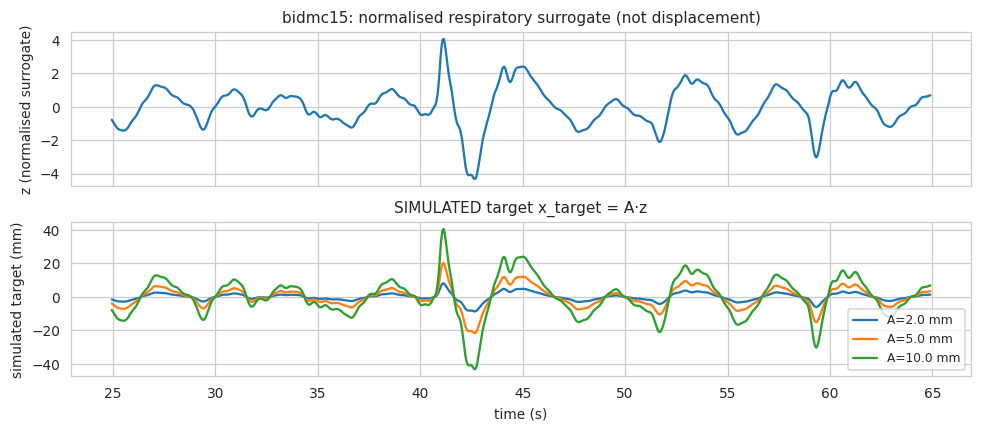

[18:58:21] STATUS synthetic_target: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [22]:
f0 = FOLDS[0]["fold"]; ws0 = FIT[f0]["sets"]["test"]; rid0 = ws0.rec[0]; sel0 = np.flatnonzero(ws0.rec == rid0)[:40 * FS_MODEL]
t0_ = ws0.loc[sel0] / FS_MODEL; z0 = ws0.last()[sel0]
fig, ax = plt.subplots(2, 1, figsize=(9, 4), sharex=True)
ax[0].plot(t0_, z0); ax[0].set(ylabel="z (normalised surrogate)", title=f"{rid0}: normalised respiratory surrogate (not displacement)")
for A in AMPLITUDES_MM: ax[1].plot(t0_, A * z0, label=f"A={A} mm")
ax[1].set(ylabel="simulated target (mm)", xlabel="time (s)", title="SIMULATED target x_target = A·z"); ax[1].legend(); fig.tight_layout()
savefig(fig, "fig_target_motion", "Normalised respiratory surrogate and the resulting SIMULATED target trajectory for three assumed amplitudes (simulation assumption, not a measurement).")
mark("synthetic_target")

# Section K — One-degree-of-freedom simulated robot
**All results below are SIMULATIONS, not physical-robot or clinical validation.**

| Symbol | Meaning | Unit | Value |
|---|---|---|---|
| `x*[k]` | simulated target position `A·z` | mm | — |
| `u[k]` | commanded position (set-point), saturated to `±6A` | mm | controller output |
| `p[k]` | actual robot position | mm | `p[0] = u[0]` per contiguous run |
| `α` | actuator lag parameter `1−exp(−dt/τ)`, τ = `TAU_ACT` | – | from config |
| `D` | **observation delay** (steps; 1 step = 50 ms): information at time k is the surrogate up to k−D | steps | 0…10 |
| `d_cmd` | **command delay** (extra transport delay of the command) | steps | `D_CMD` (default 0, so delays are not counted twice) |
| inference latency | model compute time | ms | benchmarked separately, assumed ≤ one step and **not** added to D |

Dynamics (forward-Euler/exact first-order lag, `dt = 50 ms`): `p[k+1] = p[k] + α (sat(u[k−d_cmd]) − p[k])`; tracking error `e[k] = x*[k] − p[k]`. A learned/predictive controller compensates the **observation** delay by forecasting `z[k]` from data up to `k−D` with horizon `D` (so `D = 0` ⇒ all forecast-based controllers equal the reactive one). The first `TRANSIENT_S` seconds of each contiguous run are excluded from metrics.

### Pre-declared outcomes (written before looking at test results)
* **Primary**: subject-level tracking RMSE (mm) of the uncertainty-aware blend vs reactive, predictive, fixed-blend (validation-tuned), fixed-blend-0.5 and Kalman controllers, for each delay D > 0; paired Wilcoxon + Holm correction over this family. **Primary failure-warning outcome**: ROC-AUC of ensemble σ for failure of the *predictive* controller (ε = 20 % of A = 1 mm, fixed a-priori) versus velocity baseline.
* **Exploratory**: everything else (other thresholds, amplitudes, forecasters, bands, secondary risk scores, distribution-shift tests).

PASSED test_robot_sinusoid; analytic gain 0.9543 RMSE(mm) vs delay [0,100,300,500ms]: [1.198 1.725 2.747 3.704]


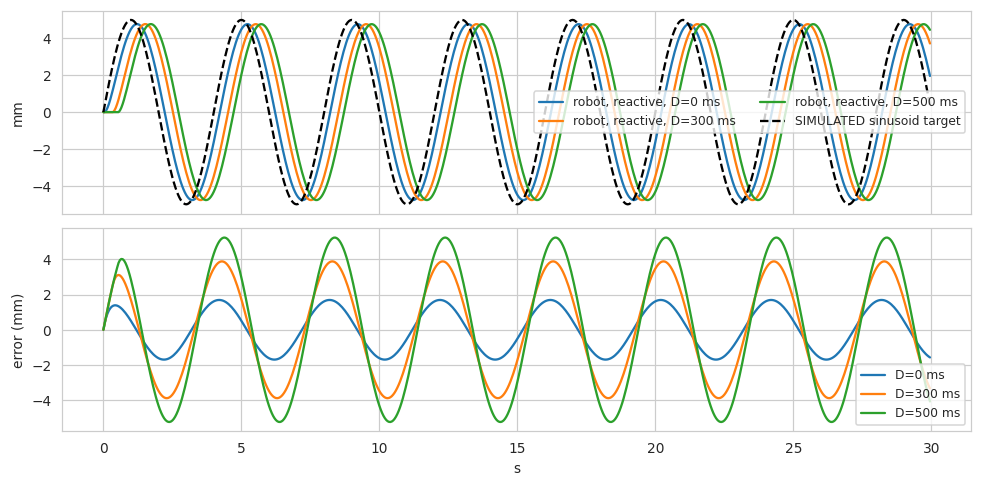

[18:58:22] STATUS robot_sinusoid_validation: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [23]:
ALPHA = 1 - math.exp(-DT / TAU_ACT); A0 = AMPLITUDE_MM; EPS_MM = EPS_FRAC * A0
CONTROLLERS = ["reactive", "predictive", "fixed_blend_0.5", "fixed_blend", "kalman", "uncertainty_aware", "ucpc", "trigger"]   # ucpc / trigger = revised controllers (v2)
PLANT_RATE_MM = None          # None = nominal plant; exploratory sensitivity only: actuator command slew limit [mm per step]

def robot_response(u, alpha, d_cmd, umax, p0):
    """First-order lag with optional command delay and saturation: p[k+1]=p[k]+alpha*(sat(u[k-d_cmd])-p[k]); returns p[0..n-1]."""
    uc = np.clip(u, -umax, umax)
    if d_cmd > 0: uc = np.r_[np.full(d_cmd, uc[0]), uc][:len(u)]
    return sps.lfilter([0.0, alpha], [1.0, -(1.0 - alpha)], uc, zi=[p0])[0]

def test_robot_sinusoid():
    f, A = 0.25, 5.0; t = np.arange(0, 120, DT); x = A * np.sin(2 * np.pi * f * t); p = robot_response(x, ALPHA, 0, 1e9, x[0])
    w = 2 * np.pi * f * DT; G = abs(ALPHA * np.exp(-1j * w) / (1 - (1 - ALPHA) * np.exp(-1j * w)))
    tail = slice(len(t) // 2, None); X = np.c_[np.sin(2 * np.pi * f * t[tail]), np.cos(2 * np.pi * f * t[tail])]
    coef = np.linalg.lstsq(X, p[tail], rcond=None)[0]; amp = np.hypot(*coef)
    assert abs(amp / A - G) < 0.01, f"simulated gain {amp/A:.4f} != analytic {G:.4f}"
    errs = []
    for D in [0, 2, 6, 10]:
        xd = np.r_[np.full(D, x[0]), x][:len(x)]; pd_ = robot_response(xd, ALPHA, 0, 1e9, x[0]); errs.append(np.sqrt(np.mean((x[len(x)//2:] - pd_[len(x)//2:]) ** 2)))
    assert all(np.diff(errs) > 0), "tracking error must increase with delay"
    return G, errs
G_theory, sin_errs = test_robot_sinusoid(); print("PASSED test_robot_sinusoid; analytic gain", round(G_theory, 4), "RMSE(mm) vs delay [0,100,300,500ms]:", np.round(sin_errs, 3))
t_ = np.arange(0, 30, DT); xs_ = A0 * np.sin(2 * np.pi * 0.25 * t_)
fig, axs = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
for D in [0, 6, 10]:
    xd = np.r_[np.full(D, xs_[0]), xs_][:len(xs_)]; p = robot_response(xd, ALPHA, 0, 6 * A0, xs_[0])
    axs[0].plot(t_, p, label=f"robot, reactive, D={D*50} ms"); axs[1].plot(t_, xs_ - p, label=f"D={D*50} ms")
axs[0].plot(t_, xs_, "k--", label="SIMULATED sinusoid target"); axs[0].set(ylabel="mm"); axs[0].legend(ncol=2); axs[1].set(ylabel="error (mm)", xlabel="s"); axs[1].legend()
fig.tight_layout(); savefig(fig, "fig_sim_validation_sinusoid", "SIMULATION validation on a sinusoidal target: robot position and tracking error for reactive control at three observation delays.")
mark("robot_sinusoid_validation")

# Section L — Controllers
All controllers output a **set-point for the target position at time k** using only information available at `k−D` (same signal availability, delay, actuator, saturation and evaluation windows):

| Controller | Set-point `u[k]/A` |
|---|---|
| reactive | `z[k−D]` |
| predictive | `μ_D` (forecast of `z[k]` from data to `k−D`, ensemble mean) |
| fixed_blend_0.5 | `0.5 μ_D + 0.5 z[k−D]` |
| fixed_blend | `w μ_D + (1−w) z[k−D]`, `w` chosen on `val_sel` per delay |
| kalman | Kalman h=D prediction `pos + vel·D·dt` (filtered state at k−D) |
| uncertainty_aware | `w_σ μ_D + (1−w_σ) z[k−D]`, `w_σ = exp(−σ_D/σ₀)`, `σ₀ = c · median(σ_D on val_sel)`, `c ∈ {0.25,…,8}` selected on `val_sel` per delay |

The proposed controller sees exactly what the baselines see (σ is a by-product of the same forecaster). It is **not** assumed to be better; this is tested in Sections M and O.

In [24]:
def make_bundle(ws): return dict(rec=ws.rec, loc=ws.loc, last=ws.last(), Y=ws.Y())
def fdict(split, f, name):
    if split == "val":
        P_ = FIT[f]["P"]["val_sel"][name]; return {k: P_.get(k) for k in ["mu", "sigma", "ale", "epi"]}
    m = TEST["fold"] == f; return {k: (PT[name][k][m] if PT[name].get(k) is not None else None) for k in ["mu", "sigma", "ale", "epi"]}
def bundle(split, f):
    if split == "val": return make_bundle(FIT[f]["sets"]["val_sel"])
    m = TEST["fold"] == f; return {k: TEST[k][m] for k in ["rec", "loc", "last", "Y"]}

DIAG, DIAG_LAST = {}, {}      # activation diagnostics of the revised controllers: (forecaster, controller, D, A) -> dict(clip=bool[N], trig=bool[N])
def run_bounds(rec, loc):
    brk = np.r_[True, (rec[1:] != rec[:-1]) | (np.diff(loc) != 1)]; st = np.flatnonzero(brk); return st, np.r_[st[1:], len(loc)]
def slew_limit(mu, r, rec, loc, trig=None):
    """Causal command-change limit inside each contiguous run: u[k] = u[k-1] + clip(mu[k] - u[k-1], -r[k], +r[k]); u[first] = mu[first] (r in the units of mu per step).
    With trig given, the limit is applied only where trig[k] is True (else u[k] = mu[k]). Returns (u, clipped) with clipped[k] = the limit was binding."""
    N = len(mu); rr = np.broadcast_to(np.asarray(r, dtype=float), (N,)).tolist(); m = np.asarray(mu, float).tolist(); tg = None if trig is None else np.asarray(trig, bool).tolist()
    u = [0.0] * N; cl = [False] * N; st, en = run_bounds(rec, loc)
    for a, b in zip(st.tolist(), en.tolist()):
        prev = m[a]; u[a] = prev
        for k in range(a + 1, b):
            if tg is not None and not tg[k]: prev = m[k]; u[k] = prev; continue
            d = m[k] - prev; lim = rr[k]
            if d > lim: prev += lim; cl[k] = True
            elif d < -lim: prev -= lim; cl[k] = True
            else: prev = m[k]
            u[k] = prev
    return np.asarray(u), np.asarray(cl)
def cmd_metrics(u, loc, rec, A, dg=None, m=None):
    """Command smoothness / saturation / activation per subject: total variation [mm/s] inside contiguous runs, share of saturated commands, constrained-mode shares."""
    ok = np.isfinite(u); contig = (np.diff(loc) == 1) & (rec[1:] == rec[:-1]) & ok[1:] & ok[:-1]; du = np.abs(np.diff(u))
    return dict(cmd_tv_mm_s=du[contig].mean() / DT if contig.any() else np.nan, sat_frac=float(np.mean(np.abs(u[ok]) >= UMAX_FACTOR * A - 1e-9)) if ok.any() else np.nan,
                clip_frac=float(dg["clip"][m].mean()) if dg is not None else np.nan, trig_frac=float(dg["trig"][m].mean()) if dg is not None else np.nan)

def command_z(ctrl, D, B, Fm, Fk, par, A=None):
    A = A0 if A is None else A
    last = B["last"]
    if D == 0 or ctrl == "reactive": return last
    c = H_STEPS.index(D); mu = Fm["mu"][:, c]
    if ctrl == "predictive": return mu
    if ctrl == "fixed_blend_0.5": return 0.5 * mu + 0.5 * last
    if ctrl == "fixed_blend": w = par["w"][D]; return w * mu + (1 - w) * last
    if ctrl == "kalman": return Fk[:, c]
    if ctrl == "uncertainty_aware":
        if Fm["sigma"] is None: raise ValueError("uncertainty-aware control needs a predictive σ")
        w = np.exp(-Fm["sigma"][:, c] / par["sigma0"][D]); return w * mu + (1 - w) * last
    if ctrl == "ucpc":           # UNCERTAINTY-AWARE CONSTRAINED PREDICTIVE CONTROL: command = forecast mean, but the allowed command change per step shrinks with predictive sigma
        if Fm["sigma"] is None: raise ValueError("ucpc needs a predictive sigma")
        p = par["ucpc"][D]; s_ = Fm["sigma"][:, c]
        if not np.isfinite(p["r_hi"]): u, cl = mu, np.zeros(len(mu), bool)                                   # validation chose "no constraint" -> identical to predictive
        else: u, cl = slew_limit(mu, (p["r_lo"] + (p["r_hi"] - p["r_lo"]) * np.exp(-s_ / p["sigma0"])) / A, B["rec"], B["loc"])   # r in mm/step -> z units
        DIAG_LAST.update(clip=cl, trig=np.zeros(len(mu), bool)); return u
    if ctrl == "trigger":        # UNCERTAINTY-TRIGGERED CONSTRAINED MODE: predictive normally; command-change limit r_c only while sigma > tau (tau = validation quantile)
        p = par["trig"][D]; trig = Fm["sigma"][:, c] > p["tau"]
        u, cl = slew_limit(mu, (p["r_c"] if np.isfinite(p["r_c"]) else np.inf) / A, B["rec"], B["loc"], trig=trig); DIAG_LAST.update(clip=cl, trig=trig); return u
    raise ValueError(ctrl)

def simulate(B, u_z, D, A):
    """Simulate contiguous runs. Anchor i carries the command for time k=i+D and the target x*(k)=A*z(i+D). Returns error/pos/target/command in mm."""
    N = len(B["loc"]); tgt = A * (B["last"] if D == 0 else B["Y"][:, H_STEPS.index(D)]); u = A * u_z
    err = np.full(N, np.nan); pos = np.full(N, np.nan)
    brk = np.r_[True, (B["rec"][1:] != B["rec"][:-1]) | (np.diff(B["loc"]) != 1)]; st = np.flatnonzero(brk); en = np.r_[st[1:], N]
    for a, b in zip(st, en):
        if b - a < MIN_RUN: continue
        uu = u[a:b]
        if PLANT_RATE_MM is not None: uu, _ = slew_limit(uu, PLANT_RATE_MM, B["rec"][a:b], B["loc"][a:b])          # exploratory actuator rate limit (plant property)
        p = robot_response(uu, ALPHA, D_CMD, UMAX_FACTOR * A, np.clip(uu[0], -UMAX_FACTOR * A, UMAX_FACTOR * A)); e = tgt[a:b] - p; e[:int(TRANSIENT_S * FS_MODEL)] = np.nan
        err[a:b] = e; pos[a:b] = p
    return err, pos, tgt, u

def tune_revised(fc, par):
    """Parameters of the revised controllers, chosen on VALIDATION (val_sel) tracking RMSE only. 'No constraint' (== predictive) is the default and wins ties."""
    for f in FIT:
        B = bundle("val", f); Fm = fdict("val", f, fc); par[f]["ucpc"] = {}; par[f]["trig"] = {}
        for D in DELAYS_STEPS:
            if D == 0: continue
            c = H_STEPS.index(D); mu = Fm["mu"][:, c]; s_ = Fm["sigma"][:, c]; med = float(np.median(s_))
            def score(u_z): return float(np.sqrt(np.nanmean(simulate(B, u_z, D, A0)[0] ** 2)))
            best = (score(mu), dict(r_hi=float("inf"), r_lo=float("inf"), c=float("nan"), sigma0=float("nan")))
            for r_hi in [x for x in UCPC_RHI_MM if np.isfinite(x)]:
                for r_lo in UCPC_RLO_MM:
                    if r_lo > r_hi: continue
                    for cc in UCPC_C:
                        u, _ = slew_limit(mu, (r_lo + (r_hi - r_lo) * np.exp(-s_ / (cc * med))) / A0, B["rec"], B["loc"]); sc = score(u)
                        if sc < best[0] - 1e-12: best = (sc, dict(r_hi=r_hi, r_lo=r_lo, c=cc, sigma0=cc * med))
            par[f]["ucpc"][D] = dict(best[1], val_rmse=best[0])
            bt = (score(mu), dict(q=1.0, tau=float("inf"), r_c=float("nan")))
            for q in [q_ for q_ in TRIG_Q if q_ < 1.0]:
                tau = float(np.quantile(s_, q))
                for rc in TRIG_RC_MM:
                    u, _ = slew_limit(mu, rc / A0, B["rec"], B["loc"], trig=s_ > tau); sc = score(u)
                    if sc < bt[0] - 1e-12: bt = (sc, dict(q=q, tau=tau, r_c=rc))
            par[f]["trig"][D] = dict(bt[1], val_rmse=bt[0])

def tune(fc):
    """Fixed-blend weight w and uncertainty scale sigma0 per delay and fold, chosen on val_sel (never on test)."""
    par = {}
    for f in FIT:
        B = bundle("val", f); Fm = fdict("val", f, fc); Fk = FIT[f]["P"]["val_sel"]["kalman"]["mu"]; par[f] = dict(w={}, sigma0={}, c={})
        for D in DELAYS_STEPS:
            if D == 0: continue
            sc = {}
            for w in W_GRID:
                e = simulate(B, w * Fm["mu"][:, H_STEPS.index(D)] + (1 - w) * B["last"], D, A0)[0]; sc[w] = np.sqrt(np.nanmean(e ** 2))
            par[f]["w"][D] = min(sc, key=sc.get)
            if Fm["sigma"] is not None:
                med = np.median(Fm["sigma"][:, H_STEPS.index(D)]); sc = {}
                for c in C_GRID:
                    w_ = np.exp(-Fm["sigma"][:, H_STEPS.index(D)] / (c * med)); e = simulate(B, w_ * Fm["mu"][:, H_STEPS.index(D)] + (1 - w_) * B["last"], D, A0)[0]; sc[c] = np.sqrt(np.nanmean(e ** 2))
                par[f]["c"][D] = min(sc, key=sc.get); par[f]["sigma0"][D] = par[f]["c"][D] * med
    if fc == "ensemble": tune_revised(fc, par)
    return par
PAR = {fc: tune(fc) for fc in ["ensemble", "lstm_prob", "tcn_prob", "tcn_det", "ridge"]}
save_json({fc: {str(f): v for f, v in p.items()} for fc, p in PAR.items()}, "controller_parameters_validation_selected.json")
display(pd.DataFrame([dict(forecaster="ensemble", fold=f, delay_ms=D * 50, w=PAR["ensemble"][f]["w"][D], c=PAR["ensemble"][f]["c"].get(D)) for f in FIT for D in DELAYS_STEPS if D > 0]).head(12))

def run_test(fc, ctrl, D, A, store=False):
    N = NTEST; err = np.full(N, np.nan); pos = np.full(N, np.nan); tgt = np.full(N, np.nan); u = np.full(N, np.nan); clip = np.zeros(N, bool); trg = np.zeros(N, bool)
    for f in FIT:
        m = TEST["fold"] == f; B = bundle("test", f); Fm = fdict("test", f, fc); Fk = PT["kalman"]["mu"][m]
        e, p, t, uu = simulate(B, command_z(ctrl, D, B, Fm, Fk, PAR[fc][f], A), D, A); err[m], pos[m], tgt[m], u[m] = e, p, t, uu
        if ctrl in ("ucpc", "trigger") and D > 0: clip[m] = DIAG_LAST["clip"]; trg[m] = DIAG_LAST["trig"]
    if ctrl in ("ucpc", "trigger"): DIAG[(fc, ctrl, D, A)] = dict(clip=clip, trig=trg)
    return err, pos, tgt, u

def track_metrics(e, eps):
    ok = np.isfinite(e); a = np.abs(e[ok]); fail = ok & (np.abs(np.where(ok, e, 0)) > eps); s, en = runs(fail); dur = (en - s) * DT
    return dict(mae=a.mean() if ok.any() else np.nan, rmse=np.sqrt((a ** 2).mean()) if ok.any() else np.nan, max_abs=a.max() if ok.any() else np.nan,
                p95_abs=np.percentile(a, 95) if ok.any() else np.nan, fail_count=len(s), fail_rate=fail.sum() / max(ok.sum(), 1), fail_time_s=fail.sum() * DT,
                mean_recovery_s=dur.mean() if len(s) else 0.0, n_samples=int(ok.sum()))
def suite(fc, ctrls, A, keep=None):
    rows = []
    for ctrl in ctrls:
        for D in DELAYS_STEPS:
            if D == 0 and ctrl != "reactive": continue          # all forecast-based controllers coincide with reactive at D=0
            e, _, _, u_ = run_test(fc, ctrl, D, A)
            if keep is not None: keep[(fc, ctrl, D)] = e
            for s in np.unique(TEST["subj"]):
                m = TEST["subj"] == s; rows.append(dict(forecaster=fc if ctrl not in ("reactive", "kalman") else "n/a", controller=ctrl, delay_ms=D * 50, amplitude_mm=A, subject=s,
                                                        group=TEST["grp"][m][0], eps_mm=EPS_FRAC * A0, **track_metrics(e[m], EPS_FRAC * A0), **cmd_metrics(u_[m], TEST["loc"][m], TEST["rec"][m], A, DIAG.get((fc, ctrl, D, A)), m)))
    return rows
ERR = {}
TM = pd.DataFrame(suite("ensemble", CONTROLLERS, A0, keep=ERR)); save_table(TM, "tracking_metrics"); mark("controllers_primary")

,forecaster,fold,delay_ms,w,c
0,ensemble,0,100,1.0,64
1,ensemble,0,200,1.0,64
2,ensemble,0,300,1.0,64
3,ensemble,0,400,1.0,64
4,ensemble,0,500,1.0,64
5,ensemble,1,100,1.0,64
6,ensemble,1,200,1.0,64
7,ensemble,1,300,1.0,64
8,ensemble,1,400,1.0,64
9,ensemble,1,500,1.0,64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[18:59:07] STATUS controllers_primary: RUN


In [25]:
# ---- sanity: a PERFECT forecaster must reproduce delay-free tracking (checks alignment end-to-end) ----
def test_oracle_alignment():
    """A PERFECT forecast must reproduce delay-free tracking: oracle command at anchor i is z(i+D) and the target is z(i+D), so after the actuator transient its error must equal the
    delay-free reactive error at anchor i+D (same run). This is a genuine end-to-end check of delay / horizon / run-boundary alignment."""
    f = FOLDS[0]["fold"]; B = bundle("test", f); D = 6; c = H_STEPS.index(D)
    e_or = simulate(B, B["Y"][:, c], D, A0)[0]; e_0 = simulate(B, B["last"], 0, A0)[0]
    i = np.arange(len(e_or) - D); same = (B["rec"][i] == B["rec"][i + D]) & (B["loc"][i + D] - B["loc"][i] == D); ok = same & np.isfinite(e_or[i]) & np.isfinite(e_0[i + D])
    assert ok.sum() > 1000, "too few comparable samples for the oracle alignment test"
    worst = float(np.max(np.abs(e_or[i][ok] - e_0[i + D][ok]))); assert worst < 0.1, f"oracle forecast does not reproduce delay-free tracking (max |diff| {worst:.3f} mm): alignment broken"
    assert np.nanmean(np.abs(e_or)) < np.nanmean(np.abs(simulate(B, B["last"], D, A0)[0])), "oracle forecast must beat delayed reactive control"
def test_slew_limit():
    rng = np.random.RandomState(0); mu = np.cumsum(rng.randn(500)); rec = np.zeros(500, int); loc = np.arange(500)             # synthetic input used ONLY to unit-test the limiter logic
    u, cl = slew_limit(mu, 0.3, rec, loc); assert np.all(np.abs(np.diff(u)) <= 0.3 + 1e-12) and cl.any(), "rate limit violated"
    u2, cl2 = slew_limit(mu, np.inf, rec, loc); assert np.array_equal(u2, mu) and not cl2.any(), "infinite limit must return the forecast"
    u3, _ = slew_limit(mu, 0.3, rec, loc, trig=np.zeros(500, bool)); assert np.array_equal(u3, mu), "untriggered mode must return the forecast"
    rec2 = np.r_[np.zeros(250, int), np.ones(250, int)]; u4, _ = slew_limit(mu, 0.3, rec2, loc); assert u4[250] == mu[250], "a new run must restart from the forecast"
for t_ in [test_oracle_alignment, test_slew_limit]: t_(); print("PASSED", t_.__name__)

M_ = TM[TM.amplitude_mm == A0]
T_SUM = summarize(M_, ["controller", "delay_ms"], ["mae", "rmse", "max_abs", "p95_abs", "fail_count", "fail_rate", "fail_time_s", "mean_recovery_s", "cmd_tv_mm_s", "sat_frac", "clip_frac", "trig_frac"])
save_table(T_SUM, "tracking_summary_by_controller_delay", top_level=False); display(T_SUM.pivot(index="delay_ms", columns="controller", values="rmse").round(3))

PASSED test_oracle_alignment
PASSED test_slew_limit


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


controller,fixed_blend,fixed_blend_0.5,kalman,predictive,reactive,trigger,ucpc,uncertainty_aware
delay_ms,,,,,,,,
0,NaN,NaN,NaN,NaN,2.139,NaN,NaN,NaN
100,2.191,2.618,2.257,2.191,3.054,2.191,2.191,2.211
200,2.396,3.111,2.681,2.396,3.885,2.396,2.396,2.423
300,2.646,3.558,3.375,2.646,4.620,2.646,2.646,2.676
400,2.819,3.914,4.208,2.819,5.267,2.819,2.825,2.852
500,2.916,4.191,5.115,2.916,5.840,2.916,2.918,2.950


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# Section M — Tracking metrics and plots
Metrics are computed **per subject** (windows from one subject are never treated as independent subjects) and then averaged across subjects with a subject-level bootstrap 95 % CI.

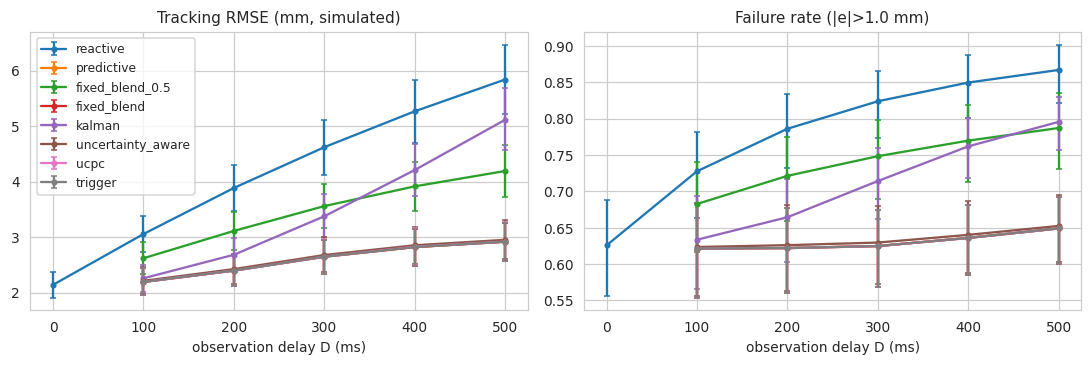

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


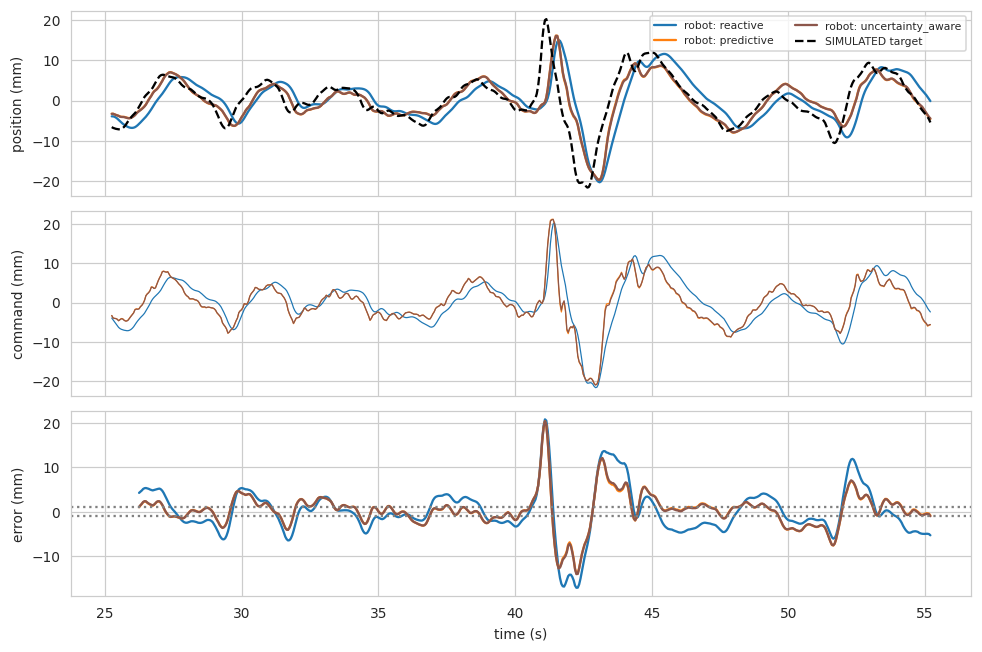

[18:59:17] STATUS tracking_metrics: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [26]:
colors = dict(zip(CONTROLLERS, sns.color_palette("tab10", len(CONTROLLERS))))
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
for c in CONTROLLERS:
    s = T_SUM[T_SUM.controller == c].sort_values("delay_ms")
    if c != "reactive": s = s[s.delay_ms > 0]
    for a, (m, t) in zip(axs, [("rmse", "Tracking RMSE (mm, simulated)"), ("fail_rate", f"Failure rate (|e|>{EPS_MM:.1f} mm)")]):
        a.errorbar(s.delay_ms, s[m], yerr=[s[m] - s[m + "_lo"], s[m + "_hi"] - s[m]], marker="o", ms=3, capsize=2, label=c, color=colors[c]); a.set(xlabel="observation delay D (ms)", title=t)
axs[0].legend(); fig.tight_layout(); savefig(fig, "fig10_11_error_failure_vs_latency", "SIMULATED tracking RMSE (left) and failure rate (right) versus observation delay, subject-level mean with 95% bootstrap CI.")
D_PLOT = 6; f_ = FOLDS[0]["fold"]; m_ = np.flatnonzero((TEST["fold"] == f_) & (TEST["rec"] == TEST["rec"][0]))[:30 * FS_MODEL]
fig, axs = plt.subplots(3, 1, figsize=(9, 6), sharex=True); tt = TEST["loc"][m_] / FS_MODEL + D_PLOT * DT
for c in ["reactive", "predictive", "uncertainty_aware"]:
    e, p, tg, u = run_test("ensemble", c, D_PLOT, A0); axs[0].plot(tt, p[m_], label=f"robot: {c}", color=colors[c]); axs[1].plot(tt, u[m_], color=colors[c], lw=.8, label=f"command: {c}"); axs[2].plot(tt, e[m_], color=colors[c], label=c)
axs[0].plot(tt, tg[m_], "k--", label="SIMULATED target"); axs[2].axhline(EPS_MM, c="gray", ls=":"); axs[2].axhline(-EPS_MM, c="gray", ls=":")
axs[0].set(ylabel="position (mm)"); axs[1].set(ylabel="command (mm)"); axs[2].set(ylabel="error (mm)", xlabel="time (s)"); axs[0].legend(ncol=2, fontsize=7); fig.tight_layout()
savefig(fig, "fig09_tracking_trajectories", f"SIMULATED target, robot position, commands and tracking error at D={D_PLOT*50} ms (A={A0} mm); dotted lines mark the failure threshold.")
mark("tracking_metrics")

# Section N — Tracking-failure prediction
* **Failure**: `failure(t+τ) = 1[|e(t+τ)| > ε]`, with the error timestamp `t+τ`, where `t` is the **prediction timestamp** (anchor: last observed sample) and `τ = D` is the forecast horizon equal to the observation delay. The robot state at `t+τ` depends only on commands issued before `t+τ`, which use data up to `t−1+...` — features below use samples **≤ t** only.
* **ε** = `EPS_FRAC · A` = 20 % of the assumed amplitude (1 mm for A = 5 mm), declared a priori on engineering grounds (not tuned); alternatives (10 %, 30 %) are reported as sensitivity.
* **Risk scores at `t`**: ensemble σ (total / aleatoric / epistemic), |respiratory velocity|, |last causally-available forecast error| (`|z[t] − μ_h[t−h]|`), forecast magnitude `|μ_h − z[t]|`.
* Operating thresholds (max-F1) and Platt probability maps are fitted on `val_sel` and applied unchanged to test. Bootstrap resamples **subjects**, not windows.

In [27]:
def shifted(arr, k, B):
    """arr[j-k] if windows j and j-k are in the same contiguous run, else NaN (strictly past information)."""
    out = np.full(len(arr), np.nan); j = np.arange(k, len(arr))
    ok = (B["rec"][j] == B["rec"][j - k]) & (B["loc"][j] - B["loc"][j - k] == k); out[j[ok]] = arr[j[ok] - k]; return out
def risk_scores(B, Fm, D):
    c = H_STEPS.index(D); last, mu = B["last"], Fm["mu"][:, c]
    return {"sigma_total": Fm["sigma"][:, c], "sigma_aleatoric": Fm["ale"][:, c], "sigma_epistemic": Fm["epi"][:, c],
            "abs_velocity": np.abs(last - shifted(last, 1, B)) / DT, "last_forecast_error": np.abs(last - shifted(mu, D, B)), "forecast_magnitude": np.abs(mu - last)}
def gather(split, ctrl, D, eps):
    """Scores/labels/subject ids for one split ('val' simulated with tuned params, or 'test')."""
    S, L, SU = {}, [], []
    if split == "test":
        e = ERR[("ensemble", ctrl, D)]; sc = {k: [] for k in ["sigma_total", "sigma_aleatoric", "sigma_epistemic", "abs_velocity", "last_forecast_error", "forecast_magnitude"]}
        for f in FIT:
            m = TEST["fold"] == f; B = bundle("test", f); r = risk_scores(B, fdict("test", f, "ensemble"), D)
            for k in sc: sc[k].append(r[k])
        S = {k: np.concatenate(v) for k, v in sc.items()}; err = e; SU = TEST["subj"]
        order = np.concatenate([np.flatnonzero(TEST["fold"] == f) for f in FIT]); inv = np.empty_like(order); inv[order] = np.arange(len(order)); S = {k: v[inv] for k, v in S.items()}
    else:
        sc = {}; errs, sus = [], []
        for f in FIT:
            B = bundle("val", f); Fm = fdict("val", f, "ensemble"); Fk = FIT[f]["P"]["val_sel"]["kalman"]["mu"]
            errs.append(simulate(B, command_z(ctrl, D, B, Fm, Fk, PAR["ensemble"][f]), D, A0)[0]); sus.append(FIT[f]["sets"]["val_sel"].subj)
            for k, v in risk_scores(B, Fm, D).items(): sc.setdefault(k, []).append(v)
        S = {k: np.concatenate(v) for k, v in sc.items()}; err = np.concatenate(errs); SU = np.concatenate(sus)
    ok = np.isfinite(err); y = (np.abs(np.where(ok, err, 0)) > eps).astype(int)
    for k in S: ok &= np.isfinite(S[k])
    return {k: v[ok] for k, v in S.items()}, y[ok], np.asarray(SU)[ok]

def boot_auc(S, y, su, fn, B_=None, seed=1):
    S, y, su = S[::BOOT_STRIDE], y[::BOOT_STRIDE], su[::BOOT_STRIDE]           # CI only: consecutive 50 ms windows are near-duplicates -> thin to every BOOT_STRIDE-th
    subs = np.unique(su); idx = {s: np.flatnonzero(su == s) for s in subs}; rng = np.random.RandomState(seed); out = []
    for _ in range(B_ or N_BOOT_FAIL):
        pick = rng.choice(subs, len(subs)); ii = np.concatenate([idx[s] for s in pick])
        if len(np.unique(y[ii])) == 2: out.append(fn(y[ii], S[ii]))
    return tuple(np.percentile(out, [2.5, 97.5])) if len(out) >= 10 else (np.nan, np.nan)

FP_ROWS, CURVES = [], {}
def failure_eval(ctrl, D, eps_frac, full=True):
    eps = eps_frac * A0; Sv, yv, _ = gather("val", ctrl, D, eps); St, yt, su = gather("test", ctrl, D, eps)
    if len(np.unique(yv)) < 2 or len(np.unique(yt)) < 2:
        return [dict(controller=ctrl, delay_ms=D * 50, eps_frac=eps_frac, score="ALL", note=f"NOT RUN: single-class labels (val prevalence {yv.mean():.3f}, test {yt.mean():.3f})")]
    # does sigma add information BEYOND |velocity|?  logistic regression on [|velocity|, sigma_total], fitted on VALIDATION windows only
    fv = np.c_[Sv["abs_velocity"], Sv["sigma_total"]]; m_f, s_f = fv.mean(0), fv.std(0) + 1e-12; lrc = LogisticRegression().fit((fv - m_f) / s_f, yv)
    Sv = dict(Sv, **{"velocity+sigma": lrc.decision_function((fv - m_f) / s_f)})
    St = dict(St, **{"velocity+sigma": lrc.decision_function((np.c_[St["abs_velocity"], St["sigma_total"]] - m_f) / s_f)})
    rows = []
    for k in St:
        s_t, s_v = St[k], Sv[k]; auc = roc_auc_score(yt, s_t); ap = average_precision_score(yt, s_t)
        r = dict(controller=ctrl, delay_ms=D * 50, eps_frac=eps_frac, eps_mm=eps, score=k, auc=auc, auprc=ap, prevalence_test=yt.mean(), prevalence_val=yv.mean(), n_windows=len(yt), n_subjects=len(np.unique(su)))
        if full:
            if k in BOOT_SCORES: r["auc_lo"], r["auc_hi"] = boot_auc(s_t, yt, su, roc_auc_score); r["auprc_lo"], r["auprc_hi"] = boot_auc(s_t, yt, su, average_precision_score)
            else: r["auc_lo"] = r["auc_hi"] = r["auprc_lo"] = r["auprc_hi"] = np.nan
            pa = [roc_auc_score(yt[su == s], s_t[su == s]) for s in np.unique(su) if len(np.unique(yt[su == s])) == 2]; r["subject_auc_mean"] = np.mean(pa) if pa else np.nan; r["subject_auc_n"] = len(pa)
            pr, rc, th = precision_recall_curve(yv, s_v); f1 = 2 * pr * rc / np.maximum(pr + rc, 1e-12); thr = th[np.argmax(f1[:-1])]       # operating point from VALIDATION
            pred = s_t >= thr; tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
            r.update(threshold=thr, precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1), f1=2 * tp / max(2 * tp + fp + fn, 1), tp=tp, fp=fp, fn=fn, tn=tn)
            lr = LogisticRegression().fit(np.c_[s_v], yv); pt = lr.predict_proba(np.c_[s_t])[:, 1]; r["brier"] = brier_score_loss(yt, pt); r["brier_baseline_prevalence"] = brier_score_loss(yt, np.full(len(yt), yv.mean()))
            if D == 6 and eps_frac == EPS_FRAC:
                fpr, tpr, _ = roc_curve(yt, s_t); p_, r_, _ = precision_recall_curve(yt, s_t); CURVES[(ctrl, k)] = dict(fpr=fpr, tpr=tpr, prec=p_, rec=r_, auc=auc, ap=ap, prev=yt.mean())
                fr_, mp_ = np.histogram(pt, bins=np.quantile(pt, np.linspace(0, 1, 9)))[1], None
                CURVES[(ctrl, k, "rel")] = pd.DataFrame(dict(p=pt, y=yt)).groupby(pd.qcut(pt, 8, duplicates="drop"), observed=True).mean()
        rows.append(r)
    return rows
for ctrl in FAIL_CTRLS:
    for D in [d for d in DELAYS_STEPS if d > 0]: FP_ROWS += failure_eval(ctrl, D, EPS_FRAC)
FP = pd.DataFrame(FP_ROWS); save_table(FP, "failure_prediction_metrics"); mark("failure_prediction")
display(FP[(FP.controller == "predictive")].pivot_table(index="delay_ms", columns="score", values="auc").round(3))
SENS = []
for fr_ in EPS_SENS:
    for D in [2, 6, 10]:
        for r in failure_eval("predictive", D, fr_, full=False): SENS.append(r)
SENS = pd.DataFrame(SENS); save_table(SENS, "failure_threshold_sensitivity", top_level=False); display(SENS[SENS.score.isin(["sigma_total", "abs_velocity"])].pivot_table(index=["eps_frac", "delay_ms"], columns="score", values="auc").round(3))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datet

[19:05:57] STATUS failure_prediction: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


score,abs_velocity,forecast_magnitude,last_forecast_error,sigma_aleatoric,sigma_epistemic,sigma_total,velocity+sigma
delay_ms,,,,,,,
100,0.939,0.871,0.671,0.761,0.671,0.763,0.940
200,0.878,0.855,0.611,0.721,0.636,0.723,0.883
300,0.768,0.760,0.602,0.689,0.621,0.689,0.782
400,0.693,0.705,0.600,0.678,0.593,0.677,0.721
500,0.646,0.686,0.608,0.679,0.579,0.678,0.694


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datet

score              abs_velocity  sigma_total
eps_frac delay_ms                           
0.1      100              0.916        0.741
         300              0.740        0.672
         500              0.626        0.655
0.2      100              0.939        0.763
         300              0.768        0.689
         500              0.646        0.678
0.3      100              0.951        0.775
         300              0.785        0.701
         500              0.659        0.696

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


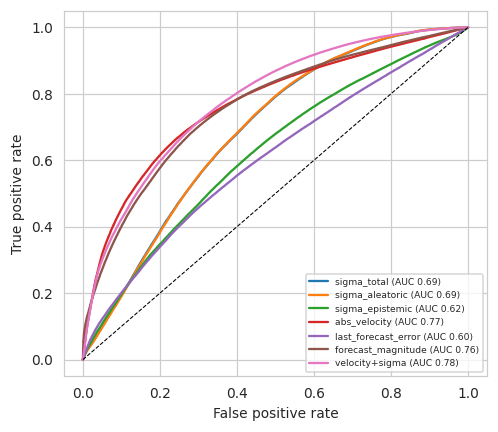

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


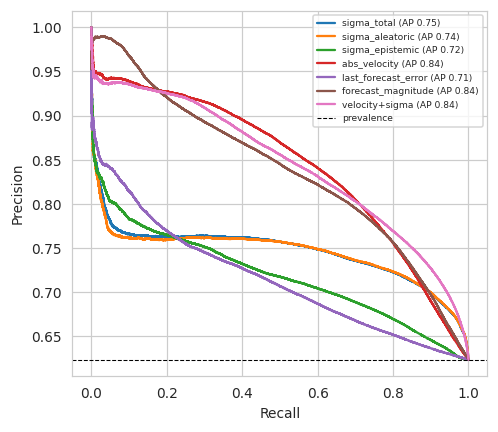

[19:06:26] STATUS failure_curves: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [28]:
for kind, fig_name, xl, yl, cap in [("roc", "fig12_roc_failure", "False positive rate", "True positive rate", "ROC curves for predicting future tracking failure (predictive controller, D=300 ms)."),
                                      ("pr", "fig13_pr_failure", "Recall", "Precision", "Precision–recall curves for predicting future tracking failure (predictive controller, D=300 ms).")]:
    fig, ax = plt.subplots(figsize=(4.6, 4))
    for k in ["sigma_total", "sigma_aleatoric", "sigma_epistemic", "abs_velocity", "last_forecast_error", "forecast_magnitude", "velocity+sigma"]:
        c = CURVES.get(("predictive", k))
        if c is None: continue
        if kind == "roc": ax.plot(c["fpr"], c["tpr"], label=f"{k} (AUC {c['auc']:.2f})")
        else: ax.plot(c["rec"], c["prec"], label=f"{k} (AP {c['ap']:.2f})")
    if kind == "roc": ax.plot([0, 1], [0, 1], "k--", lw=.7)
    elif ("predictive", "sigma_total") in CURVES: ax.axhline(CURVES[("predictive", "sigma_total")]["prev"], c="k", ls="--", lw=.7, label="prevalence")
    ax.set(xlabel=xl, ylabel=yl); ax.legend(fontsize=6); fig.tight_layout(); savefig(fig, fig_name, cap)
mark("failure_curves")

# Section O — Statistical analysis
Subject (or infant) is the unit of analysis. For each delay D > 0 and each comparator, paired per-subject differences in tracking RMSE (`UA − comparator`; negative favours the uncertainty-aware blend) are tested with the **Wilcoxon signed-rank test** (two-sided; only if n ≥ 6 so that p < 0.05 is attainable), with the matched-pairs rank-biserial effect size, mean difference and subject-level bootstrap 95 % CI. **Holm correction** is applied across the declared primary family. With few subjects, results are low-powered; non-significance is *not* evidence of equivalence.

In [29]:
def paired(df, a, b, metric="rmse"):
    pv = df.pivot_table(index="subject", columns="controller", values=metric); d = (pv[a] - pv[b]).dropna(); n = len(d)
    r = dict(a=a, b=b, metric=metric, n=n, mean_diff=d.mean() if n else np.nan, median_diff=d.median() if n else np.nan)
    r["ci_lo"], r["ci_hi"] = boot_ci(d.values) if n >= 2 else (np.nan, np.nan)
    nz = d[d != 0]
    if n >= 6 and len(nz) >= 1:
        w = sstats.wilcoxon(nz, alternative="two-sided"); rk = sstats.rankdata(np.abs(nz)); r["p_raw"] = w.pvalue; r["effect_rank_biserial"] = (rk[nz > 0].sum() - rk[nz < 0].sum()) / rk.sum()
    else: r["p_raw"] = np.nan; r["effect_rank_biserial"] = np.nan; r["note"] = "n<6: Wilcoxon not applicable"
    return r
rows = []
for D in [d * 50 for d in DELAYS_STEPS if d > 0]:
    sub = TM[(TM.delay_ms == D) & (TM.amplitude_mm == A0)]
    for other in ["reactive", "predictive", "fixed_blend", "fixed_blend_0.5", "kalman"]: rows.append(dict(delay_ms=D, family="primary", **paired(sub, "uncertainty_aware", other)))
    rows.append(dict(delay_ms=D, family="exploratory", **paired(sub, "predictive", "reactive")))
    rows.append(dict(delay_ms=D, family="exploratory", **paired(sub, "fixed_blend", "predictive")))
    for new in ["ucpc", "trigger"]:                      # revised controllers (prespecified family 'primary_revised': RMSE vs predictive and vs reactive)
        for other in ["predictive", "reactive"]: rows.append(dict(delay_ms=D, family="primary_revised", **paired(sub, new, other)))
        rows.append(dict(delay_ms=D, family="exploratory", **paired(sub, new, "uncertainty_aware")))
        for met in ["fail_rate", "cmd_tv_mm_s"]: rows.append(dict(delay_ms=D, family="exploratory_" + met, **paired(sub, new, "predictive", metric=met)))
STAT = pd.DataFrame(rows); STAT["p_holm"] = np.nan
for fam in ["primary", "primary_revised"]:                                     # Holm correction within each prespecified family
    pm = (STAT.family == fam) & STAT.p_raw.notna()
    if pm.sum(): STAT.loc[pm, "p_holm"] = multipletests(STAT.loc[pm, "p_raw"], method="holm")[1]
# failure-warning: sigma vs velocity, paired per-subject AUC (exploratory)
fa = []
if len(FP) and "subject_auc_mean" in FP:
    pass
def subj_auc(ctrl, D, score):
    St, yt, su = gather("test", ctrl, D, EPS_MM); return {s: roc_auc_score(yt[su == s], St[score][su == s]) for s in np.unique(su) if len(np.unique(yt[su == s])) == 2}
for D in [2, 6, 10]:
    a, b = subj_auc("predictive", D, "sigma_total"), subj_auc("predictive", D, "abs_velocity"); common = sorted(set(a) & set(b)); d = np.array([a[s] - b[s] for s in common])
    r = dict(delay_ms=D * 50, family="exploratory_auc", a="sigma_total_AUC", b="abs_velocity_AUC", n=len(d), mean_diff=d.mean() if len(d) else np.nan, p_raw=np.nan)
    r["ci_lo"], r["ci_hi"] = boot_ci(d) if len(d) > 1 else (np.nan, np.nan)
    if len(d) >= 6 and (d != 0).any(): r["p_raw"] = sstats.wilcoxon(d[d != 0]).pvalue
    fa.append(r)
STAT = pd.concat([STAT, pd.DataFrame(fa)], ignore_index=True); save_table(STAT, "statistical_tests"); display(STAT.round(4))
print(f"Subjects per comparison: n={int(STAT['n'].max())}. With small n the tests are underpowered; do not read non-significance as equivalence.")
mark("statistics")

,delay_ms,family,a,b,metric,n,mean_diff,median_diff,ci_lo,ci_hi,p_raw,effect_rank_biserial,note,p_holm
0,100,primary,uncertainty_aware,reactive,rmse,50,-0.8439,-0.8809,-0.9305,-0.7582,0.0000,-1.0000,NaN,0.0
1,100,primary,uncertainty_aware,predictive,rmse,50,0.0194,0.0181,0.0161,0.0230,0.0000,1.0000,NaN,0.0
2,100,primary,uncertainty_aware,fixed_blend,rmse,50,0.0194,0.0181,0.0161,0.0230,0.0000,1.0000,NaN,0.0
3,100,primary,uncertainty_aware,fixed_blend_0.5,rmse,50,-0.4074,-0.4300,-0.4497,-0.3659,0.0000,-1.0000,NaN,0.0
4,100,primary,uncertainty_aware,kalman,rmse,50,-0.0461,-0.0563,-0.0600,-0.0311,0.0000,-0.8353,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,500,exploratory_fail_rate,trigger,predictive,fail_rate,50,0.0000,0.0000,0.0000,0.0000,NaN,NaN,n<6: Wilcoxon not applicable,NaN
84,500,exploratory_cmd_tv_mm_s,trigger,predictive,cmd_tv_mm_s,50,0.0000,0.0000,-0.0000,0.0000,0.1659,0.2267,NaN,NaN
85,100,exploratory_auc,sigma_total_AUC,abs_velocity_AUC,NaN,50,-0.2702,NaN,-0.2967,-0.2433,0.0000,NaN,NaN,NaN
86,300,exploratory_auc,sigma_total_AUC,abs_velocity_AUC,NaN,50,-0.1243,NaN,-0.1551,-0.0937,0.0000,NaN,NaN,NaN


Subjects per comparison: n=50. With small n the tests are underpowered; do not read non-significance as equivalence.
[19:06:35] STATUS statistics: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# Section P — Ablation and sensitivity studies (one factor at a time)
Controller tuning parameters (`w`, `σ₀`) are the validation-selected ones from the primary amplitude; because the plant is linear below saturation, errors scale with `A`, while the failure threshold stays at the *absolute* 1 mm so amplitude changes task difficulty.

In [30]:
ABL = []
def add(ablation, setting, df, metric="rmse", by=("delay_ms",)):
    for k, g in df.groupby(list(by)):
        ci = boot_ci(g.groupby("subject")[metric].mean().values); ABL.append(dict(ablation=ablation, setting=setting, **dict(zip(by, k if isinstance(k, tuple) else (k,))), metric=metric,
                                                                             value=g.groupby("subject")[metric].mean().mean(), ci_lo=ci[0], ci_hi=ci[1], n_subjects=g.subject.nunique()))
for c, name in [("reactive", "1 no prediction"), ("predictive", "1/2 predictive"), ("fixed_blend", "2/3 fixed blend (val-tuned)"), ("fixed_blend_0.5", "2 fixed blend 0.5"), ("uncertainty_aware", "3 uncertainty-aware"), ("kalman", "kalman"), ("ucpc", "4a constrained UCPC (revised)"), ("trigger", "4b triggered mode (revised)")]:
    add("controller_ladder", name, TM[(TM.controller == c) & (TM.amplitude_mm == A0)])
EXTRA = []
for fc in ["lstm_prob", "tcn_prob", "tcn_det", "ridge"]:
    EXTRA += suite(fc, ["predictive", "fixed_blend"] + (["uncertainty_aware"] if fc in ("lstm_prob", "tcn_prob") else []), A0)
EXTRA_DF = pd.DataFrame(EXTRA)
for (fc, c), g in EXTRA_DF.groupby(["forecaster", "controller"]): add("forecaster_family", f"{fc}/{c}", g)
for c in ["predictive", "fixed_blend", "uncertainty_aware"]: add("forecaster_family", f"ensemble/{c}", TM[(TM.controller == c) & (TM.amplitude_mm == A0)])
AMP = []
for A in [a for a in AMPLITUDES_MM if a != A0]: AMP += suite("ensemble", ["reactive", "predictive", "fixed_blend", "uncertainty_aware"], A)
AMP_DF = pd.DataFrame(AMP)
for (A, c), g in pd.concat([AMP_DF, TM[TM.controller.isin(["reactive", "predictive", "fixed_blend", "uncertainty_aware"])]]).groupby(["amplitude_mm", "controller"]): add("amplitude_sensitivity", f"A={A}mm/{c}", g)
add("amplitude_sensitivity_fail", "fail_rate", pd.concat([AMP_DF, TM]), metric="fail_rate", by=("amplitude_mm", "controller", "delay_ms"))
for r in SENS.to_dict("records"):
    if r.get("score") in ("sigma_total", "abs_velocity"): ABL.append(dict(ablation="failure_threshold", setting=f"eps={r['eps_frac']:.0%}A/{r['score']}", delay_ms=r["delay_ms"], metric="auc", value=r["auc"], n_subjects=r.get("n_subjects")))
for r in FM[FM.model.isin(["ensemble", "lstm_prob", "tcn_prob"])].groupby(["model", "horizon_ms"])[["picp95", "conf_abs_5_picp", "conf_norm_5_picp", "mpiw95", "conf_abs_5_mpiw", "conf_norm_5_mpiw"]].mean().reset_index().to_dict("records"):
    for k in ["picp95", "conf_abs_5_picp", "conf_norm_5_picp", "mpiw95", "conf_abs_5_mpiw", "conf_norm_5_mpiw"]:
        if pd.notna(r.get(k)): ABL.append(dict(ablation="conformal_before_after", setting=f"{r['model']}/{k}", horizon_ms=r["horizon_ms"], metric=k, value=r[k]))
# alternative preprocessing bands: re-stream records, re-window with the SAME folds, refit ridge/persistence only (no deep retraining)
REC_MAIN = REC
for band in ALT_BANDS:
    try:
        REC_ALT, fails = build_records(band); REC_ALT = {k: v for k, v in REC_ALT.items() if k in REC_MAIN}; REC = REC_ALT
        for f in FOLDS:
            S_ = build_fold_sets(f); a = FIT[f["fold"]]["info"]["ridge_alpha"]; rg = Ridge(alpha=a).fit(S_["train"].X(), S_["train"].Y()); te = S_["test"]
            for nm, mu in [("ridge", rg.predict(te.X())), ("persistence", np.repeat(te.last()[:, None], NH, 1))]:
                for s in np.unique(te.subj):
                    m = te.subj == s
                    for j in range(NH): ABL.append(dict(ablation="preprocessing_band", setting=f"{nm}/{band[0]}-{band[1]}Hz", horizon_ms=H_MS[j], metric="mae_norm", subject=s, value=np.abs(te.Y()[m][:, j] - mu[m][:, j]).mean()))
    except Exception as e:
        log(f"band ablation {band} FAILED: {type(e).__name__}: {e}"); ABL.append(dict(ablation="preprocessing_band", setting=str(band), note=f"NOT RUN: {e}"))
    finally: REC = REC_MAIN
for nm in ["ridge", "persistence"]:
    for s, g in FM[FM.model == nm].groupby(["subject", "horizon_ms"]): ABL.append(dict(ablation="preprocessing_band", setting=f"{nm}/{BAND[0]}-{BAND[1]}Hz", horizon_ms=s[1], metric="mae_norm", subject=s[0], value=g["mae"].mean()))
# ---- exploratory plant sensitivities: parameters tuned on the NOMINAL plant are kept (robustness, not re-tuning); n = all test subjects ----
SENS_CTRLS = ["reactive", "predictive", "uncertainty_aware", "ucpc", "trigger"]
def _plant_sens(tag, label):
    d = pd.DataFrame(suite("ensemble", SENS_CTRLS, A0))
    for c in SENS_CTRLS:
        add(tag, f"{label}/{c}", d[d.controller == c]); add(tag + "_cmd_tv", f"{label}/{c}", d[d.controller == c], metric="cmd_tv_mm_s")
try:
    _ALPHA0, _DCMD0 = ALPHA, D_CMD
    _plant_sens("exploratory_actuator_tau", f"tau={TAU_ACT}s(nominal)")
    for tau_ in TAU_SENS:
        ALPHA = 1 - math.exp(-DT / tau_); _plant_sens("exploratory_actuator_tau", f"tau={tau_}s")
    ALPHA = _ALPHA0
    for dc_ in DCMD_SENS:
        D_CMD = dc_; _plant_sens("exploratory_command_delay", f"cmd_delay={dc_ * 50}ms")
    D_CMD = _DCMD0
    for r_ in PLANT_RATE_SENS_MM:
        PLANT_RATE_MM = r_; _plant_sens("exploratory_actuator_rate_limit", f"rate<={r_}mm/step")
    PLANT_RATE_MM = None; mark("sensitivity_plant")
except Exception as e:
    ALPHA, D_CMD, PLANT_RATE_MM = _ALPHA0, _DCMD0, None; log(f"plant sensitivity FAILED: {type(e).__name__}: {e}"); mark("sensitivity_plant", f"FAILED: {type(e).__name__}: {e}")
# ---- exploratory measurement-noise sensitivity (ridge forecaster refitted per fold on TRAIN; noise added to the OBSERVED history only, the target stays clean) ----
try:
    NZ = []
    for sn in NOISE_SENS:
        for f in FOLDS:
            S_ = FOLD_SETS[f["fold"]]; te = S_["test"]; Xte = te.X(); rg = Ridge(alpha=FIT[f["fold"]]["info"]["ridge_alpha"]).fit(S_["train"].X(), S_["train"].Y())
            Xn = Xte + sn * np.random.RandomState(SEED + 1000 + f["fold"]).randn(*Xte.shape); mu_n = rg.predict(Xn); Bn = dict(rec=te.rec, loc=te.loc, last=Xn[:, -1], Y=te.Y())
            for D in [2, 6, 10]:
                for nm, cmd in [("reactive", Bn["last"]), ("ridge_predictive", mu_n[:, H_STEPS.index(D)])]:
                    e = simulate(Bn, cmd, D, A0)[0]
                    for s in np.unique(te.subj): NZ.append(dict(subject=s, controller=nm, delay_ms=D * 50, noise_sd=sn, **track_metrics(e[te.subj == s], EPS_FRAC * A0)))
    NZ = pd.DataFrame(NZ)
    for (sn, c), g in NZ.groupby(["noise_sd", "controller"]): add("exploratory_measurement_noise", f"noise={sn}SD/{c}", g)
    mark("sensitivity_measurement_noise")
except Exception as e:
    log(f"noise sensitivity FAILED: {type(e).__name__}: {e}"); mark("sensitivity_measurement_noise", f"FAILED: {type(e).__name__}: {e}")
ABL_DF = pd.DataFrame(ABL); ABL_DF["design"] = np.where(ABL_DF.ablation.isin(["controller_ladder"]), "confirmatory (primary comparisons: statistical_tests.csv)", "exploratory")
save_table(ABL_DF, "ablation_results"); mark("ablation")
display(ABL_DF[ABL_DF.ablation == "controller_ladder"].pivot_table(index="delay_ms", columns="setting", values="value").round(3))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


preprocess band=(0.05, 1.0):   0%|          | 0/53 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


preprocess band=(0.1, 1.0):   0%|          | 0/53 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


...

[19:09:16] STATUS sensitivity_plant: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[19:09:29] STATUS sensitivity_measurement_noise: RUN
[19:09:29] STATUS ablation: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


setting,1 no prediction,1/2 predictive,2 fixed blend 0.5,2/3 fixed blend (val-tuned),3 uncertainty-aware,4a constrained UCPC (revised),4b triggered mode (revised),kalman
delay_ms,,,,,,,,
0.0,2.139,NaN,NaN,NaN,NaN,NaN,NaN,NaN
100.0,3.054,2.191,2.618,2.191,2.211,2.191,2.191,2.257
200.0,3.885,2.396,3.111,2.396,2.423,2.396,2.396,2.681
300.0,4.620,2.646,3.558,2.646,2.676,2.646,2.646,3.375
400.0,5.267,2.819,3.914,2.819,2.852,2.825,2.819,4.208
500.0,5.840,2.916,4.191,2.916,2.950,2.918,2.916,5.115


# Section Q — Publication figures and tables
Figures 2, 3, 7, 8, 9, 10/11, 12, 13, 14 were saved above; the remaining required ones follow. Tables are saved as CSV (results root or `tables/`) and Markdown (`tables/`). Every plot uses computed outputs only.

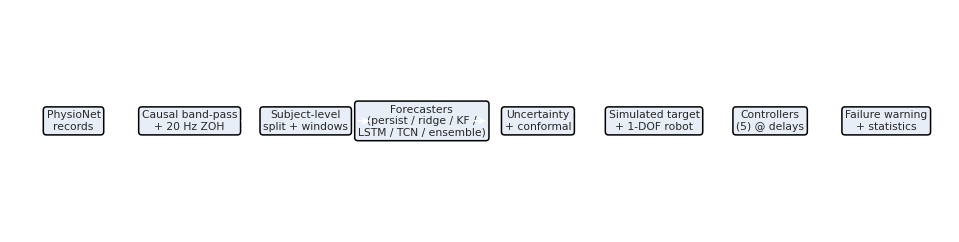

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
/usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarni

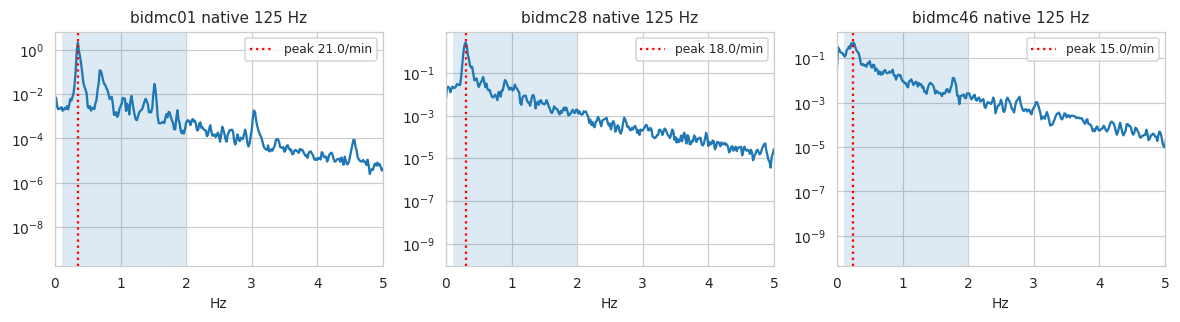

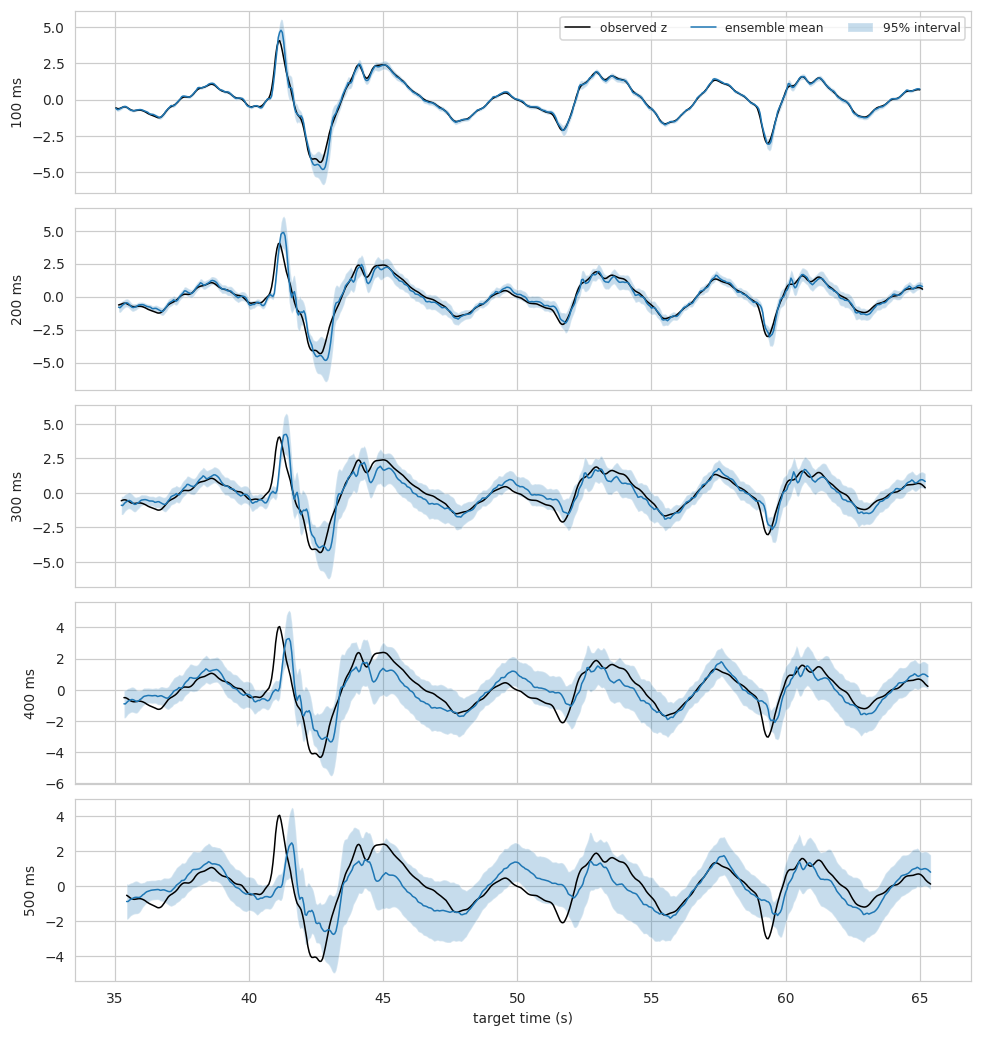

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


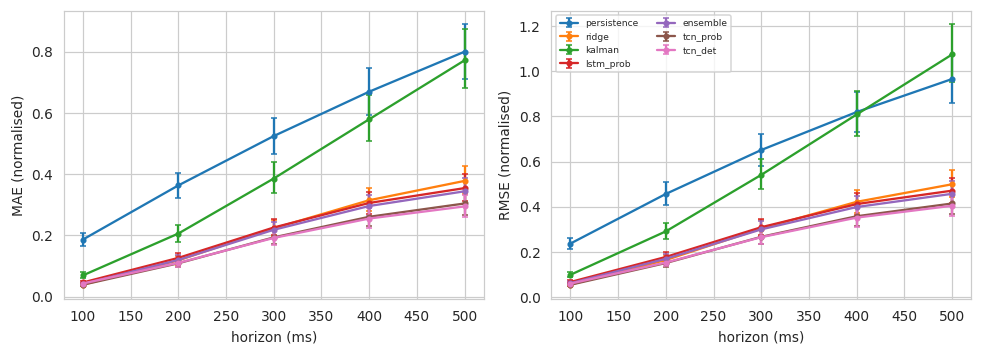

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


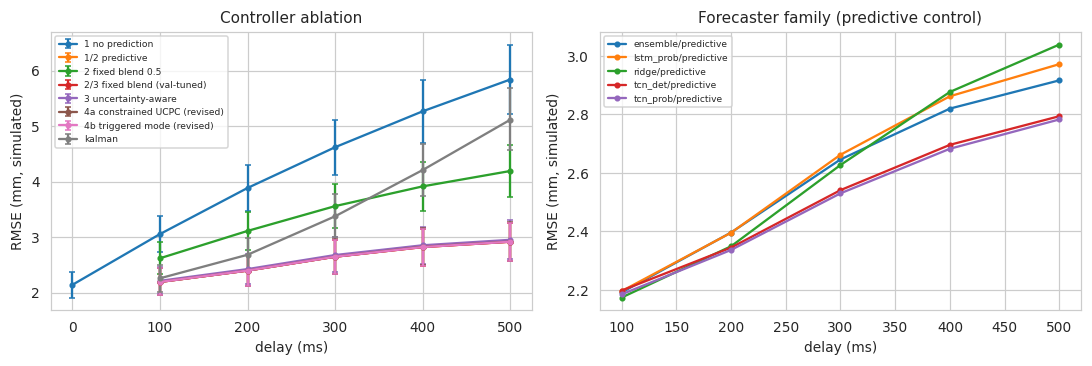

[19:09:35] STATUS figures_tables: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [31]:
# Fig 1: pipeline (schematic, no numbers)
fig, ax = plt.subplots(figsize=(11, 2.6)); ax.axis("off")
steps = ["PhysioNet\nrecords", "Causal band-pass\n+ 20 Hz ZOH", "Subject-level\nsplit + windows", "Forecasters\n(persist / ridge / KF /\nLSTM / TCN / ensemble)", "Uncertainty\n+ conformal", "Simulated target\n+ 1-DOF robot", "Controllers\n(5) @ delays", "Failure warning\n+ statistics"]
for i, s in enumerate(steps):
    ax.text(i * 1.3, 0.5, s, ha="center", va="center", fontsize=7, bbox=dict(boxstyle="round", fc="#e8eef7", ec="k"))
    if i: ax.annotate("", xy=(i * 1.3 - .55, .5), xytext=((i - 1) * 1.3 + .55, .5), arrowprops=dict(arrowstyle="->"))
ax.set_xlim(-.7, 9.8); ax.set_ylim(0, 1); savefig(fig, "fig01_pipeline", "Overall research pipeline (all robot results are simulations).")
# Fig 4: native-rate spectra (descriptive)
fig, axs = plt.subplots(1, len(EDA_REPS), figsize=(3.6 * len(EDA_REPS), 3), squeeze=False)
for a, r in zip(axs[0], EDA_REPS):
    row = INV[INV.record == r].iloc[0]; fs = float(row["fs"]); n0 = int(row["start_s"] * fs)
    x = wfdb.rdrecord(row["path"], sampfrom=n0, sampto=n0 + int(min(300, row["dur_s"]) * fs), channels=[int(row["resp_idx"])], physical=True).p_signal[:, 0]; x = x[np.isfinite(x)]
    fr, pw = sps.welch(x - x.mean(), fs=fs, nperseg=min(len(x), int(60 * fs))); a.semilogy(fr, pw); a.set(xlim=(0, 5), title=f"{r} native {fs:g} Hz", xlabel="Hz"); a.axvspan(*BAND, alpha=.15)
    pk = fr[(fr > .05) & (fr < 3)][np.argmax(pw[(fr > .05) & (fr < 3)])]; a.axvline(pk, c="r", ls=":", label=f"peak {60*pk:.1f}/min"); a.legend()
fig.tight_layout(); savefig(fig, "fig04_eda_power_spectra", "Welch power spectra at native sampling rate for representative records; shaded = analysis passband (descriptive EDA).")
# Fig 5: forecasts with uncertainty bands
rid = TEST["rec"][0]; mk = np.flatnonzero(TEST["rec"] == rid)[200:200 + 30 * FS_MODEL]
fig, axs = plt.subplots(NH, 1, figsize=(9, 1.9 * NH), sharex=True)
for j, a in enumerate(axs):
    tt = (TEST["loc"][mk] + H_STEPS[j]) / FS_MODEL; mu, sg = PT["ensemble"]["mu"][mk, j], PT["ensemble"]["sigma"][mk, j]
    a.plot(tt, TEST["Y"][mk, j], "k", lw=1, label="observed z"); a.plot(tt, mu, lw=1, label="ensemble mean"); a.fill_between(tt, mu - Z95 * sg, mu + Z95 * sg, alpha=.25, label="95% interval"); a.set_ylabel(f"{H_MS[j]} ms")
axs[0].legend(ncol=3); axs[-1].set_xlabel("target time (s)"); fig.tight_layout(); savefig(fig, "fig05_forecasts_uncertainty", f"Ensemble forecasts with 95% Gaussian intervals at each horizon ({rid}, normalised units).")
# Fig 6: error vs horizon
fig, axs = plt.subplots(1, 2, figsize=(9, 3.3))
for m in MODELS:
    s = FORECAST_TABLE[FORECAST_TABLE.model == m]
    for a, c in zip(axs, ["mae", "rmse"]): a.errorbar(s.horizon_ms, s[c], yerr=[s[c] - s[c + "_lo"], s[c + "_hi"] - s[c]], marker="o", ms=3, capsize=2, label=m)
axs[0].set(ylabel="MAE (normalised)", xlabel="horizon (ms)"); axs[1].set(ylabel="RMSE (normalised)", xlabel="horizon (ms)"); axs[1].legend(fontsize=6, ncol=2); fig.tight_layout()
savefig(fig, "fig06_error_vs_horizon", "Forecast error versus horizon; markers = subject-level mean, bars = 95% bootstrap CI.")
# Fig 15: ablation
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4)); L = ABL_DF[ABL_DF.ablation == "controller_ladder"]
for s, g in L.groupby("setting"): g = g.sort_values("delay_ms"); axs[0].errorbar(g.delay_ms, g.value, yerr=[g.value - g.ci_lo, g.ci_hi - g.value], marker="o", ms=3, capsize=2, label=s)
axs[0].set(xlabel="delay (ms)", ylabel="RMSE (mm, simulated)", title="Controller ablation"); axs[0].legend(fontsize=6)
F_ = ABL_DF[ABL_DF.ablation == "forecaster_family"]
for s, g in F_[F_.setting.str.endswith("predictive")].groupby("setting"): g = g.sort_values("delay_ms"); axs[1].plot(g.delay_ms, g.value, marker="o", ms=3, label=s)
axs[1].set(xlabel="delay (ms)", ylabel="RMSE (mm, simulated)", title="Forecaster family (predictive control)"); axs[1].legend(fontsize=6); fig.tight_layout()
savefig(fig, "fig15_ablation", "Ablations: controller ladder (left) and forecaster family under predictive control (right); SIMULATED tracking.")
# paper tables
save_table(pd.DataFrame([dict(setting="band_Hz", value=str(BAND)), dict(setting="filter", value=f"Butterworth order {FILTER_ORDER} (x2 for bandpass), SOS, causal sosfilt"), dict(setting="fs_model_Hz", value=FS_MODEL),
                         dict(setting="resample", value="zero-order hold (causal)"), dict(setting="max_gap_s", value=MAX_GAP_S), dict(setting="flatline_s", value=FLAT_S), dict(setting="warmup_s", value=WARMUP_S),
                         dict(setting="normalisation", value="train-subject mean/std per fold"), dict(setting="history/horizons", value=f"{HIST} samples / {H_MS} ms")]), "preprocessing_settings", top_level=False)
mark("figures_tables")

# Section R — Reproducibility and artifact export

In [32]:
LIM = f"""# Limitations and assumptions ({DATASET}, run {RUN_NAME}, mode {MODE})
* All robot results are SIMULATIONS driven by a surrogate respiratory waveform; target = A·z is an assumption (A={A0} mm primary), NOT measured organ displacement. No physical-robot or clinical validation.
* Plant: 1-DOF first-order lag (τ={TAU_ACT}s), observation delay D, command delay d_cmd={D_CMD} steps, saturation ±{UMAX_FACTOR}A; inference latency is not added to D.
* Failure threshold ε = {EPS_FRAC:.0%} of A, fixed a priori; alternatives reported as sensitivity.
* Conformal calibration uses chronologically separated validation windows of the validation subjects; temporal dependence and subject shift violate exchangeability, so coverage is measured, not guaranteed.
* Validation records provide both early-stopping (val_sel) and conformal calibration (val_cal) data, separated in time within each record.
* Evaluation is patient-grouped K-fold cross-validation (each analysed subject tested once; records with identical age/sex/location header metadata are kept in one fold). Windows within a subject are strongly dependent; all statistics are at the subject level (n subjects reported in tables). Failure-AUC bootstrap CIs use every BOOT_STRIDE-th window; point estimates use all windows.
* Window/test evaluation covers only the segments selected for this run (see inventory columns start_s/dur_s and exclusions in record_quality.csv).
* BIDMC is a hospital ICU population with short (~8 min) recordings of a single impedance-pneumography respiratory channel; generalisation to other populations is untested here.
* Subgroup (age) analyses depend on header metadata parsed best-effort; they are exploratory.
"""
(OUT / "limitations_and_assumptions.md").write_text(LIM); _WRITTEN.add(str(OUT / "limitations_and_assumptions.md"))
save_json(dict(seed=SEED, mode=MODE, env=ENV, cfg=CFG_ALL, status=STATUS, figures=CAPTIONS, folds=[{k: v for k, v in f.items()} for f in FOLDS]), "run_metadata.json")
(OUT / "figures" / "captions.json").write_text(json.dumps(CAPTIONS, indent=2)); _WRITTEN.add(str(OUT / "figures" / "captions.json"))
pd.concat([v["pinfo"].assign(fold=k) for k, v in FIT.items()]).to_csv(OUT / "model_summary.csv", index=False)
print(sorted(p.name for p in OUT.iterdir()))

['ablation_results.csv', 'config.json', 'controller_parameters_validation_selected.json', 'dataset_inventory.csv', 'failure_prediction_metrics.csv', 'figures', 'forecast_metrics.csv', 'limitations_and_assumptions.md', 'logs', 'model_summary.csv', 'models', 'patient_grouping_used.json', 'predictions', 'record_quality.csv', 'run_metadata.json', 'split_manifest.csv', 'statistical_tests.csv', 'tables', 'tracking_metrics.csv', 'uncertainty_metrics.csv', 'validation_selected_forecaster_test_performance.csv', 'window_metadata_sample.csv']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


# Section S — Automatic final report
Only values computed in this run are reported; anything not executed is `NOT RUN`.

In [33]:
def best_row(df, by, col, mode="min"):
    return df.loc[getattr(df.groupby(by)[col], "idxmin" if mode == "min" else "idxmax")()]
def verdict(r):
    if not np.isfinite(r.get("ci_lo", np.nan)): return "n/a"
    return "lower RMSE (better)" if r["ci_hi"] < 0 else ("HIGHER RMSE (worse)" if r["ci_lo"] > 0 else "no detectable difference")
rep = []
rep.append(f"# Final report — {DATASET} ({MODE} mode, run {RUN_NAME})\n")
rep.append("**Simulation notice:** the robot, its actuator and the target displacement are SIMULATED; the respiratory waveform is a surrogate target, not measured anatomical displacement. All results are cross-validated on this single public cohort.\n")
rep.append("## 1. Execution status\n" + "\n".join(f"* {k}: {v}" for k, v in STATUS.items()))
_pg = json.loads((OUT / "tables" / "patient_grouping_used.json").read_text()) if (OUT / "tables" / "patient_grouping_used.json").exists() else (json.loads((OUT / "patient_grouping_used.json").read_text()) if (OUT / "patient_grouping_used.json").exists() else {})
rep.append(f"\n## 2. Cohort and subject identity\n* Records analysed: {len(REC)}; subjects: {len(SUBJECTS)}; test subjects (each exactly once): {len(np.unique(TEST['subj']))}; folds: {len(FOLDS)}.\n* Exclusions: {len(EXCLUDED)} ({'; '.join(EXCLUDED['record'] + ': ' + EXCLUDED['exclude_reason']) if len(EXCLUDED) else 'none'}). Not selected by configuration: {len(INV) - int(INV['selected'].sum())}.\n* Patient grouping requested/used: {_pg.get('mode_requested')} / {_pg.get('mode_used')}; documented subject IDs parsed: {_pg.get('n_with_documented_id')} of {_pg.get('n_records_analysed')}; patient groups: {_pg.get('n_patient_groups')}; records grouped together: {_pg.get('grouped_records')}. If mode used = demographic_conservative this is an ASSUMPTION, not documented identity.")
rep.append("\n## 3. Validation-selected choices (no test data used)\n**Forecaster chosen per fold on validation MAE, frozen, then evaluated on held-out test subjects:**\n" + df_to_md(SEL_TABLE[["horizon_ms", "selected_by_folds", "n_subjects", "mae", "mae_lo", "mae_hi"]]))
_rows = []
for D in [d for d in DELAYS_STEPS if d > 0]:
    w = [PAR["ensemble"][f]["w"][D] for f in FIT]; c_ = [PAR["ensemble"][f]["c"][D] for f in FIT]; up = [PAR["ensemble"][f]["ucpc"][D] for f in FIT]; tr = [PAR["ensemble"][f]["trig"][D] for f in FIT]
    _rows.append(dict(delay_ms=D * 50, blend_w_median=float(np.median(w)), folds_with_w_eq_1=f"{sum(x == 1.0 for x in w)}/{len(w)}", UA_c_median=float(np.median(c_)), folds_with_c_at_grid_max=f"{sum(x == max(C_GRID) for x in c_)}/{len(c_)}",
                      ucpc_unconstrained_folds=f"{sum(not np.isfinite(p['r_hi']) for p in up)}/{len(up)}", trigger_never_folds=f"{sum(p['q'] == 1.0 for p in tr)}/{len(tr)}"))
PAR_SUMMARY = pd.DataFrame(_rows); save_table(PAR_SUMMARY, "controller_parameter_summary", top_level=False)
rep.append("\n**Controller parameters chosen on validation (ensemble forecaster):**\n" + df_to_md(PAR_SUMMARY))
if all(r.split("/")[0] == r.split("/")[1] for r in PAR_SUMMARY.folds_with_w_eq_1):
    rep.append("**The validation-tuned fixed blend selected w = 1 in every fold, so it is mathematically identical to predictive-only control and is reported as a duplicate, not as an independent method.**")
rep.append("\n## 4. Held-out test forecasting results\n*Descriptive comparison of all models (not a selection rule). The lowest-MAE row per horizon below is shown only for reference:*\n" + df_to_md(best_row(FORECAST_TABLE, "horizon_ms", "mae")[["horizon_ms", "model", "mae", "mae_lo", "mae_hi"]]))
_lat = pd.DataFrame([dict(model=m, ms_per_window=float(np.mean([FIT[f]["info"]["latency_ms_per_window"][m] for f in FIT]))) for m in FIT[FOLDS[0]["fold"]]["info"]["latency_ms_per_window"]])
rep.append(f"\nInference latency (batch size 1, device = {ENV.get('device')}): " + str(_lat.round(3).to_dict("records")))
rep.append("\n## 5. Held-out test uncertainty results")
cal = UNC_TABLE[UNC_TABLE.model.isin(["lstm_prob", "tcn_prob", "ensemble"])].copy(); cal["gauss_gap"] = (cal["picp95"] - 0.95).abs(); cg = cal.groupby("model")["gauss_gap"].mean().sort_values()
rep.append(f"Mean |PICP95 - 0.95| over horizons (raw Gaussian intervals): {cg.round(3).to_dict()}.")
cf = [c for c in UNC_TABLE.columns if c.startswith("conf_") and (c.endswith("_picp") or c.endswith("_mpiw")) and "_5_" in c]
if cf: rep.append("Conformal 95% coverage / mean interval width (mean over horizons and subjects; width in normalised units; high coverage alone does not make intervals informative): " + str(UNC_TABLE.groupby("model")[cf].mean().round(3).to_dict()))
sp = FM[FM.model == "ensemble"]["spearman_sigma_abs_err"]; rep.append(f"Ensemble sigma vs |error| Spearman across subject-horizons: mean {sp.mean():.3f} (min {sp.min():.3f}, max {sp.max():.3f}); an association with error is NOT evidence that uncertainty helps control.")
rep.append("\n## 6. Held-out test robot-simulation results (SIMULATED; subject-mean, mm)\n" + df_to_md(T_SUM.pivot(index="delay_ms", columns="controller", values="rmse").reset_index()))
rep.append("\nCommand total variation (mm/s) and failure rate by controller:\n" + df_to_md(T_SUM.pivot(index="delay_ms", columns="controller", values="cmd_tv_mm_s").reset_index()) + "\n\n" + df_to_md(T_SUM.pivot(index="delay_ms", columns="controller", values="fail_rate").reset_index()))
rep.append("Constrained-mode activation (share of windows with the limit binding / trigger active):\n" + df_to_md(T_SUM[T_SUM.controller.isin(["ucpc", "trigger"])][["controller", "delay_ms", "clip_frac", "trig_frac"]]))
rep.append("\n## 7. Primary paired subject-level comparisons (RMSE difference a - b; negative favours a)\n")
for fam, title in [("primary", "Original uncertainty-aware blend (UA)"), ("primary_revised", "Revised controllers (UCPC / Trigger)")]:
    p_ = STAT[STAT.family == fam].copy()
    if len(p_): p_["verdict"] = p_.apply(verdict, axis=1); rep.append(f"**{title}** (Holm-corrected within family; n = {int(p_.n.max())} subjects):\n" + df_to_md(p_[["delay_ms", "a", "b", "n", "mean_diff", "median_diff", "ci_lo", "ci_hi", "p_raw", "p_holm", "effect_rank_biserial", "verdict"]]))
    else: rep.append(f"**{title}**: NOT RUN")
_ua = STAT[(STAT.family == "primary") & (STAT.a == "uncertainty_aware") & (STAT.b == "predictive")]
if len(_ua): rep.append(f"\n**UA vs predictive-only:** verdicts across delays = {_ua.apply(verdict, axis=1).value_counts().to_dict()}. The report makes no claim that uncertainty-aware control improves tracking unless a row above shows a lower RMSE with a CI excluding zero.")
rep.append("\n## 8. Exploratory failure-prediction results (failure = |simulated tracking error| > threshold, a SIMULATION assumption)")
if len(FP) and "auc" in FP:
    fp = FP[(FP.controller == "predictive") & FP.auc.notna()]; rep.append("ROC-AUC (predictive controller):\n" + df_to_md(fp.pivot_table(index="delay_ms", columns="score", values="auc").reset_index()) + "\nPR-AUC and prevalence (compare PR-AUC with prevalence):\n" + df_to_md(fp[fp.score.isin(["sigma_total", "abs_velocity", "velocity+sigma"])][["delay_ms", "score", "auprc", "prevalence_test", "precision", "recall", "f1", "brier", "brier_baseline_prevalence", "subject_auc_n"]]))
else: rep.append("NOT RUN")
rep.append("\n## 9. Ablations and sensitivity studies\nConfirmatory = prespecified primary comparisons only; every ablation / sensitivity in `ablation_results.csv` is labelled in column `design` (exploratory unless stated). Number of ablation rows: " + str(len(ABL_DF)) + ". Plant sensitivities keep the parameters tuned on the nominal plant.")
rep.append("\n## 10. Reproducibility\n* Seed: " + str(SEED) + "; run folder: " + str(OUT) + ".\n* Environment: " + json.dumps(ENV) + "\n* Configuration, split manifest, dataset inventory, patient-identity audit, controller parameters, model summary, saved predictions and logs are exported in the run folder.")
rep.append("\n## 11. Limitations (also in limitations_and_assumptions.md)\nSimulation only (first-order 1-DOF actuator, surrogate waveform, no organ motion); single public ICU cohort (BIDMC), 8-minute recordings; the failure threshold is a simulation assumption; measurement-noise sensitivity covers the ridge forecaster only; distribution-shift analysis runs only if age is available for all subjects; no external-cohort validation in this notebook.")
REPORT = "\n".join(rep); (OUT / "final_report.md").write_text(REPORT); _WRITTEN.add(str(OUT / "final_report.md")); display(Markdown(REPORT))
save_table(pd.DataFrame([dict(experiment=k, status=v) for k, v in STATUS.items()]), "experiment_status", top_level=False)
mark("final_report")


# Final report — BIDMC (full mode, run full_20261010_181630)

**Simulation notice:** the robot, its actuator and the target displacement are SIMULATED; the respiratory waveform is a surrogate target, not measured anatomical displacement. All results are cross-validated on this single public cohort.

## 1. Execution status
* patient_identity: RUN
* dataset_inventory: RUN
* unit_tests_preprocessing: RUN
* forecasting_models: RUN
* forecast_evaluation: RUN
* model_selection_validation: RUN
* prediction_export_and_tests: RUN
* uncertainty_calibration: RUN
* distribution_shift: NOT RUN: only one evaluation group present ([np.str_('test')]); see held-out-subject results above
* synthetic_target: RUN
* robot_sinusoid_validation: RUN
* controllers_primary: RUN
* tracking_metrics: RUN
* failure_prediction: RUN
* failure_curves: RUN
* statistics: RUN
* sensitivity_plant: RUN
* sensitivity_measurement_noise: RUN
* ablation: RUN
* figures_tables: RUN

## 2. Cohort and subject identity
* Records analysed: 50; subjects: 50; test subjects (each exactly once): 50; folds: 5.
* Exclusions: 3 (bidmc05: valid_frac<0.70; bidmc35: valid_frac<0.70; bidmc39: valid_frac<0.70). Not selected by configuration: 0.
* Patient grouping requested/used: documented_id / documented_id; documented subject IDs parsed: 50 of 50; patient groups: 44; records grouped together: {'ID:s03386': ['bidmc06', 'bidmc07', 'bidmc08', 'bidmc09'], 'ID:s11342': ['bidmc20', 'bidmc21', 'bidmc22', 'bidmc23']}. If mode used = demographic_conservative this is an ASSUMPTION, not documented identity.

## 3. Validation-selected choices (no test data used)
**Forecaster chosen per fold on validation MAE, frozen, then evaluated on held-out test subjects:**
| horizon_ms | selected_by_folds | n_subjects | mae | mae_lo | mae_hi |
|---|---|---|---|---|---|
| 100 | tcn_prob:4, ridge:1 | 50 | 0.0387 | 0.03425 | 0.04386 |
| 200 | tcn_prob:3, tcn_det:2 | 50 | 0.109 | 0.09535 | 0.1243 |
| 300 | tcn_det:4, tcn_prob:1 | 50 | 0.1925 | 0.1682 | 0.2211 |
| 400 | tcn_det:5 | 50 | 0.2552 | 0.2232 | 0.2922 |
| 500 | tcn_det:5 | 50 | 0.2948 | 0.2575 | 0.3355 |

**Controller parameters chosen on validation (ensemble forecaster):**
| delay_ms | blend_w_median | folds_with_w_eq_1 | UA_c_median | folds_with_c_at_grid_max | ucpc_unconstrained_folds | trigger_never_folds |
|---|---|---|---|---|---|---|
| 100 | 1 | 5/5 | 64 | 5/5 | 5/5 | 5/5 |
| 200 | 1 | 5/5 | 64 | 5/5 | 5/5 | 5/5 |
| 300 | 1 | 5/5 | 64 | 5/5 | 4/5 | 5/5 |
| 400 | 1 | 5/5 | 64 | 5/5 | 3/5 | 5/5 |
| 500 | 1 | 5/5 | 64 | 5/5 | 3/5 | 5/5 |
**The validation-tuned fixed blend selected w = 1 in every fold, so it is mathematically identical to predictive-only control and is reported as a duplicate, not as an independent method.**

## 4. Held-out test forecasting results
*Descriptive comparison of all models (not a selection rule). The lowest-MAE row per horizon below is shown only for reference:*
| horizon_ms | model | mae | mae_lo | mae_hi |
|---|---|---|---|---|
| 100 | tcn_prob | 0.03892 | 0.03468 | 0.04352 |
| 200 | tcn_prob | 0.109 | 0.09657 | 0.1225 |
| 300 | tcn_det | 0.1918 | 0.1689 | 0.2166 |
| 400 | tcn_det | 0.2552 | 0.2241 | 0.2883 |
| 500 | tcn_det | 0.2948 | 0.2589 | 0.333 |

Inference latency (batch size 1, device = cuda): [{'model': 'lstm_prob', 'ms_per_window': 0.326}, {'model': 'tcn_prob', 'ms_per_window': 1.944}]

## 5. Held-out test uncertainty results
Mean |PICP95 - 0.95| over horizons (raw Gaussian intervals): {'ensemble': 0.006, 'lstm_prob': 0.026, 'tcn_prob': 0.038}.
Conformal 95% coverage / mean interval width (mean over horizons and subjects; width in normalised units; high coverage alone does not make intervals informative): {'conf_abs_5_picp': {'ensemble': 0.947, 'lstm_prob': 0.944, 'persistence': 0.947, 'ridge': 0.949, 'tcn_prob': 0.947}, 'conf_abs_5_mpiw': {'ensemble': 1.22, 'lstm_prob': 1.246, 'persistence': 2.759, 'ridge': 1.289, 'tcn_prob': 1.091}, 'conf_norm_5_picp': {'ensemble': 0.947, 'lstm_prob': 0.947, 'persistence': nan, 'ridge': nan, 'tcn_prob': 0.945}, 'conf_norm_5_mpiw': {'ensemble': 1.048, 'lstm_prob': 1.108, 'persistence': nan, 'ridge': nan, 'tcn_prob': 0.965}}
Ensemble sigma vs |error| Spearman across subject-horizons: mean 0.275 (min 0.037, max 0.602); an association with error is NOT evidence that uncertainty helps control.

## 6. Held-out test robot-simulation results (SIMULATED; subject-mean, mm)
| delay_ms | fixed_blend | fixed_blend_0.5 | kalman | predictive | reactive | trigger | ucpc | uncertainty_aware |
|---|---|---|---|---|---|---|---|---|
| 0 | nan | nan | nan | nan | 2.139 | nan | nan | nan |
| 100 | 2.191 | 2.618 | 2.257 | 2.191 | 3.054 | 2.191 | 2.191 | 2.211 |
| 200 | 2.396 | 3.111 | 2.681 | 2.396 | 3.885 | 2.396 | 2.396 | 2.423 |
| 300 | 2.646 | 3.558 | 3.375 | 2.646 | 4.62 | 2.646 | 2.646 | 2.676 |
| 400 | 2.819 | 3.914 | 4.208 | 2.819 | 5.267 | 2.819 | 2.825 | 2.852 |
| 500 | 2.916 | 4.191 | 5.115 | 2.916 | 5.84 | 2.916 | 2.918 | 2.95 |

Command total variation (mm/s) and failure rate by controller:
| delay_ms | fixed_blend | fixed_blend_0.5 | kalman | predictive | reactive | trigger | ucpc | uncertainty_aware |
|---|---|---|---|---|---|---|---|---|
| 0 | nan | nan | nan | nan | 9.386 | nan | nan | nan |
| 100 | 10.05 | 9.383 | 10.99 | 10.05 | 9.386 | 10.05 | 10.05 | 10 |
| 200 | 11.3 | 9.326 | 14.14 | 11.3 | 9.386 | 11.3 | 11.3 | 11.19 |
| 300 | 10.9 | 8.867 | 18.12 | 10.9 | 9.386 | 10.9 | 10.88 | 10.79 |
| 400 | 9.566 | 8.165 | 22.48 | 9.566 | 9.386 | 9.566 | 9.546 | 9.476 |
| 500 | 8.405 | 7.506 | 27.03 | 8.405 | 9.386 | 8.405 | 8.394 | 8.331 |

| delay_ms | fixed_blend | fixed_blend_0.5 | kalman | predictive | reactive | trigger | ucpc | uncertainty_aware |
|---|---|---|---|---|---|---|---|---|
| 0 | nan | nan | nan | nan | 0.6258 | nan | nan | nan |
| 100 | 0.6214 | 0.6826 | 0.6335 | 0.6214 | 0.7276 | 0.6214 | 0.6214 | 0.6235 |
| 200 | 0.622 | 0.7213 | 0.6644 | 0.622 | 0.786 | 0.622 | 0.622 | 0.626 |
| 300 | 0.6248 | 0.7483 | 0.7142 | 0.6248 | 0.8238 | 0.6248 | 0.6248 | 0.6296 |
| 400 | 0.636 | 0.7697 | 0.7618 | 0.636 | 0.8496 | 0.636 | 0.636 | 0.6402 |
| 500 | 0.649 | 0.7871 | 0.7955 | 0.649 | 0.8669 | 0.649 | 0.649 | 0.6524 |
Constrained-mode activation (share of windows with the limit binding / trigger active):
| controller | delay_ms | clip_frac | trig_frac |
|---|---|---|---|
| trigger | 100 | 0 | 0 |
| trigger | 200 | 0 | 0 |
| trigger | 300 | 0 | 0 |
| trigger | 400 | 0 | 0 |
| trigger | 500 | 0 | 0 |
| ucpc | 100 | 0 | 0 |
| ucpc | 200 | 0 | 0 |
| ucpc | 300 | 0.001502 | 0 |
| ucpc | 400 | 0.004012 | 0 |
| ucpc | 500 | 0.002557 | 0 |

## 7. Primary paired subject-level comparisons (RMSE difference a - b; negative favours a)

**Original uncertainty-aware blend (UA)** (Holm-corrected within family; n = 50 subjects):
| delay_ms | a | b | n | mean_diff | median_diff | ci_lo | ci_hi | p_raw | p_holm | effect_rank_biserial | verdict |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 100 | uncertainty_aware | reactive | 50 | -0.8439 | -0.8809 | -0.9305 | -0.7582 | 1.776e-15 | 4.441e-14 | -1 | lower RMSE (better) |
| 100 | uncertainty_aware | predictive | 50 | 0.01936 | 0.01813 | 0.01607 | 0.02304 | 1.776e-15 | 4.441e-14 | 1 | HIGHER RMSE (worse) |
| 100 | uncertainty_aware | fixed_blend | 50 | 0.01936 | 0.01813 | 0.01607 | 0.02304 | 1.776e-15 | 4.441e-14 | 1 | HIGHER RMSE (worse) |
| 100 | uncertainty_aware | fixed_blend_0.5 | 50 | -0.4074 | -0.43 | -0.4497 | -0.3659 | 1.776e-15 | 4.441e-14 | -1 | lower RMSE (better) |
| 100 | uncertainty_aware | kalman | 50 | -0.04615 | -0.05634 | -0.06 | -0.0311 | 1.37e-08 | 1.37e-08 | -0.8353 | lower RMSE (better) |
| 200 | uncertainty_aware | reactive | 50 | -1.463 | -1.583 | -1.623 | -1.305 | 1.776e-15 | 4.441e-14 | -1 | lower RMSE (better) |
| 200 | uncertainty_aware | predictive | 50 | 0.02677 | 0.02564 | 0.02284 | 0.0311 | 1.776e-15 | 4.441e-14 | 1 | HIGHER RMSE (worse) |
| 200 | uncertainty_aware | fixed_blend | 50 | 0.02677 | 0.02564 | 0.02284 | 0.0311 | 1.776e-15 | 4.441e-14 | 1 | HIGHER RMSE (worse) |
| 200 | uncertainty_aware | fixed_blend_0.5 | 50 | -0.688 | -0.7341 | -0.7632 | -0.6127 | 1.776e-15 | 4.441e-14 | -1 | lower RMSE (better) |
| 200 | uncertainty_aware | kalman | 50 | -0.2584 | -0.2352 | -0.3023 | -0.2165 | 3.677e-13 | 1.471e-12 | -0.9733 | lower RMSE (better) |
| 300 | uncertainty_aware | reactive | 50 | -1.944 | -2.101 | -2.168 | -1.73 | 1.776e-15 | 4.441e-14 | -1 | lower RMSE (better) |
| 300 | uncertainty_aware | predictive | 50 | 0.03 | 0.03046 | 0.02523 | 0.03497 | 1.776e-15 | 4.441e-14 | 1 | HIGHER RMSE (worse) |
| 300 | uncertainty_aware | fixed_blend | 50 | 0.03 | 0.03046 | 0.02523 | 0.03497 | 1.776e-15 | 4.441e-14 | 1 | HIGHER RMSE (worse) |
| 300 | uncertainty_aware | fixed_blend_0.5 | 50 | -0.8822 | -0.9623 | -0.9889 | -0.7777 | 1.776e-15 | 4.441e-14 | -1 | lower RMSE (better) |
| 300 | uncertainty_aware | kalman | 50 | -0.699 | -0.6524 | -0.7975 | -0.6095 | 3.553e-15 | 4.441e-14 | -0.9984 | lower RMSE (better) |
| 400 | uncertainty_aware | reactive | 50 | -2.415 | -2.652 | -2.706 | -2.14 | 1.776e-15 | 4.441e-14 | -1 | lower RMSE (better) |
| 400 | uncertainty_aware | predictive | 50 | 0.03236 | 0.03307 | 0.02648 | 0.03849 | 2.487e-14 | 1.492e-13 | 0.9906 | HIGHER RMSE (worse) |
| 400 | uncertainty_aware | fixed_blend | 50 | 0.03236 | 0.03307 | 0.02648 | 0.03849 | 2.487e-14 | 1.492e-13 | 0.9906 | HIGHER RMSE (worse) |
| 400 | uncertainty_aware | fixed_blend_0.5 | 50 | -1.062 | -1.143 | -1.199 | -0.925 | 1.776e-15 | 4.441e-14 | -1 | lower RMSE (better) |
| 400 | uncertainty_aware | kalman | 50 | -1.357 | -1.351 | -1.526 | -1.199 | 1.776e-15 | 4.441e-14 | -1 | lower RMSE (better) |
| 500 | uncertainty_aware | reactive | 50 | -2.89 | -3.13 | -3.242 | -2.555 | 1.776e-15 | 4.441e-14 | -1 | lower RMSE (better) |
| 500 | uncertainty_aware | predictive | 50 | 0.0341 | 0.0341 | 0.02707 | 0.04158 | 5.453e-13 | 1.636e-12 | 0.9702 | HIGHER RMSE (worse) |
| 500 | uncertainty_aware | fixed_blend | 50 | 0.0341 | 0.0341 | 0.02707 | 0.04158 | 5.453e-13 | 1.636e-12 | 0.9702 | HIGHER RMSE (worse) |
| 500 | uncertainty_aware | fixed_blend_0.5 | 50 | -1.241 | -1.342 | -1.412 | -1.071 | 1.776e-15 | 4.441e-14 | -1 | lower RMSE (better) |
| 500 | uncertainty_aware | kalman | 50 | -2.164 | -2.171 | -2.424 | -1.911 | 1.776e-15 | 4.441e-14 | -1 | lower RMSE (better) |
**Revised controllers (UCPC / Trigger)** (Holm-corrected within family; n = 50 subjects):
| delay_ms | a | b | n | mean_diff | median_diff | ci_lo | ci_hi | p_raw | p_holm | effect_rank_biserial | verdict |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 100 | ucpc | predictive | 50 | 0 | 0 | 0 | 0 | nan | nan | nan | no detectable difference |
| 100 | ucpc | reactive | 50 | -0.8632 | -0.8975 | -0.9532 | -0.7749 | 1.776e-15 | 3.197e-14 | -1 | lower RMSE (better) |
| 100 | trigger | predictive | 50 | 2.825e-11 | 5.507e-11 | -3.016e-10 | 3.82e-10 | 0.9466 | 1 | 0.01176 | no detectable difference |
| 100 | trigger | reactive | 50 | -0.8632 | -0.8975 | -0.9532 | -0.7749 | 1.776e-15 | 3.197e-14 | -1 | lower RMSE (better) |
| 200 | ucpc | predictive | 50 | 0 | 0 | 0 | 0 | nan | nan | nan | no detectable difference |
| 200 | ucpc | reactive | 50 | -1.489 | -1.613 | -1.654 | -1.329 | 1.776e-15 | 3.197e-14 | -1 | lower RMSE (better) |
| 200 | trigger | predictive | 50 | -3.491e-12 | -4.427e-12 | -2.812e-10 | 2.651e-10 | 0.9466 | 1 | -0.01176 | no detectable difference |
| 200 | trigger | reactive | 50 | -1.489 | -1.613 | -1.654 | -1.329 | 1.776e-15 | 3.197e-14 | -1 | lower RMSE (better) |
| 300 | ucpc | predictive | 50 | 0.0007653 | 0 | -0.00022 | 0.002195 | 0.1055 | 0.842 | 0.6 | no detectable difference |
| 300 | ucpc | reactive | 50 | -1.973 | -2.13 | -2.203 | -1.754 | 1.776e-15 | 3.197e-14 | -1 | lower RMSE (better) |
| 300 | trigger | predictive | 50 | 2.328e-10 | 2.449e-10 | -5.953e-11 | 5.141e-10 | 0.1053 | 0.842 | 0.2643 | no detectable difference |
| 300 | trigger | reactive | 50 | -1.974 | -2.131 | -2.203 | -1.756 | 1.776e-15 | 3.197e-14 | -1 | lower RMSE (better) |
| 400 | ucpc | predictive | 50 | 0.005329 | 0 | -0.0004315 | 0.01419 | 0.4091 | 1 | 0.219 | no detectable difference |
| 400 | ucpc | reactive | 50 | -2.442 | -2.688 | -2.735 | -2.16 | 1.776e-15 | 3.197e-14 | -1 | lower RMSE (better) |
| 400 | trigger | predictive | 50 | 1.262e-10 | 8.877e-11 | -7.429e-11 | 3.316e-10 | 0.4043 | 1 | 0.1373 | no detectable difference |
| 400 | trigger | reactive | 50 | -2.448 | -2.688 | -2.744 | -2.167 | 1.776e-15 | 3.197e-14 | -1 | lower RMSE (better) |
| 500 | ucpc | predictive | 50 | 0.002402 | 0 | -0.0002769 | 0.005892 | 0.2943 | 1 | 0.2762 | no detectable difference |
| 500 | ucpc | reactive | 50 | -2.922 | -3.167 | -3.28 | -2.581 | 1.776e-15 | 3.197e-14 | -1 | lower RMSE (better) |
| 500 | trigger | predictive | 50 | -1.651e-11 | 4.772e-11 | -2.617e-10 | 2.296e-10 | 0.7888 | 1 | 0.04471 | no detectable difference |
| 500 | trigger | reactive | 50 | -2.924 | -3.167 | -3.283 | -2.582 | 1.776e-15 | 3.197e-14 | -1 | lower RMSE (better) |

**UA vs predictive-only:** verdicts across delays = {'HIGHER RMSE (worse)': 5}. The report makes no claim that uncertainty-aware control improves tracking unless a row above shows a lower RMSE with a CI excluding zero.

## 8. Exploratory failure-prediction results (failure = |simulated tracking error| > threshold, a SIMULATION assumption)
ROC-AUC (predictive controller):
| delay_ms | abs_velocity | forecast_magnitude | last_forecast_error | sigma_aleatoric | sigma_epistemic | sigma_total | velocity+sigma |
|---|---|---|---|---|---|---|---|
| 100 | 0.9386 | 0.8714 | 0.6713 | 0.7611 | 0.6708 | 0.7629 | 0.9402 |
| 200 | 0.8783 | 0.855 | 0.6107 | 0.7209 | 0.6357 | 0.7225 | 0.8826 |
| 300 | 0.7675 | 0.7596 | 0.602 | 0.689 | 0.6215 | 0.689 | 0.7821 |
| 400 | 0.693 | 0.7054 | 0.6005 | 0.678 | 0.5927 | 0.6771 | 0.7211 |
| 500 | 0.6458 | 0.6864 | 0.6076 | 0.6793 | 0.5789 | 0.6785 | 0.6936 |
PR-AUC and prevalence (compare PR-AUC with prevalence):
| delay_ms | score | auprc | prevalence_test | precision | recall | f1 | brier | brier_baseline_prevalence | subject_auc_n |
|---|---|---|---|---|---|---|---|---|---|
| 100 | sigma_total | 0.805 | 0.6195 | 0.7177 | 0.9397 | 0.8138 | 0.1925 | 0.2357 | 50 |
| 100 | abs_velocity | 0.9618 | 0.6195 | 0.8904 | 0.9128 | 0.9015 | 0.09283 | 0.2357 | 50 |
| 100 | velocity+sigma | 0.9619 | 0.6195 | 0.8932 | 0.9132 | 0.9031 | 0.09182 | 0.2357 | 50 |
| 200 | sigma_total | 0.7713 | 0.6203 | 0.6921 | 0.9462 | 0.7994 | 0.2034 | 0.2356 | 50 |
| 200 | abs_velocity | 0.922 | 0.6203 | 0.8323 | 0.8669 | 0.8492 | 0.1356 | 0.2356 | 50 |
| 200 | velocity+sigma | 0.9223 | 0.6203 | 0.8207 | 0.8849 | 0.8516 | 0.1339 | 0.2356 | 50 |
| 300 | sigma_total | 0.746 | 0.6236 | 0.6845 | 0.9362 | 0.7908 | 0.2113 | 0.2347 | 50 |
| 300 | abs_velocity | 0.8428 | 0.6236 | 0.7275 | 0.8466 | 0.7825 | 0.1877 | 0.2347 | 50 |
| 300 | velocity+sigma | 0.8438 | 0.6236 | 0.7127 | 0.9244 | 0.8049 | 0.183 | 0.2347 | 50 |
| 400 | sigma_total | 0.7482 | 0.635 | 0.6869 | 0.9412 | 0.7942 | 0.2115 | 0.2318 | 50 |
| 400 | abs_velocity | 0.79 | 0.635 | 0.635 | 0.9999 | 0.7767 | 0.2086 | 0.2318 | 50 |
| 400 | velocity+sigma | 0.7952 | 0.635 | 0.6893 | 0.9511 | 0.7993 | 0.2005 | 0.2318 | 50 |
| 500 | sigma_total | 0.7618 | 0.6481 | 0.6943 | 0.9462 | 0.8009 | 0.2081 | 0.2281 | 50 |
| 500 | abs_velocity | 0.7595 | 0.6481 | 0.6481 | 0.9999 | 0.7864 | 0.2159 | 0.2281 | 50 |
| 500 | velocity+sigma | 0.7774 | 0.6481 | 0.6942 | 0.9558 | 0.8043 | 0.2043 | 0.2281 | 50 |

## 9. Ablations and sensitivity studies
Confirmatory = prespecified primary comparisons only; every ablation / sensitivity in `ablation_results.csv` is labelled in column `design` (exploratory unless stated). Number of ablation rows: 2742. Plant sensitivities keep the parameters tuned on the nominal plant.

## 10. Reproducibility
* Seed: 42; run folder: /kaggle/working/results/bidmc/full_20261010_181630.
* Environment: {"python": "3.13.15", "platform": "Linux-6.18.48+-x86_64-with-glibc2.39", "numpy": "2.1.3", "pandas": "2.3.3", "scipy": "1.16.3", "sklearn": "1.6.1", "statsmodels": "0.15.0", "wfdb": "4.3.1", "torch": "2.11.0+cu128", "matplotlib": "3.10.0", "device": "cuda", "cuda_available": true, "ram_total_gb": 31.35, "ram_available_gb": 29.75, "seed": 42, "mode": "full"}
* Configuration, split manifest, dataset inventory, patient-identity audit, controller parameters, model summary, saved predictions and logs are exported in the run folder.

## 11. Limitations (also in limitations_and_assumptions.md)
Simulation only (first-order 1-DOF actuator, surrogate waveform, no organ motion); single public ICU cohort (BIDMC), 8-minute recordings; the failure threshold is a simulation assumption; measurement-noise sensitivity covers the ridge forecaster only; distribution-shift analysis runs only if age is available for all subjects; no external-cohort validation in this notebook.

[19:09:36] STATUS final_report: RUN


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [34]:
# Optional: zip this run's results (WITHOUT the large fold checkpoints) so they are easy to download from the Kaggle Output tab.
import zipfile
zp = Path(f"/kaggle/working/{RUN_NAME}.zip"); zp.parent.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUT.rglob("*")):
        if p.is_file() and "ckpt" not in p.relative_to(OUT).parts: z.write(p, p.relative_to(OUT))
print("Saved:", zp, f"({zp.stat().st_size / 1e6:.1f} MB)")


Saved: /kaggle/working/full_20261010_181630.zip (90.3 MB)
